# 1. Walidacja i podziały

Celem jest oszacowanie prawdopodobieństwa zdarzenia default. Horyzont i dostępność cech w momencie decyzji wymagają potwierdzenia h; nie zakładamy automatycznie 12 miesięcy.

Dane przekrojowe dzielimy stratyfikowanie na train/validation/test. Wszelkie transformacje robimy na zbiorze treningowym w czasie kroswalidacji na foldzie treningowym. Test pozostaje do końcowej oceny modeli.

In [4]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.special import logit, expit
from scipy.stats import binomtest, beta as beta_dist, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, log_loss, brier_score_loss


print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
RNG_SEED = 42
TARGET_PD = 0.04

Python: 3.13.18 | numpy: 2.4.6 | pandas: 2.2.3 | scikit-learn: 1.6.1 | matplotlib: 3.10.0


In [5]:
from pathlib import Path
import unicodedata

# Uruchomienie z katalogu projektu albo z jego podkatalogu.
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "project_desc.md").exists() and (p / "data").is_dir())
DATA_DIR = PROJECT_DIR / "data"
# Normalizacja nazwy obsługuje oba sposoby zapisu polskich znaków na macOS.
csv_path = next(p for p in DATA_DIR.glob("*.csv")
                if unicodedata.normalize("NFC", p.name) == "zbiór_2.csv")

In [6]:
df = pd.read_csv(csv_path)
assert df["default"].notna().all() and set(df["default"].unique()) == {0, 1}
df.head(10)

,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,224,4120,0.045820,0.325122,0.423268,1501,667091.16,87750.43,0.0,...,0.063976,0.080032,14.630797,0.000000,0.000000,0.000000,0.936024,0.735403,-0.077800,1
1,117,214,6820,0.043373,0.396789,0.423293,1570,180157.00,0.00,0.0,...,0.993339,0.993339,0.006706,0.006661,0.000000,0.000000,0.006661,0.006661,0.993339,1
2,117,0,4646,0.013781,0.304587,0.316265,1586,400664.67,73495.34,0.0,...,0.018519,0.019612,52.999098,0.000000,0.528529,0.528529,0.981481,0.925749,-0.201961,1
3,117,214,8230,0.075509,0.449298,0.415888,1361,86102.05,0.00,0.0,...,0.372616,0.372616,1.683726,0.627384,0.000000,0.000000,0.627384,0.627384,0.372616,1
4,117,216,4651,0.005841,0.275362,0.230408,2238,3829.80,0.00,0.0,...,0.859040,0.859040,0.164091,0.140960,0.000000,0.000000,0.140960,0.140960,0.859040,1
5,117,214,7021,0.041096,0.424581,0.381479,2229,723960.28,0.00,0.0,...,0.671249,1.059445,0.489760,0.000000,0.000000,0.000000,0.328751,-0.037664,0.671249,1
6,117,215,4110,0.077716,0.310521,0.334322,2457,42918.18,3000.00,0.0,...,0.999651,10.054061,0.000349,0.000000,0.000000,0.000000,0.000349,-0.900223,1.025310,1
7,117,214,3511,0.071193,0.387443,0.452055,6330,84796.56,28005.89,0.0,...,0.390391,1.017331,1.561533,0.000000,0.000000,0.000000,0.609609,-0.006651,0.089767,1
8,117,214,7311,0.053428,0.351690,0.417817,2196,496659.69,33645.60,0.0,...,0.035712,0.107685,27.001699,0.000000,0.000000,0.000000,0.964288,0.295922,-0.034359,1
9,117,214,7010,0.121880,0.396552,0.343841,2179,291304.16,10000.00,0.0,...,0.637494,0.820576,0.568642,0.000000,0.000000,0.000000,0.362506,-0.472491,0.624607,1


Zbiór zawiera zmienne opisujące sytuację finansową przedsiębiorstw, m.in. pozycje bilansowe, dane z rachunku zysków i strat, przepływy pieniężne oraz wskaźniki finansowe. Występują w nim również zmienne kategorialne opisujące formę własności, formę prawną i rodzaj działalności.

In [7]:
duplikaty = df.drop(columns=['default']).duplicated().sum()
print("Liczba zduplikowanych wierszy:", duplikaty)

subset_cols = ['wsk_liczba_dni_istnienia', 'pkdKod', 'formaWlasnosci_Symbol', 'szczegolnaFormaPrawna_Symbol']
duplikaty = df.duplicated(subset=subset_cols, keep=False)

print("Liczba wierszy posiadających duplikujący się zestaw (PKD, l. dni istnienia, symbol formy włsności i symbol szczególnej formy prawnej):", duplikaty.sum())

Liczba zduplikowanych wierszy: 0
Liczba wierszy posiadających duplikujący się zestaw (PKD, l. dni istnienia, symbol formy włsności i symbol szczególnej formy prawnej): 36


Brak identycznych wierszy nie dowodzi, że każda obserwacja dotyczy innej firmy. Kombinacja PKD, wieku i formy prawnej również nie jest identyfikatorem podmiotu. Przy braku identyfikatora stosujemy podział stratyfikowany, dokumentując to ograniczenie; jeśli otrzymamy identyfikator firmy, należy sprawdzić konieczność podziału grupowego.

# Podział i walidacja danych
1. **Podział główny (Train / Validation / Test):**
   - Zbiór Treningowy (70%) -> modelowanie i dopasowanie transformacji.
   - Zbiór Walidacyjny (15%) -> strojenie hiperparametrów.
   - Zbiór Testowy (15%) -> ostateczna ocena modelu.
2. **Cross-Validation (Stratified 5-Fold):** Stosowany na zbiorze treningowym do stabilnej oceny modeli bazowych.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold

X = df.drop(columns=["default"])
y = df["default"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=RNG_SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    stratify=y_temp,
    random_state=RNG_SEED
)

#do późniejszego podziału przy modelach
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RNG_SEED
)

# EDA wyłącznie na train; validation i test pozostają surowe.
df_temp = pd.concat([X_train, y_train], axis=1).copy()
df_test = pd.concat([X_test, y_test], axis=1).copy()

print("Dane → train (70%) → Stratified 5-fold CV")
print("     → validation (15%): wybór modelu / kalibracja bez testu")
print("     → test (15%): wyłącznie końcowa ocena")

Dane → train (70%) → Stratified 5-fold CV
     → validation (15%): wybór modelu / kalibracja bez testu
     → test (15%): wyłącznie końcowa ocena


# Sprawdzenie poprawności podziału

In [9]:
print("Train — liczebności klas:")
print(y_train.value_counts())
print("Train — udział klas (%):")
print(y_train.value_counts(normalize=True) * 100)

Train — liczebności klas:
default
0    1827
1     272
Name: count, dtype: int64
Train — udział klas (%):
default
0    87.041448
1    12.958552
Name: proportion, dtype: float64


In [10]:
for name, target in [("Train", y_train), ("Validation", y_val)]:
    print(f"\n{name}")
    print("Liczba obserwacji:", len(target))
    print("Default = 1:", target.sum())
    print("Udział default = 1:", round(target.mean() * 100, 2), "%")
print("Liczba obserwacji testowych:", len(X_test))


Train
Liczba obserwacji: 2099
Default = 1: 272
Udział default = 1: 12.96 %

Validation
Liczba obserwacji: 451
Default = 1: 59
Udział default = 1: 13.08 %
Liczba obserwacji testowych: 450


Zastosowana stratyfikacja zachowała strukturę zmiennej objaśnianej default.

# Sprawdzenie przecieku

In [11]:
cechy_wszystkie = [c for c in df.columns if c not in {"default"}]
rows = []
for c in cechy_wszystkie:
    if not pd.api.types.is_numeric_dtype(df[c]):
        continue
    m = df_temp[c].notna() & np.isfinite(df_temp[c])
    if df_temp.loc[m, "default"].nunique() < 2:
        continue
    auc = roc_auc_score(df_temp.loc[m, "default"], df_temp.loc[m, c])
    rows.append({"cecha": c, "AUC jednowymiarowe": max(auc, 1 - auc), "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - m.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha").sort_values("AUC jednowymiarowe", ascending=False)
display(tab_auc.round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Podejrzanie silne cechy (AUC > 0,85):", podejrzane)

,AUC jednowymiarowe,kierunek,braki
cecha,,,
wsk_index_skr_zaw,0.716,+,0.0
wsk_index_nowe,0.715,+,0.0
Kapital_wlasny,0.673,-,0.0
wsk_ebitda_2,0.646,-,0.0
zysk_brutto,0.644,-,0.0
...,...,...,...
Zobowiazania_dostaw_uslug_pow12m_powiazane,0.501,-,0.0
Rezerwa_na_swiadczenia_emerytalne_dlugie,0.500,-,0.0
Zobowiazania_dostaw_uslug_pow12m_kapitale,0.500,+,0.0


Podejrzanie silne cechy (AUC > 0,85): []


Jednowymiarowe AUC jest diagnostyką, a nie dowodem braku leakage. Dostępność i sposób wyliczenia cech należy zweryfikować w opisie zmiennych. Szczególnie silne zależności wymagają sprawdzenia, ale niski AUC nie wyklucza przecieku.

# **2. Przygotowanie i EDA**

Celem niniejszego etapu jest ocena jakości danych, poznanie rozkładów zmiennych oraz identyfikacja zależności pomiędzy zmiennymi objaśniającymi a zmienną default. Na podstawie przeprowadzonych analiz zostaną określone metody przygotowania cech do dalszego modelowania.

# Struktura i typy zmiennych

In [12]:
print("Rozmiar:", df_temp.shape)

print("\nInformacje o danych:")
df_temp.info()

summary = pd.DataFrame({
    "dtype": df_temp.dtypes.astype(str),
    "n_unique": df_temp.nunique(),
    "missing_count": df_temp.isna().sum(),
    "missing_pct": df_temp.isna().mean() * 100
})

summary = summary.sort_values(
    "missing_pct", ascending=False
)

display(summary)

constant_cols = [
    col for col in df_temp.columns
    if df_temp[col].nunique(dropna=False) <= 1
]

print("Zmienne stałe:", constant_cols)

Rozmiar: (2099, 223)

Informacje o danych:
<class 'pandas.core.frame.DataFrame'>
Index: 2099 entries, 990 to 1034
Columns: 223 entries, szczegolnaFormaPrawna_Symbol to default
dtypes: float64(216), int64(5), object(2)
memory usage: 3.6+ MB


,dtype,n_unique,missing_count,missing_pct
RP_przeplywy_operacyjne,float64,15,2073,98.761315
wsk_zadluzenia_gotowki_2,float64,18,2073,98.761315
wsk_zysk_CF_operacyjny,float64,26,2073,98.761315
wsk_pokrycie_wyd_fin_gotowkowe_2,float64,15,2073,98.761315
wsk_pokrycie_zob_kr_gotowkowe_2,float64,15,2073,98.761315
...,...,...,...,...
wsk_zob_oprocentowanych_aktywa_rzeczowe,float64,790,0,0.000000
wsk_struktura_kap_obcego_s,float64,1840,0,0.000000
wsk_zob_s_aktywa_rzeczowe,float64,1893,0,0.000000
wsk_fin_majatku_kapitalem,float64,1861,0,0.000000


Zmienne stałe: ['szczegolnaFormaPrawna_Symbol', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Zobowiazania_dostaw_uslug_pow12m_kapitale']


In [13]:
num_cols = X_train.select_dtypes(include=np.number).columns

inf_report = pd.DataFrame({
    "inf_plus": np.isposinf(X_train[num_cols]).sum(),
    "inf_minus": np.isneginf(X_train[num_cols]).sum()
})

display(inf_report[
    (inf_report["inf_plus"] > 0) |
    (inf_report["inf_minus"] > 0)
])

,inf_plus,inf_minus
wsk_kapital_do_aktywa,4,0
wsk_plynnosc_biez_1,629,0
wsk_struktura_kap_wlasnego_s_2,61,0


Mamy wartości nieskończone, co trzeba będzie uwzględnić w dalszych etapach.

# Korelacje z default

In [14]:
kor_def = df_temp.select_dtypes(include=[np.number]).corr()['default'].sort_values(ascending=False)
print("Cechy najsilniej skorelowane z defaultem(na plusie):")
print(kor_def.head(7))
print("\nCechy najsilniej skorelowane z defaultem(na minusie):")
print(kor_def.tail(7))

Cechy najsilniej skorelowane z defaultem(na plusie):
default                            1.000000
wsk_zadluzenia_gotowki_2           0.515199
wsk_index_nowe                     0.243387
wsk_index_skr_zaw                  0.232168
wsk_akt_generowania_got_2          0.199419
wsk_pokrycie_zob_kr_gotowkowe_2    0.114659
wsk_ogolnego_zadluzenia_1          0.081612
Name: default, dtype: float64

Cechy najsilniej skorelowane z defaultem(na minusie):
przychody_sprzedazy                         -0.091568
wsk_kapital_do_aktywa                       -0.092673
RP_przeplywy_operacyjne                     -0.140990
wsk_zysk_CF_operacyjny                      -0.394220
szczegolnaFormaPrawna_Symbol                      NaN
Naleznosci_dostaw_uslug_pow12m_kapitale           NaN
Zobowiazania_dostaw_uslug_pow12m_kapitale         NaN
Name: default, dtype: float64


Zależności z defaultem opisujemy na zbiorze treningowym. Znaczenie indeksów `wsk_index_nowe` i `wsk_index_skr_zaw` należy odczytać z opisu zmiennych — sama nazwa nie uzasadnia interpretacji jako wieku firmy. Korelacje cech mających bardzo dużo braków opierają się na małej próbie i wymagają ostrożności. Zależności nie stanowią dowodu przyczynowości.

In [15]:
missing_by_default = (
    X_train.assign(default=y_train)
    .groupby("default")
    [X_train.columns].apply(lambda x: x.isna().mean() * 100)
    .T
)

missing_by_default.columns = [
    "Braki_default_0",
    "Braki_default_1"
]

display(missing_by_default.sort_values(
    "Braki_default_1",
    ascending=False
))

,Braki_default_0,Braki_default_1
RP_przeplywy_operacyjne,98.850575,98.161765
wsk_zysk_CF_operacyjny,98.850575,98.161765
wsk_pokrycie_wyd_fin_gotowkowe_2,98.850575,98.161765
wsk_pokrycie_zob_kr_gotowkowe_2,98.850575,98.161765
wsk_zadluzenia_gotowki_2,98.850575,98.161765
...,...,...
wsk_zob_oprocentowanych,0.000000,0.000000
wsk_zob_oprocentowanych_aktywa_rzeczowe,0.000000,0.000000
wsk_struktura_kap_obcego_s,0.000000,0.000000
wsk_zob_s_aktywa_rzeczowe,0.000000,0.000000


# Rozkłady wybranych cech

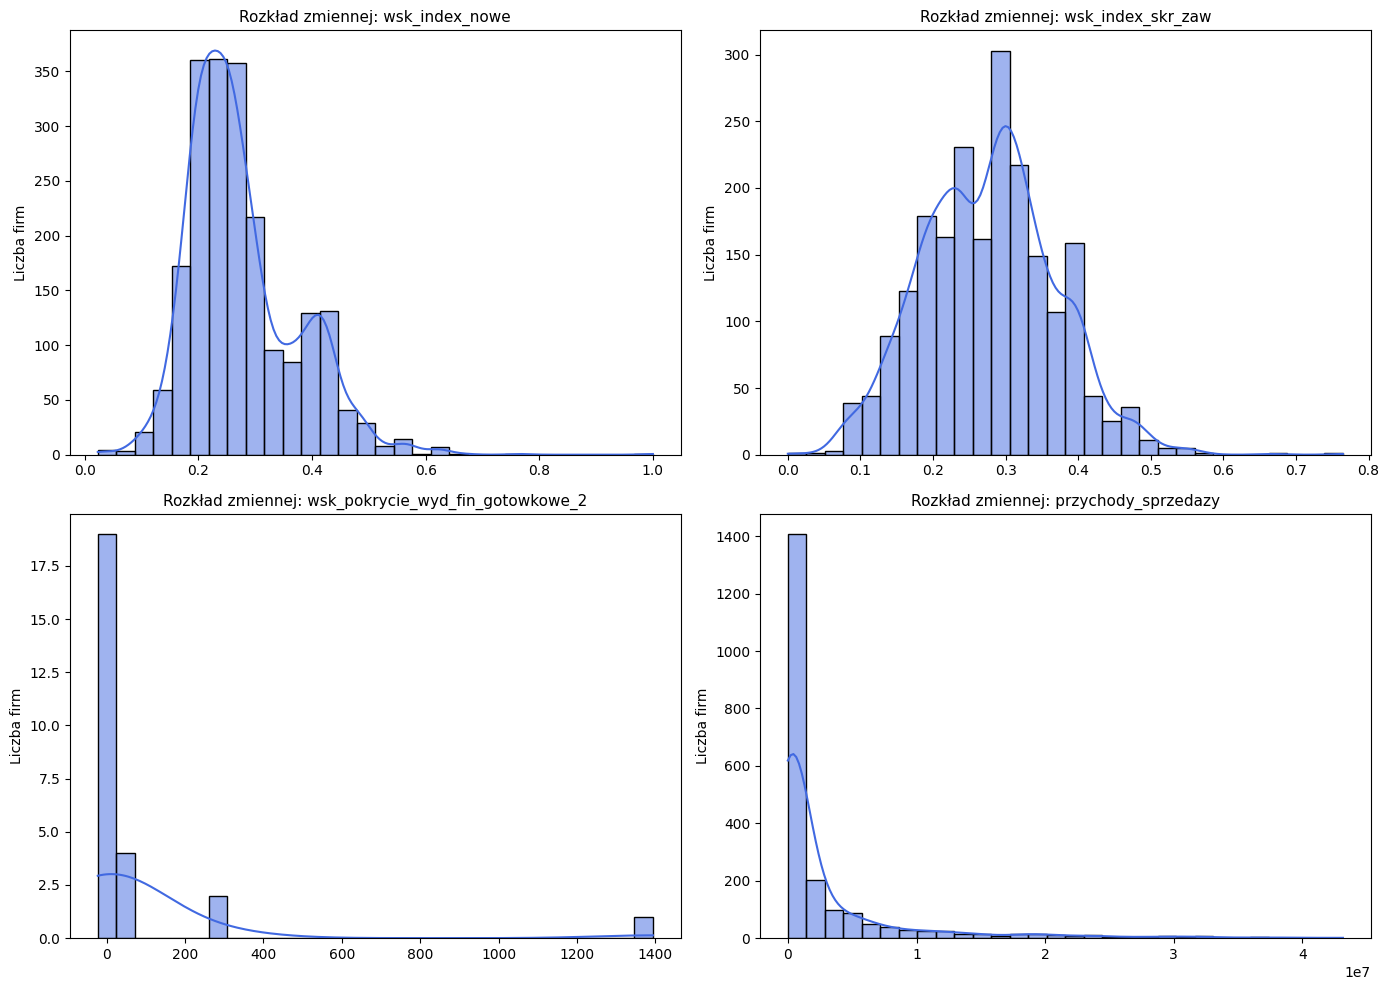

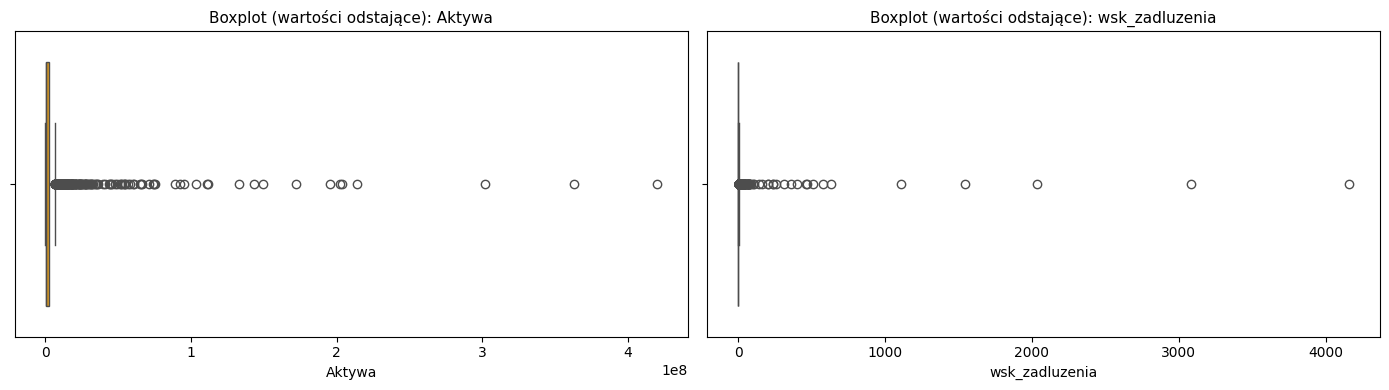

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

wybrane_cechy = [
    'wsk_index_nowe',
    'wsk_index_skr_zaw',
    'wsk_pokrycie_wyd_fin_gotowkowe_2',
    'przychody_sprzedazy'
]

plt.figure(figsize=(14, 10))
for i, col in enumerate(wybrane_cechy, 1):
  plt.subplot(2, 2, i)
  sns.histplot(df_temp[col].dropna(), kde=True, bins=30, color='royalblue')
  plt.title(f'Rozkład zmiennej: {col}', fontsize=11)
  plt.xlabel('')
  plt.ylabel('Liczba firm')

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
for i, col in enumerate(['Aktywa', 'wsk_zadluzenia'], 1):
  plt.subplot(1, 2, i)
  sns.boxplot(x=df_temp[col], color='orange')
  plt.title(f'Boxplot (wartości odstające): {col}', fontsize=11)

plt.tight_layout()
plt.show()

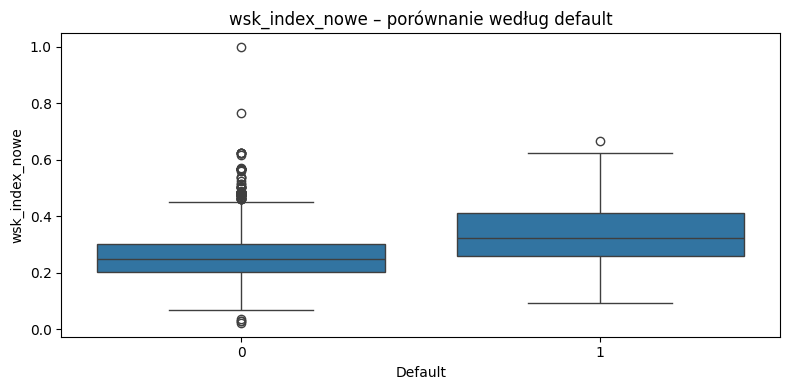

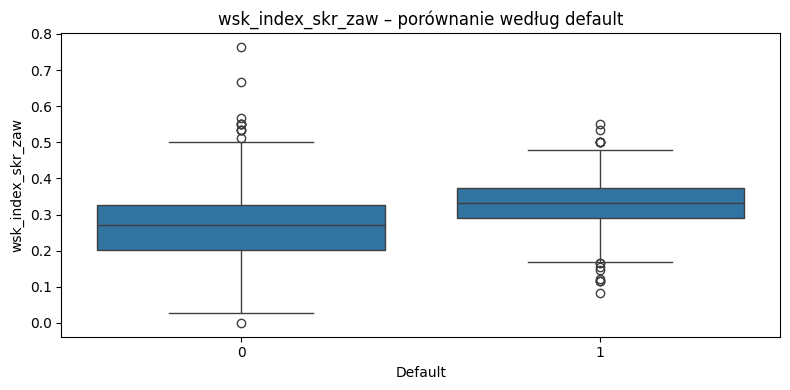

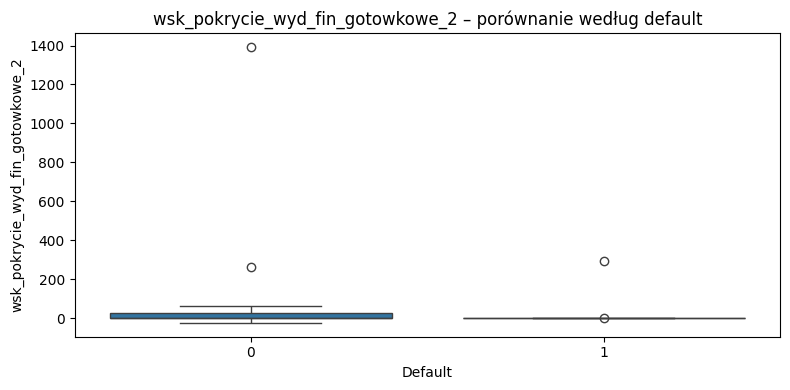

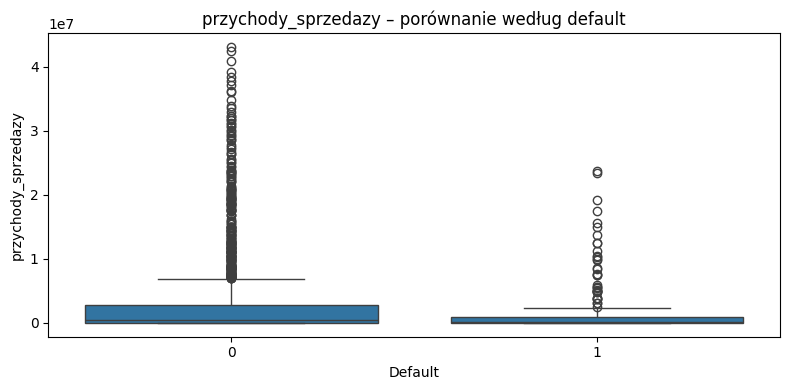

In [17]:
for col in wybrane_cechy:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=pd.DataFrame({
            col: X_train[col],
            "default": y_train
        }),
        x="default",
        y=col
    )

    plt.title(f"{col} – porównanie według default")
    plt.xlabel("Default")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [18]:
num_features = X_train.select_dtypes(include=[np.number]).columns
corr_matrix = X_train[num_features].corr().abs()

upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = []
for col in upper_tri.columns:
  high_corr = upper_tri.index[upper_tri[col] > 0.85].tolist()
  for row in high_corr:
    high_corr_pairs.append(
        {'Cecha 1': row, 'Cecha 2': col, 'Korelacja': corr_matrix.loc[row, col]}
    )

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values(
    'Korelacja', ascending=False
)

print(f'Liczba par cech silnie skorelowanych (>0.85): {len(df_high_corr)}')
display(df_high_corr)

Liczba par cech silnie skorelowanych (>0.85): 476


,Cecha 1,Cecha 2,Korelacja
399,wsk_udzial_kap_wlasnego_aktywa_1,wsk_struktura_kap_wlasnego_1,1.000000
398,wsk_kapital_do_aktywa,wsk_struktura_kap_wlasnego_1,1.000000
277,wsk_koszty_fin_przychody,wsk_poziom_kosztow_finansowych,1.000000
275,wsk_koszty_przychody,wsk_poziom_kosztow_operacyjnych,1.000000
54,wsk_ROS,wsk_rent_sprzedazy,1.000000
...,...,...,...
269,wsk_zadluzenia_pozyczki_dlugie,wsk_rotacja_aktywow_2,0.852839
268,wsk_ogolnego_zadluzenia_pozyczki,wsk_rotacja_aktywow_2,0.852819
300,dywidendy_udzialy,wsk_poziom_kapitalu_obrotowego_netto,0.851829
103,wsk_akt_generowania_got_1,wsk_rent_kapitalu,0.851680


Usunięcie stałych i identycznych kolumn będzie częścią pipeline’u poniżej. Lista jest wyznaczana na train, a podczas CV od nowa na każdym foldzie. Surowe `X_train`, `X_val`, `X_test` pozostają bez zmian.

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin

class UsunStaleIdentyczne(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.columns_ = []
        self.removed_ = []
        for col in X.columns:
            if X[col].nunique(dropna=False) <= 1 or any(
                X[col].equals(X[kept]) for kept in self.columns_
            ):
                self.removed_.append(col)
            else:
                self.columns_.append(col)
        return self

    def transform(self, X):
        return X.loc[:, self.columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_, dtype=object)

kontrola_kolumn = UsunStaleIdentyczne().fit(X_train)
print("Kolumny do usunięcia:", kontrola_kolumn.removed_)
print("Liczba pozostałych cech:", len(kontrola_kolumn.columns_))

Kolumny do usunięcia: ['szczegolnaFormaPrawna_Symbol', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Zobowiazania_dostaw_uslug_pow12m_kapitale', 'wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']
Liczba pozostałych cech: 211


# Brakujące wartości

,missing_count,missing_pct
RP_przeplywy_operacyjne,2073,98.761315
wsk_zadluzenia_gotowki_2,2073,98.761315
wsk_zysk_CF_operacyjny,2073,98.761315
wsk_pokrycie_wyd_fin_gotowkowe_2,2073,98.761315
wsk_pokrycie_zob_kr_gotowkowe_2,2073,98.761315
...,...,...
wsk_zob_oprocentowanych_aktywa_rzeczowe,0,0.000000
wsk_struktura_kap_obcego_s,0,0.000000
wsk_zob_s_aktywa_rzeczowe,0,0.000000
wsk_fin_majatku_kapitalem,0,0.000000


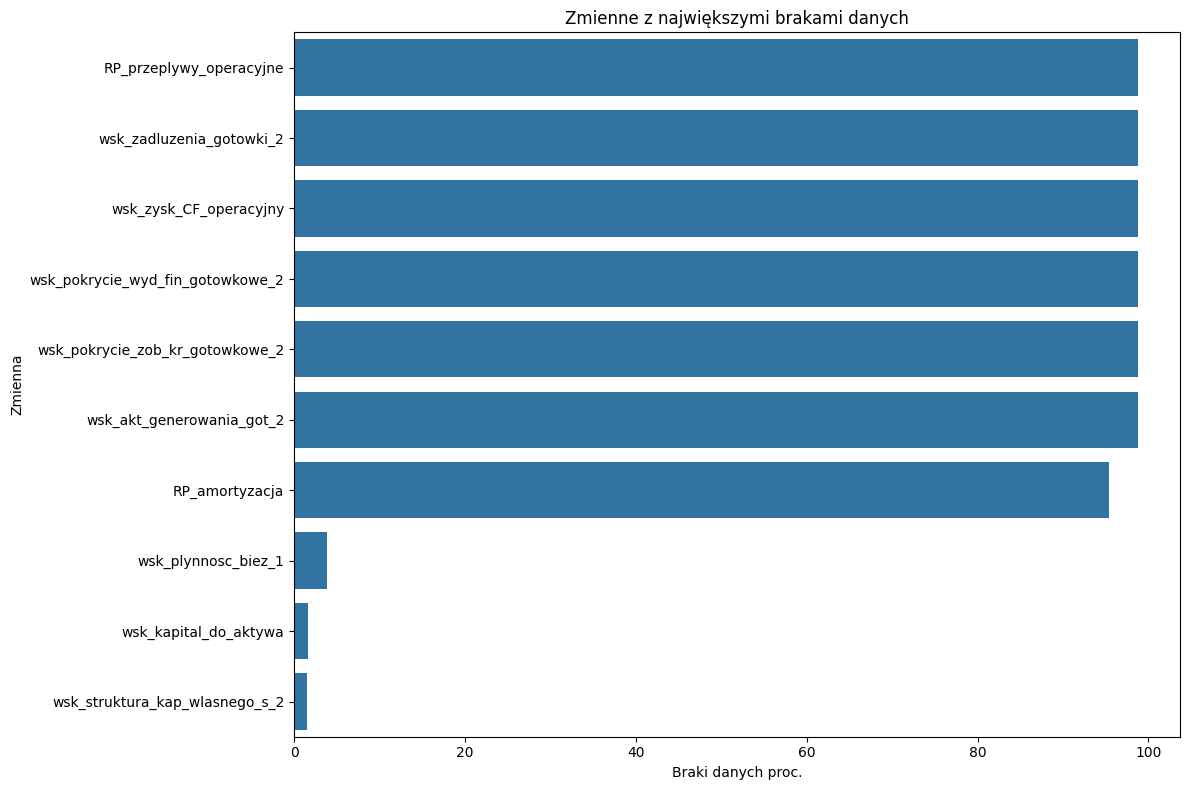

In [20]:
import seaborn as sns

missing_report = pd.DataFrame({
    "missing_count": df_temp.isna().sum(),
    "missing_pct": df_temp.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    "missing_pct",
    ascending=False
)
display(missing_report)

missing_plot = missing_report[
    missing_report["missing_count"] > 0
].head(40)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_plot.reset_index(),
    x="missing_pct",
    y="index"
)

plt.xlabel("Braki danych proc.")
plt.ylabel("Zmienna")
plt.title("Zmienne z największymi brakami danych")
plt.tight_layout()
plt.show()

Część zmiennych ma ponad 90% braków danych. Zachowujemy imputację medianą i flagi braków dla cech liczbowych oraz najczęstszą wartość dla kategorii — według wzorca z Lab 3, komórka 19. Imputery są dopasowywane dopiero wewnątrz pipeline’u. Nieskończoności traktujemy jako braki.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

# Źródło: labs/Lab_3_rating_projekt1.ipynb, komórka 19 (indeks od 0).
# Oryginalny układ imp → sc oraz imp → ohe; poniżej dostosowanie do naszych cech.
def ohe(**kw):
    try:
        return OneHotEncoder(sparse_output=False, **kw)
    except TypeError:
        return OneHotEncoder(sparse=False, **kw)

CAT_CODES = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod"]

def typy_i_braki(X):
    X = X.replace([np.inf, -np.inf], np.nan).copy()
    # Kody PKD i form prawnych są kategoriami, mimo liczbowego zapisu.
    for col in CAT_CODES:
        if col in X:
            X[col] = X[col].map(lambda value: str(value) if pd.notna(value) else np.nan)
    return X

In [22]:
df_temp.head()

,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
990,117,214,4672,-0.043649,0.283750,0.179842,2525,1153708.58,237533.3,0.0,...,0.513422,0.524742,0.947716,0.359963,0.359963,0.359963,0.486578,0.465005,0.387269,0
1086,117,214,7022,0.052319,0.232773,0.225335,6428,123349.79,0.0,0.0,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0
1651,117,214,4677,-0.069376,0.393454,0.174515,10530,1681377.19,12500.0,0.0,...,0.997973,132.499102,0.002031,0.000000,0.000000,0.000000,0.002027,-0.990441,0.997958,0
2043,117,214,7010,0.105497,0.324691,0.258041,2661,26748.11,0.0,0.0,...,0.796789,0.796789,0.255037,0.203211,0.000000,0.000000,0.203211,0.203211,0.796789,0
778,117,214,4399,0.041869,0.333747,0.297319,4673,106905.44,42169.0,0.0,...,0.837610,0.837610,0.193873,0.162390,0.000000,0.000000,0.162390,0.162390,0.731830,0


# Outlier policy
Obcinamy cechy liczbowe do kwantyli 1% i 99% wyznaczonych wyłącznie podczas `fit`. Kategorie i flagi braków nie są obcinane. Klasa poniżej przenosi dotychczasową operację `quantile` → `clip` do pipeline’u.

In [23]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.num_cols_ = X.select_dtypes(include=np.number).columns
        self.lower_caps_ = X[self.num_cols_].quantile(self.lower)
        self.upper_caps_ = X[self.num_cols_].quantile(self.upper)
        return self

    def transform(self, X):
        X = X.copy()
        X[self.num_cols_] = X[self.num_cols_].clip(
            lower=self.lower_caps_, upper=self.upper_caps_, axis=1
        )
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

# Adaptacja Pipeline / ColumnTransformer z Lab 3 (komórka 19)
# oraz Lab 1 (komórka 15). Selekcja typów następuje po usunięciu kolumn.
def preprocessing_ohe():
    pre = ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
            ("sc", StandardScaler()),
        ]), make_column_selector(dtype_include=np.number)),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("ohe", ohe(drop="first", handle_unknown="ignore")),
        ]), make_column_selector(dtype_exclude=np.number)),
    ])
    return Pipeline([
        ("typy", FunctionTransformer(typy_i_braki, feature_names_out="one-to-one")),
        ("kolumny", UsunStaleIdentyczne()),
        ("cap", QuantileCapper()),
        ("pre", pre),
    ])

preprocessing = preprocessing_ohe()
Z_train = preprocessing.fit_transform(X_train, y_train)
Z_val = preprocessing.transform(X_val)
feature_names = preprocessing.get_feature_names_out()
print("Train po przygotowaniu:", Z_train.shape)
print("Validation po przygotowaniu:", Z_val.shape)
assert Z_train.shape[1] == Z_val.shape[1] == len(feature_names)
assert np.isfinite(Z_train).all() and np.isfinite(Z_val).all()
# Test zostanie przekształcony dopiero przy końcowej ocenie.
# CV musi dostać surowe X_train i cały pipeline (preprocessing + model), nie Z_train.

Train po przygotowaniu: (2099, 582)
Validation po przygotowaniu: (451, 582)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Binning i WoE

Binning/WoE pozostawiamy do etapu wyboru modelu interpretowalnego. Gotowa implementacja `WoEBinner` znajduje się w `labs/Lab_1_scoring.ipynb`, komórka 31. Powinna zostać umieszczona w pipeline modelu i dopasowana na foldach treningowych, podobnie jak preprocessing powyżej. Nie wybieramy teraz cech na podstawie validation ani test.

In [24]:
# Zapisujemy SUROWE podziały, aby CV mogło ponownie dopasować preprocessing.
# Pliki pickle są lokalnymi artefaktami; wczytujemy tylko własne, zaufane pliki.
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
for name, values in {
    "X_train": X_train, "X_val": X_val, "X_test": X_test,
    "y_train": y_train, "y_val": y_val, "y_test": y_test,
}.items():
    values.to_pickle(ARTIFACT_DIR / f"{name}.pkl")

split_labels = pd.Series(index=df.index, dtype="object", name="split")
for name, values in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    split_labels.loc[values.index] = name
assert split_labels.notna().all()
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
split_labels.rename_axis("row_index").to_csv(ARTIFACT_DIR / "splits.csv")
print("Zapisano surowe podziały oraz indeksy w:", ARTIFACT_DIR)

Zapisano surowe podziały oraz indeksy w: /content/artifacts


# 3. Model interpretowalny — prosta regresja logistyczna

Najpierw porządkujemy zmienne, a następnie dopasowujemy bazową regresję z regularyzacją L2 (`C=1`). Źródło: **Lab 1, komórki 15, 17 i 20** (indeksy od 0); Brier i log-loss również w **Lab 2, komórka 14**. Zachowujemy dotychczasowy preprocessing i `max_iter=10000`.

## 3.1. Przegląd i wybór zmiennych

`data/variable_dictionary.csv` zawiera 217 par zmienna–obszar przepisanych z opisu PDF. Dokument klasyfikuje zmienne, ale nie zawiera wzorów wskaźników, terminów ich dostępności ani definicji defaultu. Nie rozstrzyga więc samodzielnie ryzyka leakage.

Przyjmujemy niewielki, jawny zestaw sześciu cech obejmujących różne aspekty kondycji firmy. To wybór ekspercki do modelu bazowego, bez wyszukiwania najlepszej kombinacji na validation lub teście. Szczegółowe znaczenie wskaźników i oczekiwane kierunki są hipotezami do potwierdzenia po uzyskaniu wzorów.

- Nie używamy `wsk_index_*`: brak definicji i informacji o dostępności.
- Kody PKD i form prawnych oraz schematy sprawozdań pozostają kategoriami w ogólnym pipeline, ale nie trafiają do tej małej regresji.
- Nie dokładamy wielu wariantów tych samych wskaźników. Pokrycie odsetek pomijamy na rzecz ROA jako jednego reprezentanta wyników finansowych; ich korelację pokazujemy poniżej.
- Ujemne i skrajne wartości wskaźników wymagają wyjaśnienia. Nie zamieniamy ich automatycznie na błędy: pozostawiamy przyjęty capping 1%/99% wewnątrz pipeline’u.
- Raport jakości i korelacje wyznaczamy tylko na train. Model bazowy nie zastępuje dalszej selekcji, diagnostyki i analizy ekonomicznej.

In [25]:
slownik = pd.read_csv(DATA_DIR / "variable_dictionary.csv").set_index("cecha")["obszar"]
assert slownik.index.is_unique
X_finite = X_train.replace([np.inf, -np.inf], np.nan)
raport_zmiennych = pd.DataFrame({
    "obszar_PDF": pd.Series(X_train.columns, index=X_train.columns).map(slownik).fillna("brak w PDF"),
    "typ": X_train.dtypes.astype(str),
    "braki_lub_inf_pct": X_finite.isna().mean() * 100,
    "liczba_wartosci": X_finite.nunique(),
})

# Mały zestaw ekspercki; znaki to hipotezy, a nie ograniczenia narzucone modelowi.
CECHY_LOGIT = [
    "wsk_liczba_dni_istnienia", "Aktywa", "wsk_zadluzenia",
    "wsk_plynnosc_biez_2", "wsk_ROA", "wsk_rotacja_aktywow_1",
]
OPIS_LOGIT = {
    "wsk_liczba_dni_istnienia": "Wiek firmy (dni)",
    "Aktywa": "Wielkość firmy — aktywa",
    "wsk_zadluzenia": "Zadłużenie — wzór do potwierdzenia",
    "wsk_plynnosc_biez_2": "Płynność bieżąca — wariant 2",
    "wsk_ROA": "Rentowność aktywów — ROA",
    "wsk_rotacja_aktywow_1": "Rotacja aktywów — wariant 1",
}
OCZEKIWANY_ZNAK = {
    "wsk_liczba_dni_istnienia": -1, "Aktywa": -1, "wsk_zadluzenia": 1,
    "wsk_plynnosc_biez_2": -1, "wsk_ROA": -1, "wsk_rotacja_aktywow_1": -1,
}
assert set(CECHY_LOGIT).issubset(X_train.columns)
raport_zmiennych["w_modelu_bazowym"] = raport_zmiennych.index.isin(CECHY_LOGIT)
display(raport_zmiennych.loc[CECHY_LOGIT].round(2))
print("Zmienne bez opisu w PDF:")
display(raport_zmiennych.loc[raport_zmiennych["obszar_PDF"] == "brak w PDF"])
print("Największe braki (w tym inf) na train:")
display(raport_zmiennych.sort_values("braki_lub_inf_pct", ascending=False).head(10).round(2))
print("Korelacje Spearmana wybranych cech — train:")
display(X_finite[CECHY_LOGIT].corr(method="spearman").round(2))
print("ROA a pokrycie odsetek — Spearman na train:", round(
    X_finite["wsk_ROA"].corr(X_finite["wsk_pokrycia_odsetek_zyskiem"], method="spearman"), 3
))
raport_zmiennych.to_csv(ARTIFACT_DIR / "variable_audit_train.csv", index_label="cecha")

,obszar_PDF,typ,braki_lub_inf_pct,liczba_wartosci,w_modelu_bazowym
wsk_liczba_dni_istnienia,wskaźnik finansowy,int64,0.0,1609,True
Aktywa,Pozycja bilansu,float64,0.0,1991,True
wsk_zadluzenia,wskaźnik finansowy,float64,0.0,1840,True
wsk_plynnosc_biez_2,wskaźnik finansowy,float64,0.0,1957,True
wsk_ROA,wskaźnik finansowy,float64,0.0,1421,True
wsk_rotacja_aktywow_1,wskaźnik finansowy,float64,0.0,1606,True


Zmienne bez opisu w PDF:


,obszar_PDF,typ,braki_lub_inf_pct,liczba_wartosci,w_modelu_bazowym
wsk_index_aktywne,brak w PDF,float64,0.0,948,False
wsk_index_skr_zaw,brak w PDF,float64,0.0,953,False
wsk_index_nowe,brak w PDF,float64,0.0,956,False
schemat_wsk_bilans,brak w PDF,object,0.0,3,False
schemat_wsk_rzis,brak w PDF,object,0.0,3,False


Największe braki (w tym inf) na train:


,obszar_PDF,typ,braki_lub_inf_pct,liczba_wartosci,w_modelu_bazowym
RP_przeplywy_operacyjne,Pozycja Rachunku Przepływów,float64,98.76,15,False
wsk_zysk_CF_operacyjny,wskaźnik finansowy,float64,98.76,26,False
wsk_pokrycie_wyd_fin_gotowkowe_2,wskaźnik finansowy,float64,98.76,15,False
wsk_pokrycie_zob_kr_gotowkowe_2,wskaźnik finansowy,float64,98.76,15,False
wsk_zadluzenia_gotowki_2,wskaźnik finansowy,float64,98.76,18,False
wsk_akt_generowania_got_2,wskaźnik finansowy,float64,98.76,15,False
RP_amortyzacja,Pozycja Rachunku Przepływów,float64,95.43,87,False
wsk_plynnosc_biez_1,wskaźnik finansowy,float64,33.87,1383,False
wsk_struktura_kap_wlasnego_s_2,wskaźnik finansowy,float64,4.48,1879,False
wsk_kapital_do_aktywa,wskaźnik finansowy,float64,1.81,1844,False


Korelacje Spearmana wybranych cech — train:


,wsk_liczba_dni_istnienia,Aktywa,wsk_zadluzenia,wsk_plynnosc_biez_2,wsk_ROA,wsk_rotacja_aktywow_1
wsk_liczba_dni_istnienia,1.00,0.40,0.01,-0.06,0.06,0.05
Aktywa,0.40,1.00,0.38,-0.22,0.21,0.16
wsk_zadluzenia,0.01,0.38,1.00,-0.35,0.01,0.29
wsk_plynnosc_biez_2,-0.06,-0.22,-0.35,1.00,-0.09,-0.10
wsk_ROA,0.06,0.21,0.01,-0.09,1.00,0.36
wsk_rotacja_aktywow_1,0.05,0.16,0.29,-0.10,0.36,1.00


ROA a pokrycie odsetek — Spearman na train: 0.93


## 3.2. Dopasowanie modelu

Adaptacja Lab 1, komórka 15: `Pipeline([("pre", ...), ("lr", LogisticRegression(...))])`. Zamiast dopasowywać model do surowych danych bez transformacji, korzystamy z gotowego `preprocessing_ohe()`. Nie stosujemy oversamplingu ani wag klas — model ma estymować prawdopodobieństwo dla obserwowanej populacji. Dostosowanie do 4% będzie osobnym etapem.

In [26]:
from sklearn.linear_model import LogisticRegression

model_inter = Pipeline([
    ("pre", preprocessing_ohe()),
    ("lr", LogisticRegression(C=1.0, max_iter=10000)),
])
model_inter.fit(X_train[CECHY_LOGIT], y_train)
print("Klasy modelu:", model_inter.named_steps["lr"].classes_, "→ kolumna 1 = P(default)")
p_inter_train = model_inter.predict_proba(X_train[CECHY_LOGIT])[:, 1]
p_inter_val = model_inter.predict_proba(X_val[CECHY_LOGIT])[:, 1]

Klasy modelu: [0 1] → kolumna 1 = P(default)


## 3.3. Ocena train / validation i stabilność w CV

Funkcja `ocena` bazuje na Lab 1, komórka 17, z dodatkowymi metrykami projektu. PR-AUC raportujemy jako average precision. Punktem odniesienia jest stała PD równa częstości defaultów **na train**.

W pięciu foldach ponownie uczymy cały pipeline na surowych danych. Nie stroimy hiperparametrów. Wyniki dotyczą modelu bazowego i służą ocenie wstępnej; test pozostaje niewykorzystany.

In [27]:
# Lab 1, komórka 17 — rozszerzenie o PR-AUC, log-loss i Brier.
def ocena(y_true, p):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    auc = roc_auc_score(y_true, p)
    fpr, tpr, _ = roc_curve(y_true, p)
    return {
        "AUC": auc, "Gini": 2 * auc - 1, "KS": float(np.max(tpr - fpr)),
        "PR-AUC (AP)": average_precision_score(y_true, p),
        "log-loss": log_loss(y_true, p), "Brier": brier_score_loss(y_true, p),
        "średnia PD": p.mean(), "default rate": y_true.mean(),
    }

wyniki_inter = pd.DataFrame({
    "train": ocena(y_train, p_inter_train),
    "validation": ocena(y_val, p_inter_val),
    "stała PD — validation": ocena(y_val, np.full(len(y_val), y_train.mean())),
}).T
display(wyniki_inter.round(4))

from sklearn.base import clone
wiersze_cv = []
for fold, (a, b) in enumerate(cv.split(X_train, y_train), start=1):
    model_fold = clone(model_inter)
    model_fold.fit(X_train.iloc[a][CECHY_LOGIT], y_train.iloc[a])
    p_fold = model_fold.predict_proba(X_train.iloc[b][CECHY_LOGIT])[:, 1]
    wiersze_cv.append({"fold": fold, **ocena(y_train.iloc[b], p_fold)})
wyniki_cv_inter = pd.DataFrame(wiersze_cv).set_index("fold")
display(wyniki_cv_inter.round(4))
print("CV — średnia, odchylenie standardowe i wariancja:")
display(wyniki_cv_inter.agg(["mean", "std", "var"]).round(4))
wyniki_inter.to_csv(ARTIFACT_DIR / "logit_metrics.csv")
wyniki_cv_inter.to_csv(ARTIFACT_DIR / "logit_cv.csv")

,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
train,0.6906,0.3812,0.2871,0.2703,0.3603,0.1066,0.1296,0.1296
validation,0.6807,0.3614,0.3316,0.2661,0.3710,0.1104,0.1231,0.1308
stała PD — validation,0.5000,0.0000,0.0000,0.1308,0.3880,0.1137,0.1296,0.1308


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
fold,,,,,,,,
1,0.6413,0.2826,0.2587,0.2412,0.3730,0.1099,0.1316,0.1286
2,0.7007,0.4014,0.2990,0.3555,0.3433,0.0998,0.1347,0.1286
3,0.6459,0.2919,0.2249,0.2360,0.3770,0.1123,0.1290,0.1310
4,0.7370,0.4741,0.3938,0.2861,0.3597,0.1076,0.1246,0.1310
5,0.6777,0.3555,0.3332,0.2424,0.3654,0.1084,0.1270,0.1289


CV — średnia, odchylenie standardowe i wariancja:


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
mean,0.6805,0.3611,0.3019,0.2722,0.3637,0.1076,0.1294,0.1296
std,0.0398,0.0796,0.0656,0.0507,0.0132,0.0047,0.0040,0.0013
var,0.0016,0.0063,0.0043,0.0026,0.0002,0.0000,0.0000,0.0000


## 3.4. Współczynniki i kierunki wpływu

Adaptacja Lab 1, komórka 20: współczynniki, ilorazy szans i opis cech. Dla wybranych cech liczbowych β opisuje zmianę log-szans przy wzroście o jedno odchylenie standardowe **po cappingu i imputacji**, przy pozostałych cechach stałych. Regularyzacja L2 ściąga współczynniki do zera. Nie traktujemy ich jako efektów przyczynowych ani testów istotności.

Hipotezy znaków służą do sprawdzenia modelu, nie do automatycznego odrzucania cech. Zależności mogą różnić się między branżami; szczególnie rotacja aktywów nie ma uniwersalnego kierunku. Jest to model bazowy — pełna interpretacja lokalna, monotoniczność i dalsza diagnostyka pozostają do wykonania.

,cecha,beta,opis,OR = exp(beta),kierunek,oczekiwany_znak,zgodny_z_hipoteza
2,wsk_zadluzenia,0.3384,Zadłużenie — wzór do potwierdzenia,1.4027,wzrost ryzyka,1,tak
4,wsk_ROA,-0.3297,Rentowność aktywów — ROA,0.7191,spadek ryzyka,-1,tak
0,wsk_liczba_dni_istnienia,-0.2194,Wiek firmy (dni),0.8030,spadek ryzyka,-1,tak
1,Aktywa,-0.2134,Wielkość firmy — aktywa,0.8078,spadek ryzyka,-1,tak
3,wsk_plynnosc_biez_2,0.0680,Płynność bieżąca — wariant 2,1.0703,wzrost ryzyka,-1,do analizy
5,wsk_rotacja_aktywow_1,0.0295,Rotacja aktywów — wariant 1,1.0300,wzrost ryzyka,-1,do analizy


Wyraz wolny: -2.0299


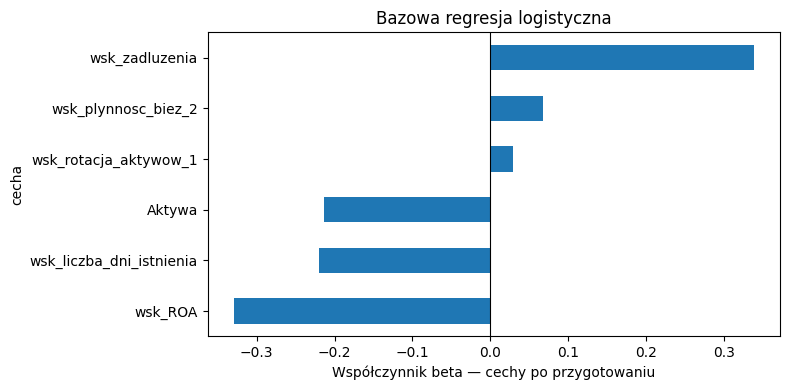

In [28]:
# Lab 1, komórka 20 — uproszczona tabela dla sześciu cech liczbowych.
pre, lr = model_inter.named_steps["pre"], model_inter.named_steps["lr"]
nazwy = [s.split("__", 1)[1] for s in pre.get_feature_names_out()]
tabela_beta = pd.DataFrame({"cecha": nazwy, "beta": lr.coef_.ravel()})
tabela_beta["opis"] = tabela_beta["cecha"].map(OPIS_LOGIT)
tabela_beta["OR = exp(beta)"] = np.exp(tabela_beta["beta"])
tabela_beta["kierunek"] = np.where(tabela_beta["beta"] > 0, "wzrost ryzyka",
                                   np.where(tabela_beta["beta"] < 0, "spadek ryzyka", "brak wpływu"))
tabela_beta["oczekiwany_znak"] = tabela_beta["cecha"].map(OCZEKIWANY_ZNAK)
tabela_beta["zgodny_z_hipoteza"] = np.where(
    tabela_beta["oczekiwany_znak"].isna(), "nie dotyczy",
    np.where(np.sign(tabela_beta["beta"]) == tabela_beta["oczekiwany_znak"], "tak", "do analizy"),
)
tabela_beta = tabela_beta.sort_values("beta", key=np.abs, ascending=False)
display(tabela_beta.round(4))
print("Wyraz wolny:", round(lr.intercept_[0], 4))
tabela_beta.to_csv(ARTIFACT_DIR / "logit_coefficients.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
tabela_beta.sort_values("beta").plot.barh(x="cecha", y="beta", ax=ax, legend=False)
ax.set_xlabel("Współczynnik beta — cechy po przygotowaniu")
ax.set_title("Bazowa regresja logistyczna")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 3.5. Wstępne wnioski

- AUC: train **0,691**, validation **0,681**, średnia 5-fold CV **0,681**. Nie widać dużej różnicy train–validation, ale jest to ocena wstępna.
- Na validation regresja poprawia log-loss (**0,3710** vs **0,3879**) i Brier (**0,1104** vs **0,1137**) względem stałej PD wyznaczonej na train.
- Znaki dla zadłużenia, ROA, wieku i aktywów są zgodne z przyjętymi hipotezami. Płynność i rotacja mają przeciwne znaki; wymagają sprawdzenia wzorów, rozkładów, zależności z innymi cechami i ewentualnej nieliniowości. Nie odrzucamy ich wyłącznie z powodu znaku.
- Model wykorzystuje sześć cech; nie używa nieopisanych indeksów ani setek kategorii PKD. To czytelny punkt odniesienia, a nie zakończona selekcja modelu.
- Test nie został użyty do oceny. Nie wykonano jeszcze kalibracji statystycznej, dostosowania do 4%, analizy lokalnej ani porównania z black-box.


# 4. Kalibracja regresji logistycznej

Źródła: **Lab 2, komórki 14 i 20** — miary i reliability; **Lab 2, komórki 22 i 24** oraz **Lab 3, komórka 48** — Platt, isotonic i porównanie w CV; **Lab 2, komórka 22** — przesunięcie logitu. Indeksy komórek liczymy od 0.

Model bazowy pozostaje dopasowany wyłącznie na train. Na jego predykcjach dla validation wykonujemy wewnętrzne, stratyfikowane 5-fold CV kalibratorów. W każdym foldzie kalibrator uczy się na części validation, a oceniany jest na pozostałej części. Porównujemy także brak kalibracji, ponieważ kalibracja nie musi poprawiać regresji logistycznej.

Wybieramy najniższy średni log-loss z foldów. Ocena po wyborze na tych samych foldach jest wstępna i może być optymistyczna. Końcowe potwierdzenie będzie na teście, po ustaleniu obu modeli. Nie oceniamy jakości kalibratora wyłącznie na danych, na których został dopasowany.

## 4.1. Miary kalibracji

CITL to przesunięcie interceptu przy nachyleniu ustalonym na 1 (ideał 0); slope to nachylenie pomocniczej regresji na logitach z własnym interceptem (ideał 1). ECE używa przedziałów równej szerokości, ACE — równolicznych. Miary są wrażliwe na małą próbę i wybór przedziałów. W logarytmach zabezpieczamy PD przez `EPS=1e-6`.

In [29]:
from scipy.optimize import brentq
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression

EPS = 1e-6

# Lab 2, komórka 14: ECE, ACE, CITL i slope.
def ece(y_true, p, n_bins=10):
    y_true, p = np.asarray(y_true), np.asarray(p)
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean())
                     for m in range(n_bins) if np.any(idx == m)))

def przedzialy_rowne_liczebnie(p, n_bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:  # stałe PD — jeden przedział
        return np.zeros(len(p), dtype=int), 1
    return np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2), len(edges) - 1

def ace(y_true, p, n_bins=10):
    y_true, p = np.asarray(y_true), np.asarray(p)
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean())
                     for m in range(k) if np.any(idx == m)))

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def przesuniecie(p, cel):
    z = _z(p)
    return brentq(lambda d: expit(z + d).mean() - cel, -40, 40)

def cox(y_true, p):
    y_true = np.asarray(y_true)
    z = _z(p)
    a = przesuniecie(p, y_true.mean())
    if np.ptp(z) < 1e-9:
        return a, np.nan
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y_true).coef_[0, 0]
    return a, b

def miary_kalibracji(y_true, p):
    y_true, p = np.asarray(y_true), np.asarray(p)
    a, b = cox(y_true, p)
    return {
        **ocena(y_true, np.clip(p, EPS, 1 - EPS)),
        "ECE": ece(y_true, p), "ACE": ace(y_true, p),
        "CITL a": a, "nachylenie b": b,
    }

display(pd.DataFrame({"przed kalibracją — validation": miary_kalibracji(y_val, p_inter_val)}).T.round(4))

,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate,ECE,ACE,CITL a,nachylenie b
przed kalibracją — validation,0.6807,0.3614,0.3316,0.2661,0.371,0.1104,0.1231,0.1308,0.0268,0.0372,0.0743,0.8596


## 4.2. Platt i isotonic — porównanie na validation

Adaptacja `FIT`, `zastosuj` i pętli CV z Lab 3, komórka 48. Platt dopasowuje regresję do logitu PD, jak w Lab 2, komórka 24. Isotonic jest bardziej elastyczna, ale przy kilkudziesięciu defaultach może być niestabilna i tworzyć remisy. Liczebności oraz rozrzut log-loss pokazujemy jawnie. Predykcje OOF w tej sekcji dotyczą **kalibratorów na validation**, a nie ponownego uczenia modelu bazowego.

In [30]:
FIT = {
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(
        out_of_bounds="clip", y_min=EPS, y_max=1-EPS
    ).fit(p, y),
}

def zastosuj(metoda, kal, p):
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    return kal.predict(p)

y_cal = np.asarray(y_val)
p_cal_raw = np.asarray(p_inter_val)
cv_cal = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
foldy_kal = list(cv_cal.split(p_cal_raw.reshape(-1, 1), y_cal))
P_CAL_OOF = {met: np.full(len(y_cal), np.nan) for met in FIT}
P4_CAL_OOF = {met: np.full(len(y_cal), np.nan) for met in FIT}
wiersze_kal = []
for fold, (a, b) in enumerate(foldy_kal, start=1):
    for metoda in FIT:
        kal = FIT[metoda](y_cal[a], p_cal_raw[a])
        q = zastosuj(metoda, kal, p_cal_raw[b])
        P_CAL_OOF[metoda][b] = q
        # Także przesunięcie do 4% wyznaczamy bez danych ocenianego foldu.
        q_ref = zastosuj(metoda, kal, p_cal_raw[a])
        delta_fold = przesuniecie(q_ref, TARGET_PD)
        P4_CAL_OOF[metoda][b] = expit(_z(q) + delta_fold)
        wiersze_kal.append({
            "fold": fold, "metoda": metoda,
            "n_kalibracja": len(a), "defaulty_kalibracja": int(y_cal[a].sum()),
            "n_ocena": len(b), "defaulty_ocena": int(y_cal[b].sum()),
            "log-loss": log_loss(y_cal[b], np.clip(q, EPS, 1-EPS)),
            "Brier": brier_score_loss(y_cal[b], q),
        })
for p in [*P_CAL_OOF.values(), *P4_CAL_OOF.values()]:
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
wyniki_cal_cv = pd.DataFrame(wiersze_kal)
porownanie_cal = wyniki_cal_cv.groupby("metoda").agg(
    logloss_mean=("log-loss", "mean"), logloss_std=("log-loss", "std"),
    Brier_mean=("Brier", "mean"), Brier_std=("Brier", "std"),
).sort_values("logloss_mean")
METODA_KAL = porownanie_cal.index[0]
print("Validation:", len(y_cal), "obserwacji i", int(y_cal.sum()), "defaultów")
display(wyniki_cal_cv.round(4))
display(porownanie_cal.round(5))
print("Wybrana metoda według średniego log-loss:", METODA_KAL)
print("To wybór wstępny; różnice i rozrzut trzeba ocenić wraz z prostotą metod.")
tabela_cal_oof = pd.DataFrame({met: miary_kalibracji(y_cal, p) for met, p in P_CAL_OOF.items()}).T
print("Diagnostyka na predykcjach OOF kalibratorów:")
display(tabela_cal_oof.round(4))

Validation: 451 obserwacji i 59 defaultów


,fold,metoda,n_kalibracja,defaulty_kalibracja,n_ocena,defaulty_ocena,log-loss,Brier
0,1,bez kalibracji,360,47,91,12,0.3804,0.1157
1,1,Platt,360,47,91,12,0.3789,0.1148
2,1,izotoniczna,360,47,91,12,0.3816,0.1135
3,2,bez kalibracji,361,48,90,11,0.3513,0.1029
4,2,Platt,361,48,90,11,0.3535,0.1031
5,2,izotoniczna,361,48,90,11,0.3374,0.0978
6,3,bez kalibracji,361,47,90,12,0.4069,0.1227
7,3,Platt,361,47,90,12,0.4186,0.1265
8,3,izotoniczna,361,47,90,12,0.5086,0.1201
9,4,bez kalibracji,361,47,90,12,0.3359,0.0984


,logloss_mean,logloss_std,Brier_mean,Brier_std
metoda,,,,
bez kalibracji,0.37097,0.02779,0.11042,0.00978
Platt,0.37576,0.02813,0.11166,0.01009
izotoniczna,0.39214,0.06830,0.11003,0.00839


Wybrana metoda według średniego log-loss: bez kalibracji
To wybór wstępny; różnice i rozrzut trzeba ocenić wraz z prostotą metod.
Diagnostyka na predykcjach OOF kalibratorów:


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate,ECE,ACE,CITL a,nachylenie b
bez kalibracji,0.6807,0.3614,0.3316,0.2661,0.3710,0.1104,0.1231,0.1308,0.0268,0.0372,0.0743,0.8596
Platt,0.6742,0.3485,0.3232,0.2526,0.3758,0.1117,0.1312,0.1308,0.0185,0.0350,-0.0037,0.7819
izotoniczna,0.6459,0.2919,0.3079,0.2151,0.3921,0.1100,0.1281,0.1308,0.0170,0.0510,0.0265,0.3466


## 4.3. Dostosowanie do 4% — zewnętrzne założenie biznesowe

Po wyborze dopasowujemy kalibrator do całego validation. Populacją referencyjną do przesunięcia logitu jest validation; nie wykorzystujemy testu. `delta` ustawia średnią PD tej populacji na 4%.

Dane mają około 13% defaultów. Dostosowanie do 4% jest oddzielnym scenariuszem dla docelowego portfela, a nie dowodem poprawy kalibracji na obecnych danych. Zbiór nie pozwala zweryfikować, czy przeniesienie do takiego portfela jest uzasadnione. Nie stosujemy tu automatycznie korekty wynikającej z ilorazu częstości klas.

Tabela jakości wykorzystuje predykcje OOF i przesunięcia wyznaczane osobno na częściach treningowych validation. Ich średnia nie musi być dokładnie 4%. Końcowy kalibrator i `DELTA_LOGIT` wyznaczone na całym validation są przygotowane do późniejszej oceny testowej; dokładne 4% na validation jest jedynie sprawdzeniem dopasowania parametru.

Jedno stałe przesunięcie zachowuje ranking (z dokładnością numeryczną). Różne przesunięcia i kalibratory w foldach mogą zmienić ranking po złączeniu predykcji OOF. Isotonic może dodatkowo tworzyć remisy.

In [31]:
KAL_LOGIT = FIT[METODA_KAL](y_cal, p_cal_raw)
p_val_stat = zastosuj(METODA_KAL, KAL_LOGIT, p_cal_raw)
DELTA_LOGIT = przesuniecie(p_val_stat, TARGET_PD)
p_val_4 = expit(_z(p_val_stat) + DELTA_LOGIT)
assert np.isclose(p_val_4.mean(), TARGET_PD, atol=1e-10)
assert np.isclose(roc_auc_score(y_cal, p_val_stat), roc_auc_score(y_cal, p_val_4), atol=1e-12)

referencja_4 = pd.DataFrame({
    "etap": ["model bazowy", f"statystyczna: {METODA_KAL}", "dostosowanie do 4%"],
    "średnia PD": [p_cal_raw.mean(), p_val_stat.mean(), p_val_4.mean()],
    "default rate": [y_cal.mean()] * 3,
})
print("Populacja referencyjna — validation; to sprawdzenie dopasowania, nie niezależna ocena:")
display(referencja_4.round(5))
print("Przesunięcie logitu delta:", round(DELTA_LOGIT, 4))

P_DIAG = {
    "przed kalibracją": p_cal_raw,
    f"po statystycznej: {METODA_KAL} — OOF": P_CAL_OOF[METODA_KAL],
    "po dostosowaniu do 4% — OOF": P4_CAL_OOF[METODA_KAL],
}
tabela_pre_post = pd.DataFrame({lab: miary_kalibracji(y_cal, p) for lab, p in P_DIAG.items()}).T
display(tabela_pre_post.round(4))

def pd_logit_po_kalibracji(X, do_4proc=False):
    # Gotowe do użycia na teście dopiero po ustaleniu całego rozwiązania.
    p = model_inter.predict_proba(X[CECHY_LOGIT])[:, 1]
    p = zastosuj(METODA_KAL, KAL_LOGIT, p)
    return expit(_z(p) + DELTA_LOGIT) if do_4proc else p

wyniki_cal_cv.to_csv(ARTIFACT_DIR / "logit_calibration_folds.csv", index=False)
tabela_cal_oof.to_csv(ARTIFACT_DIR / "logit_calibration_methods_oof.csv")
tabela_pre_post.to_csv(ARTIFACT_DIR / "logit_calibration_pre_post_oof.csv")
referencja_4.to_csv(ARTIFACT_DIR / "logit_calibration_reference.csv", index=False)
import json
(ARTIFACT_DIR / "logit_calibration_config.json").write_text(json.dumps({
    "method": METODA_KAL, "delta": float(DELTA_LOGIT), "target_pd": TARGET_PD,
    "reference": "validation", "seed": RNG_SEED,
    "note": "Configuration only; fitted estimators remain in notebook memory.",
}, ensure_ascii=False, indent=2))

Populacja referencyjna — validation; to sprawdzenie dopasowania, nie niezależna ocena:


,etap,średnia PD,default rate
0,model bazowy,0.12311,0.13082
1,statystyczna: bez kalibracji,0.12311,0.13082
2,dostosowanie do 4%,0.04000,0.13082


Przesunięcie logitu delta: -1.2983


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate,ECE,ACE,CITL a,nachylenie b
przed kalibracją,0.6807,0.3614,0.3316,0.2661,0.3710,0.1104,0.1231,0.1308,0.0268,0.0372,0.0743,0.8596
po statystycznej: bez kalibracji — OOF,0.6807,0.3614,0.3316,0.2661,0.3710,0.1104,0.1231,0.1308,0.0268,0.0372,0.0743,0.8596
po dostosowaniu do 4% — OOF,0.6806,0.3611,0.3411,0.2667,0.4441,0.1194,0.0400,0.1308,0.0985,0.0908,1.3729,0.8580


205

## 4.4. Reliability i rozkład PD

Adaptacja Lab 2, komórka 20. Pokazujemy przedziały równoliczne na skali liniowej i logarytmicznej oraz histogram. Na skali logarytmicznej nie można pokazać zaobserwowanej częstości 0 — takie punkty pozostają w tabeli i na wykresie liniowym; ich liczbę podajemy w legendzie. Nie zastępujemy zer fikcyjnym dodatnim DR. Przy małej liczbie defaultów punkty są obarczone dużą niepewnością.

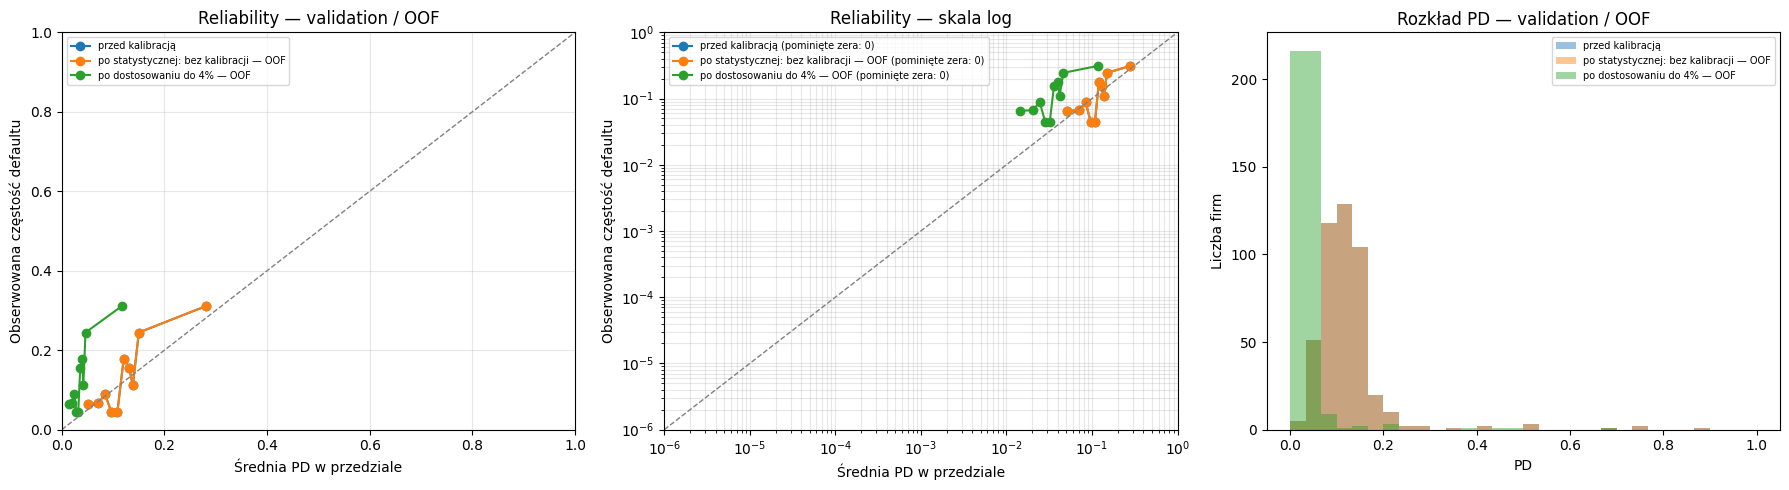

,średnia PD,DR,etap
0,0.0505,0.0652,przed kalibracją
1,0.0712,0.0667,przed kalibracją
2,0.0842,0.0889,przed kalibracją
3,0.0967,0.0444,przed kalibracją
4,0.1084,0.0444,przed kalibracją
5,0.1205,0.1778,przed kalibracją
6,0.1315,0.1556,przed kalibracją
7,0.1384,0.1111,przed kalibracją
8,0.1501,0.2444,przed kalibracją
9,0.2812,0.3111,przed kalibracją


Wybór metody: bez kalibracji
Liczba defaultów na validation: 59 — ostrożnie z elastyczną isotonic.
Po 4%: zmiana Brier względem statystycznej OOF = 0.00897
Końcowa ocena testowa oraz ratingi i ich backtest pozostają do realizacji.


In [32]:
def reliability(ax, y_true, p, label, n_bins=10, log_scale=False):
    obs, pred = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
    mask = (obs > 0) & (pred > 0) if log_scale else np.ones(len(obs), dtype=bool)
    suffix = f" (pominięte zera: {int((~mask).sum())})" if log_scale else ""
    ax.plot(pred[mask], obs[mask], marker="o", label=label + suffix)
    return pd.DataFrame({"średnia PD": pred, "DR": obs})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tabele_reliability = []
for lab, p in P_DIAG.items():
    tab = reliability(axes[0], y_cal, p, lab)
    tab["etap"] = lab
    tabele_reliability.append(tab)
    reliability(axes[1], y_cal, p, lab, log_scale=True)
    axes[2].hist(p, bins=np.linspace(0, 1, 31), alpha=0.45, label=lab)
for ax in axes[:2]:
    ax.plot([EPS, 1], [EPS, 1], "--", color="gray", linewidth=1)
    ax.set_xlabel("Średnia PD w przedziale")
    ax.set_ylabel("Obserwowana częstość defaultu")
    ax.grid(alpha=0.3, which="both")
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Reliability — validation / OOF")
axes[1].set(xscale="log", yscale="log", xlim=(EPS, 1), ylim=(EPS, 1), title="Reliability — skala log")
axes[2].set(xlabel="PD", ylabel="Liczba firm", title="Rozkład PD — validation / OOF")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "logit_calibration_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
tab_reliability = pd.concat(tabele_reliability, ignore_index=True)
display(tab_reliability.round(4))
tab_reliability.to_csv(ARTIFACT_DIR / "logit_reliability_oof.csv", index=False)

print("Wybór metody:", METODA_KAL)
print("Liczba defaultów na validation:", int(y_cal.sum()), "— ostrożnie z elastyczną isotonic.")
print("Po 4%: zmiana Brier względem statystycznej OOF =", round(
    tabela_pre_post.iloc[2]["Brier"] - tabela_pre_post.iloc[1]["Brier"], 5
))
print("Końcowa ocena testowa oraz ratingi i ich backtest pozostają do realizacji.")

## 4.5. Wnioski z kalibracji modelu bazowego

- Validation zawiera **451 obserwacji i 59 defaultów**. To mała próba, szczególnie dla elastycznej kalibracji izotonicznej.
- W porównaniu pięciu foldów najniższy średni log-loss uzyskał wariant **bez dodatkowej kalibracji**. Na złączonych predykcjach OOF log-loss wynosi około **0,3710** bez kalibracji, **0,3758** dla Platta i **0,3921** dla isotonic.
- Isotonic ma nieznacznie niższy Brier, ale gorszy log-loss. Nie wybieramy metody tylko na podstawie jednego korzystnego wskaźnika. Kryterium wyboru ustalono jako średni log-loss z foldów; prostota również przemawia za zachowaniem surowej regresji.
- Końcowe przesunięcie logitu wynosi około **−1,2983** i ustawia średnią PD na validation na **4%**. W ocenie OOF Brier rośnie z około **0,1104** do **0,1194**, a log-loss z **0,3710** do **0,4441**. Oznacza to pogorszenie zgodności z default rate około 13%, nie niepowodzenie samego obliczenia przesunięcia.
- Zmiana AUC w połączonych predykcjach OOF wynika z różnych przesunięć między foldami. Dla jednego końcowego przesunięcia na całym validation sprawdzono zachowanie AUC.
- Wybór i wyniki są wstępne. Brakuje niezależnej oceny testowej po zamknięciu wyboru obu modeli oraz ratingów i ich oceny.


# 5. Black-box i uzupełnienie interpretacji — kod z laboratoriów

Przenosimy bloki z Lab 3–6 z oznaczeniem numerów komórek (indeksy od 0). Funkcje PDP, ICE i miary naruszeń są zachowane z Lab 5. Nie przenosimy generatora syntetycznych danych, podziału czasowego ani gotowych wniosków z labów.

## 5.1. Boosting i strojenie

Źródło: **Lab 3, komórka 33**. Zachowujemy `HistGradientBoostingClassifier` oraz siatkę liczby iteracji. Używamy tych samych sześciu cech co w regresji, żeby uzyskać czytelne porównanie algorytmów, a nie jednocześnie algorytmów i różnych zestawów cech. Nie oznacza to, że sześć cech jest optymalnym zestawem black-box.

Konieczne adaptacje poza nazwami: wspólny preprocessing obsługujący nieskończoności i capping; strojenie w CV **na train**, żeby zachować validation dla kalibracji. `min_samples_leaf=50` dostosowujemy do mniejszej próby. Wynik CV wybrany spośród kilku wariantów może być optymistyczny; test będzie niezależnym sprawdzeniem. Nie zmieniamy teraz regresji na podstawie wyniku black-box.

In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

# Lab 3, komórka 33: zmiana preprocessingu, liczebności liścia oraz miejsca strojenia.
def preprocessing_drzewa():
    return preprocessing_ohe()

def model_black_box(n_drzew):
    clf = HistGradientBoostingClassifier(
        max_iter=n_drzew, learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=50,
        l2_regularization=2.0, early_stopping=False, random_state=RNG_SEED,
    )
    return Pipeline([("pre", preprocessing_drzewa()), ("clf", clf)])

# Aliasy umożliwiają zachowanie kodu dalszych laboratoriów prawie bez zmian.
FEATURES = list(CECHY_LOGIT)
X_tr, X_va = X_train[FEATURES], X_val[FEATURES]
y_tr, y_va = y_train, y_val
baseline = model_inter
KOL = {"logit": "#3E5C76", "black-box": "#A3262C"}

wiersze = []
for n_drzew in [100, 200, 400, 800]:
    wyniki = -cross_val_score(model_black_box(n_drzew), X_tr, y_tr,
                             cv=cv, scoring="neg_log_loss", n_jobs=1)
    wiersze.append({"liczba drzew": n_drzew, "log-loss (CV train)": wyniki.mean(),
                    "odch. std.": wyniki.std(ddof=1)})
tuning = pd.DataFrame(wiersze).set_index("liczba drzew")
display(tuning.round(5))
N_DRZEW = int(tuning["log-loss (CV train)"].idxmin())
black_box = model_black_box(N_DRZEW).fit(X_tr, y_tr)
print(f"Wybrano {N_DRZEW} iteracji boostingu.")
P_MODELE = {
    "logit": {"train": p_inter_train, "valid": p_inter_val},
    "black-box": {"train": black_box.predict_proba(X_tr)[:, 1],
                  "valid": black_box.predict_proba(X_va)[:, 1]},
}
porownanie_modeli = pd.DataFrame({
    f"{m} ({s})": ocena(y_tr if s == "train" else y_va, p)
    for m, serie in P_MODELE.items() for s, p in serie.items()
}).T
display(porownanie_modeli.round(4))

# Lab 3, komórka 38: ta sama pętla, ale StratifiedKFold zamiast TimeSeriesSplit.
wiersze = []
for fold, (a, b) in enumerate(cv.split(X_tr, y_tr), start=1):
    m = model_black_box(N_DRZEW).fit(X_tr.iloc[a], y_tr.iloc[a])
    p = m.predict_proba(X_tr.iloc[b])[:, 1]
    wiersze.append({"fold": fold, **ocena(y_tr.iloc[b], p)})
cv_black_box = pd.DataFrame(wiersze).set_index("fold")
display(cv_black_box.round(4))
display(cv_black_box.agg(["mean", "std", "var"]).round(4))
print("CV black-box po wyborze hiperparametru: wynik wstępny, bez niezależności od strojenia.")
tuning.to_csv(ARTIFACT_DIR / "black_box_tuning.csv")
porownanie_modeli.to_csv(ARTIFACT_DIR / "models_train_validation.csv")
cv_black_box.to_csv(ARTIFACT_DIR / "black_box_cv.csv")

,log-loss (CV train),odch. std.
liczba drzew,,
100,0.35062,0.01654
200,0.35449,0.01726
400,0.36338,0.02015
800,0.38057,0.02510


Wybrano 100 iteracji boostingu.


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
logit (train),0.6906,0.3812,0.2871,0.2703,0.3603,0.1066,0.1296,0.1296
logit (valid),0.6807,0.3614,0.3316,0.2661,0.3710,0.1104,0.1231,0.1308
black-box (train),0.8231,0.6462,0.4977,0.4434,0.3141,0.0943,0.1293,0.1296
black-box (valid),0.6816,0.3632,0.3083,0.2960,0.3631,0.1068,0.1256,0.1308


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
fold,,,,,,,,
1,0.6675,0.3350,0.3209,0.2269,0.3645,0.1077,0.1200,0.1286
2,0.6652,0.3304,0.2605,0.2673,0.3648,0.1073,0.1337,0.1286
3,0.7122,0.4244,0.3522,0.2523,0.3581,0.1074,0.1295,0.1310
4,0.7851,0.5702,0.4775,0.3530,0.3301,0.0994,0.1308,0.1310
5,0.7570,0.5140,0.4039,0.3453,0.3357,0.0999,0.1293,0.1289


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
mean,0.7174,0.4348,0.3630,0.2890,0.3506,0.1043,0.1286,0.1296
std,0.0534,0.1067,0.0824,0.0569,0.0165,0.0043,0.0051,0.0013
var,0.0028,0.0114,0.0068,0.0032,0.0003,0.0000,0.0000,0.0000


CV black-box po wyborze hiperparametru: wynik wstępny, bez niezależności od strojenia.


## 5.2. Współliniowość i bezpośrednie wyjaśnienia regresji

VIF: **Lab 3, komórka 26**. Wkłady β(z−E[z]): **Lab 4, komórka 21**, bez zewnętrznej biblioteki SHAP. Używamy średniej przekształconych cech z train jako punktu odniesienia. Są to dokładne wkłady do logitu modelu bazowego, a nie wkłady do PD ani do modelu po ewentualnej nieliniowej kalibracji.

Pokazujemy przykłady z validation: niskie i wysokie PD, obserwację blisko referencyjnej częstości defaultu na train oraz default z niską oceną ryzyka. Punkt bliski częstości defaultów jest przykładem orientacyjnym; operacyjny przypadek graniczny wybierzemy po ustaleniu kosztów i progu decyzji. Nie wykorzystujemy tych przykładów do tuningu.

In [34]:
pre_l, lr = baseline.named_steps["pre"], baseline.named_steps["lr"]
nazwy_l = [s.split("__", 1)[1] for s in pre_l.get_feature_names_out()]
Z_tr = pd.DataFrame(pre_l.transform(X_tr), columns=nazwy_l)
C = np.corrcoef(Z_tr.to_numpy(), rowvar=False)
if np.linalg.matrix_rank(C) == len(C):
    vif = pd.Series(np.diag(np.linalg.inv(C)), index=Z_tr.columns, name="VIF")
else:
    vif = pd.Series(np.nan, index=Z_tr.columns, name="VIF")
    print("Macierz osobliwa: VIF nie jest skończony; wymagana analiza współliniowości.")
display(vif.to_frame().sort_values("VIF", ascending=False).round(3))

# Lab 4, komórka 21: sześć liczbowych cech, więc nie trzeba grupować dummy variables.
assert nazwy_l == FEATURES
W_tlo = pre_l.transform(X_tr)
def shap_logit(X):
    return (pre_l.transform(X) - W_tlo.mean(axis=0)) * lr.coef_.ravel()

BAZA_LOGIT = float(lr.intercept_[0] + W_tlo.mean(axis=0) @ lr.coef_.ravel())
PHI_LOG = shap_logit(X_va)
assert np.allclose(BAZA_LOGIT + PHI_LOG.sum(axis=1), baseline.decision_function(X_va))
idx_default = np.flatnonzero(np.asarray(y_va) == 1)
CASE_IDS = list(dict.fromkeys([
    int(np.argmin(p_inter_val)), int(np.argmax(p_inter_val)),
    int(np.argmin(np.abs(p_inter_val - y_tr.mean()))),
    int(idx_default[np.argmin(p_inter_val[idx_default])]),
]))
case_tables = []
for i in CASE_IDS:
    t = pd.DataFrame({"cecha": FEATURES, "wartość": X_va.iloc[i].to_numpy(),
                      "wkład do logitu": PHI_LOG[i]})
    t["row_index"] = X_va.index[i]
    print("Obserwacja", X_va.index[i], "default:", y_va.iloc[i],
          "PD modelu:", round(p_inter_val[i], 4), "baza logitu:", round(BAZA_LOGIT, 4))
    display(t.sort_values("wkład do logitu", ascending=False).round(4))
    case_tables.append(t)
pd.concat(case_tables).to_csv(ARTIFACT_DIR / "logit_local_cases.csv", index=False)
vif.to_csv(ARTIFACT_DIR / "logit_vif.csv")

,VIF
Aktywa,1.044
wsk_liczba_dni_istnienia,1.043
wsk_rotacja_aktywow_1,1.030
wsk_ROA,1.022
wsk_zadluzenia,1.013
wsk_plynnosc_biez_2,1.005


Obserwacja 1228 default: 0 PD modelu: 0.018 baza logitu: -2.0299


,cecha,wartość,wkład do logitu,row_index
4,wsk_ROA,-1.340000e-02,0.0663,1228
5,wsk_rotacja_aktywow_1,8.410000e-02,-0.0080,1228
3,wsk_plynnosc_biez_2,1.815000e-01,-0.0200,1228
2,wsk_zadluzenia,3.756000e-01,-0.0890,1228
0,wsk_liczba_dni_istnienia,1.051500e+04,-0.4839,1228
1,Aktywa,9.333481e+07,-1.4325,1228


Obserwacja 339 default: 1 PD modelu: 0.8882 baza logitu: -2.0299


,cecha,wartość,wkład do logitu,row_index
2,wsk_zadluzenia,96.4602,2.4591,339
4,wsk_ROA,-0.8505,1.3818,339
0,wsk_liczba_dni_istnienia,1306.0000,0.2127,339
1,Aktywa,217289.5200,0.0764,339
5,wsk_rotacja_aktywow_1,0.0000,-0.0082,339
3,wsk_plynnosc_biez_2,0.3106,-0.0200,339


Obserwacja 960 default: 0 PD modelu: 0.1296 baza logitu: -2.0299


,cecha,wartość,wkład do logitu,row_index
0,wsk_liczba_dni_istnienia,1.308000e+03,0.2126,960
2,wsk_zadluzenia,6.219000e+00,0.0660,960
5,wsk_rotacja_aktywow_1,2.346700e+00,-0.0039,960
3,wsk_plynnosc_biez_2,4.302000e+00,-0.0199,960
4,wsk_ROA,5.160000e-02,-0.0358,960
1,Aktywa,7.677192e+06,-0.0939,960


Obserwacja 249 default: 1 PD modelu: 0.0513 baza logitu: -2.0299


,cecha,wartość,wkład do logitu,row_index
1,Aktywa,207646.0500,0.0766,249
5,wsk_rotacja_aktywow_1,4.1845,-0.0006,249
3,wsk_plynnosc_biez_2,4.7375,-0.0199,249
0,wsk_liczba_dni_istnienia,4587.0000,-0.0355,249
2,wsk_zadluzenia,0.2676,-0.0919,249
4,wsk_ROA,0.5481,-0.8161,249


## 5.3. Ważność permutacyjna

Źródło: **Lab 6, komórka 12**, część dotycząca `permutation_importance`. Mierzymy spadek AUC na validation po przemieszaniu cechy, nie na train. Przy korelacji cech pojedyncza permutacja może zaniżać lub zaburzać ocenę znaczenia; nie jest to dowód przyczynowości. Porównanie z SHAP dojdzie po dodaniu TreeSHAP.

In [35]:
from sklearn.inspection import permutation_importance

# Lab 6, komórka 12 — zachowana pętla, bez części SHAP na tym etapie.
perm, perm_sd = {}, {}
for m, model in [("logit", baseline), ("black-box", black_box)]:
    r = permutation_importance(model, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=RNG_SEED)
    perm[m], perm_sd[m] = pd.Series(r.importances_mean, index=FEATURES), pd.Series(r.importances_std, index=FEATURES)
tab_perm = pd.DataFrame({"permutacyjna: logit": perm["logit"],
                         "permutacyjna: black-box": perm["black-box"],
                         "odch. std. logit": perm_sd["logit"],
                         "odch. std. black-box": perm_sd["black-box"]}).sort_values(
                             "permutacyjna: black-box", ascending=False)
display(tab_perm.round(4))
tab_perm.to_csv(ARTIFACT_DIR / "permutation_importance.csv")

,permutacyjna: logit,permutacyjna: black-box,odch. std. logit,odch. std. black-box
Aktywa,0.0230,0.0495,0.0148,0.0103
wsk_zadluzenia,0.0116,0.0459,0.0130,0.0271
wsk_ROA,0.0723,0.0321,0.0294,0.0147
wsk_liczba_dni_istnienia,0.0330,0.0066,0.0292,0.0065
wsk_plynnosc_biez_2,-0.0071,0.0018,0.0049,0.0071
wsk_rotacja_aktywow_1,0.0022,-0.0008,0.0020,0.0072


## 5.4. PDP i ICE

Źródło: **Lab 5, komórki 8, 10, 12, 23**. Funkcje `log_szanse`, `siatka_kwantyli`, `pdp`, `ice` są przepisane z labów. Zmieniamy nazwy cech i liczebność próby; zamiast testu używamy validation. Siatki to kwantyle train, nie zakres min–max. Wykresy opisują działanie modelu, nie efekt interwencji gospodarczej. Przy zależnych wskaźnikach zmiana jednej cechy może tworzyć nierealistyczne kombinacje.

In [36]:
# Lab 5, komórki 8, 10 i 23 — funkcje bez zmian.
def log_szanse(model):
    return lambda X: _z(model.predict_proba(X)[:, 1])

def siatka_kwantyli(cecha, n=25, lo=0.02, hi=0.98):
    # wartości cechy do PDP / ICE: kwantyle rozkładu na train
    return np.unique(np.quantile(X_tr[cecha].dropna(), np.linspace(lo, hi, n)))

def pdp(f, X, cecha, siatka):
    """PDP z definicji: wartość z siatki podstawiamy wszystkim firmom i uśredniamy prognozę."""
    wynik = []
    for v in siatka:
        Xv = X.copy()
        Xv[cecha] = v                   # ta sama wartość cechy dla każdej firmy, pozostałe cechy bez zmian
        wynik.append(np.mean(f(Xv)))
    return np.array(wynik)

def ice(f, X, cecha, siatka):
    """Macierz ICE (firmy × siatka): prognoza każdej firmy dla każdej wartości cechy."""
    duze = pd.concat([X.assign(**{cecha: v}) for v in siatka], ignore_index=True)
    return np.asarray(f(duze)).reshape(len(siatka), len(X)).T

f_bb, f_lg = log_szanse(black_box), log_szanse(baseline)
XS = X_va.sample(min(200, len(X_va)), random_state=RNG_SEED).reset_index(drop=True)

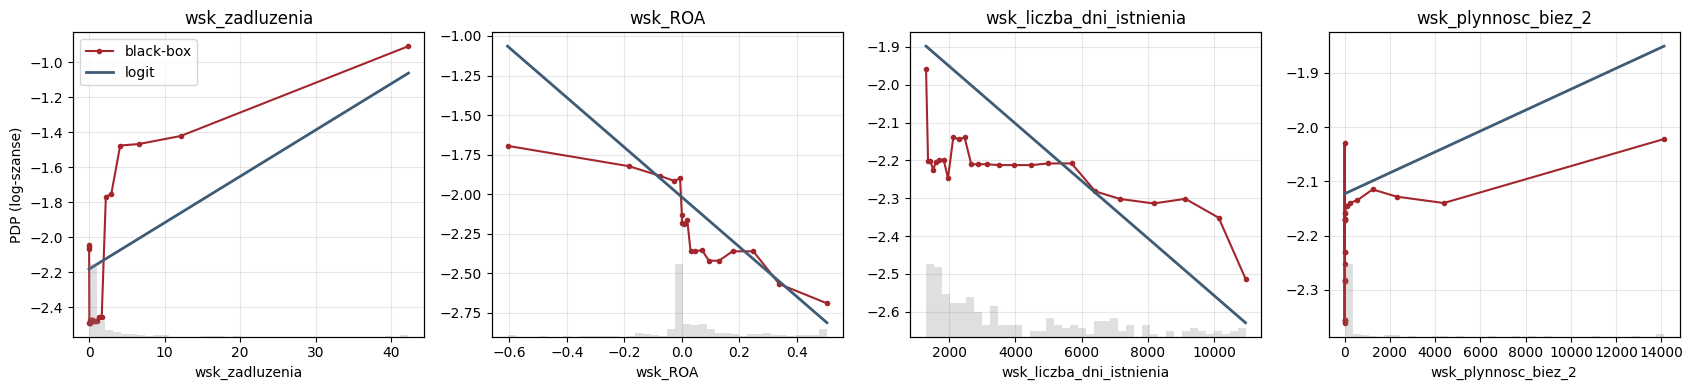

In [37]:
# Lab 5, komórka 12 — nazwy cech z naszego CSV.
CECHY_PDP = ["wsk_zadluzenia", "wsk_ROA", "wsk_liczba_dni_istnienia", "wsk_plynnosc_biez_2"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, CECHY_PDP):
    s = siatka_kwantyli(c)
    ax.plot(s, pdp(f_bb, XS, c, s), "o-", ms=3, color=KOL["black-box"], label="black-box")
    ax.plot(s, pdp(f_lg, XS, c, s), "-", lw=2, color=KOL["logit"], label="logit")
    ax2 = ax.twinx()
    ax2.hist(XS[c].dropna().clip(s.min(), s.max()), bins=40, color="gray", alpha=0.25)
    ax2.set_yticks([]); ax2.set_ylim(0, ax2.get_ylim()[1] * 4)          # histogram w dolnej części panelu
    ax.set_title(c); ax.set_xlabel(c); ax.grid(alpha=0.3)
axes[0].set_ylabel("PDP (log-szanse)"); axes[0].legend()
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "models_pdp.png", dpi=150, bbox_inches="tight"); plt.show()

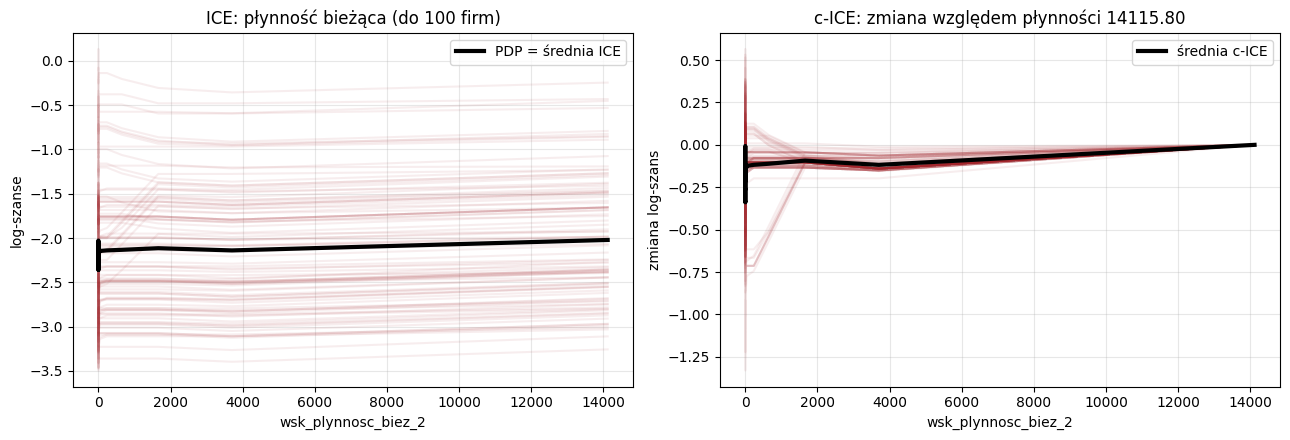

In [38]:
# Lab 5, komórka 23 — wykres ICE; bez założenia progu płynności ze zbioru syntetycznego.
S_PLYN = siatka_kwantyli("wsk_plynnosc_biez_2", n=20)
ICE_PLYN = ice(f_bb, XS, "wsk_plynnosc_biez_2", S_PLYN)                     # 2000 × 20
C_ICE = ICE_PLYN - ICE_PLYN[:, [-1]]                                     # c-ICE: punkt odniesienia = najwyższa płynność
pokaz = np.random.default_rng(RNG_SEED).choice(len(XS), min(100, len(XS)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(S_PLYN, ICE_PLYN[pokaz].T, color=KOL["black-box"], alpha=0.08)
axes[0].plot(S_PLYN, ICE_PLYN.mean(axis=0), color="black", lw=3, label="PDP = średnia ICE")
axes[0].set_title("ICE: płynność bieżąca (do 100 firm)"); axes[0].set_ylabel("log-szanse")
axes[1].plot(S_PLYN, C_ICE[pokaz].T, color=KOL["black-box"], alpha=0.08)
axes[1].plot(S_PLYN, C_ICE.mean(axis=0), color="black", lw=3, label="średnia c-ICE")
axes[1].set_title(f"c-ICE: zmiana względem płynności {S_PLYN[-1]:.2f}"); axes[1].set_ylabel("zmiana log-szans")
for ax in axes:
    ax.set_xlabel("wsk_plynnosc_biez_2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "black_box_ice.png", dpi=150, bbox_inches="tight"); plt.show()

## 5.5. Test kierunków monotoniczności

Źródło: **Lab 5, komórka 44**. Zachowujemy funkcję `naruszenia`, podając nasz słownik hipotez kierunków. Sprawdzamy PDP obu modeli. To diagnostyka uśrednionych zależności, nie dowód monotoniczności dla każdej firmy; ICE pokazuje zróżnicowanie. Znaki są hipotezami wymagającymi potwierdzenia wzorów wskaźników. Nie narzucamy automatycznie ograniczeń na podstawie nazw.

In [39]:
OCZEKIWANY = dict(OCZEKIWANY_ZNAK)

# Lab 5, komórka 44 — funkcja bez zmian.
def naruszenia(model, kierunki=OCZEKIWANY):
    f, w = log_szanse(model), {}
    for c, kier in kierunki.items():
        s = siatka_kwantyli(c)
        d = np.diff(ice(f, XS, c, s).mean(axis=0)) * kier          # przyrosty PDP w oczekiwanym kierunku
        w[c] = {"zmienność PDP": np.abs(d).sum(), "suma naruszeń": float(np.abs(d[d < 0].sum())), "maks. naruszenie": float(np.abs(min(d.min(), 0.0)))}
    t = pd.DataFrame(w).T
    t["udział naruszeń"] = t["suma naruszeń"] / t["zmienność PDP"]
    return t

monotonicznosc = pd.concat({
    "logit": naruszenia(baseline), "black-box": naruszenia(black_box),
}, names=["model", "cecha"])
display(monotonicznosc.round(4))
monotonicznosc.to_csv(ARTIFACT_DIR / "models_monotonicity.csv")
print("Rozmiar black-box:", N_DRZEW, "iteracji, do 8 liści na drzewo,", len(FEATURES), "cech wejściowych.")
print("SHAP/LIME, kalibracja black-box, ratingi i ocena końcowa pozostają do realizacji.")

zmienność PDP  suma naruszeń  \
model     cecha                                                    
logit     wsk_liczba_dni_istnienia         0.7307         0.0000   
          Aktywa                           0.8276         0.0000   
          wsk_zadluzenia                   1.1204         0.0000   
          wsk_plynnosc_biez_2              0.2723         0.2723   
          wsk_ROA                          1.7473         0.0000   
          wsk_rotacja_aktywow_1            0.0621         0.0621   
black-box wsk_liczba_dni_istnienia         0.8718         0.1595   
          Aktywa                           1.2079         0.0867   
          wsk_zadluzenia                   2.0414         0.4535   
          wsk_plynnosc_biez_2              0.9318         0.5697   
          wsk_ROA                          1.2027         0.1039   
          wsk_rotacja_aktywow_1            0.9088         0.5522   

                                    maks. naruszenie  udział naruszeń  
model     cecha                                                        
logit     wsk_liczba_dni_istnienia            0.0000           0.0000  
          Aktywa                              0.0000           0.0000  
          wsk_zadluzenia                      0.0000           0.0000  
          wsk_plynnosc_biez_2                 0.1877           1.0000  
          wsk_ROA                             0.0000           0.0000  
          wsk_rotacja_aktywow_1               0.0419           1.0000  
black-box wsk_liczba_dni_istnienia            0.1098           0.1830  
          Aktywa                              0.0549           0.0718  
          wsk_zadluzenia                      0.4217           0.2222  
          wsk_plynnosc_biez_2                 0.1301           0.6114  
          wsk_ROA                             0.0594           0.0864  
          wsk_rotacja_aktywow_1               0.2720           0.6076

Rozmiar black-box: 100 iteracji, do 8 liści na drzewo, 6 cech wejściowych.
SHAP/LIME, kalibracja black-box, ratingi i ocena końcowa pozostają do realizacji.


## 5.6. Wstępne wyniki i ograniczenia

- Wybrano **100 iteracji** boostingu według średniego log-loss w CV na train. Dłuższe modele nie poprawiły tego kryterium.
- AUC validation: **0,6827** black-box i **0,6807** regresja. Nie ma podstaw, by tak niewielką różnicę uznać za przekonującą przewagę bez niezależnej oceny i przedziałów ufności.
- Black-box ma niższe log-loss (**0,3624** vs **0,3710**) i Brier (**0,1065** vs **0,1104**) na validation. AUC train wynosi **0,8221**, więc różnica train–validation jest wyraźna i wymaga uwzględnienia w ocenie overfittingu.
- VIF po dotychczasowym przygotowaniu sześciu cech wynosi około **1,01–1,04**. Nie wskazuje na silną liniową współliniowość w tej macierzy, ale nie wyklucza zależności nieliniowych ani wspólnych źródeł finansowych wskaźników.
- Dekompozycja logitu regresji odtwarza predykcję z dokładnością numeryczną. Nie jest to jeszcze eksperyment wierności lokalnych wyjaśnień black-box.
- PDP/ICE pokazują skrajne skale płynności i zadłużenia; interpretacja biznesowa wymaga potwierdzenia definicji wskaźników. Hipotetyczna zmiana pojedynczej cechy nie jest automatycznie wykonalną zmianą finansów firmy.


# 6. Kalibracja black-box

Przenosimy ten sam eksperyment kalibracji z sekcji 4 (Lab 2, komórki 14/20/22/24 i Lab 3, 48). Zmieniamy predykcje modelu i nazwy wyników na black-box; funkcje metryk i metody kalibracji są wspólne. Black-box był strojony na train, więc kalibratory nadal uczą się na odrębnym validation.

Porównanie w CV na validation jest etapem wyboru, nie niezależnym testem. Osobno dopasowujemy końcową metodę i przesunięcie do 4% na całym validation. Nie zmieniamy wyboru regresji na podstawie tych wyników.

In [40]:
# Sekcja 4, komórka 52 — ten sam kod dla black-box.
FIT = {
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(
        out_of_bounds="clip", y_min=EPS, y_max=1-EPS
    ).fit(p, y),
}

def zastosuj(metoda, kal, p):
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    return kal.predict(p)

y_cal_BB = np.asarray(y_val)
p_cal_raw_BB = np.asarray(P_MODELE["black-box"]["valid"])
cv_cal_BB = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
foldy_kal_BB = list(cv_cal_BB.split(p_cal_raw_BB.reshape(-1, 1), y_cal_BB))
P_CAL_OOF_BB = {met: np.full(len(y_cal_BB), np.nan) for met in FIT}
P4_CAL_OOF_BB = {met: np.full(len(y_cal_BB), np.nan) for met in FIT}
wiersze_kal_BB = []
for fold, (a, b) in enumerate(foldy_kal_BB, start=1):
    for metoda in FIT:
        kal = FIT[metoda](y_cal_BB[a], p_cal_raw_BB[a])
        q = zastosuj(metoda, kal, p_cal_raw_BB[b])
        P_CAL_OOF_BB[metoda][b] = q
        # Także przesunięcie do 4% wyznaczamy bez danych ocenianego foldu.
        q_ref = zastosuj(metoda, kal, p_cal_raw_BB[a])
        delta_fold = przesuniecie(q_ref, TARGET_PD)
        P4_CAL_OOF_BB[metoda][b] = expit(_z(q) + delta_fold)
        wiersze_kal_BB.append({
            "fold": fold, "metoda": metoda,
            "n_kalibracja": len(a), "defaulty_kalibracja": int(y_cal_BB[a].sum()),
            "n_ocena": len(b), "defaulty_ocena": int(y_cal_BB[b].sum()),
            "log-loss": log_loss(y_cal_BB[b], np.clip(q, EPS, 1-EPS)),
            "Brier": brier_score_loss(y_cal_BB[b], q),
        })
for p in [*P_CAL_OOF_BB.values(), *P4_CAL_OOF_BB.values()]:
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
wyniki_cal_cv_BB = pd.DataFrame(wiersze_kal_BB)
porownanie_cal_BB = wyniki_cal_cv_BB.groupby("metoda").agg(
    logloss_mean=("log-loss", "mean"), logloss_std=("log-loss", "std"),
    Brier_mean=("Brier", "mean"), Brier_std=("Brier", "std"),
).sort_values("logloss_mean")
METODA_KAL_BB = porownanie_cal_BB.index[0]
print("Validation:", len(y_cal_BB), "obserwacji i", int(y_cal_BB.sum()), "defaultów")
display(wyniki_cal_cv_BB.round(4))
display(porownanie_cal_BB.round(5))
print("Wybrana metoda według średniego log-loss:", METODA_KAL_BB)
print("To wybór wstępny; różnice i rozrzut trzeba ocenić wraz z prostotą metod.")
tabela_cal_oof_BB = pd.DataFrame({met: miary_kalibracji(y_cal_BB, p) for met, p in P_CAL_OOF_BB.items()}).T
print("Diagnostyka na predykcjach OOF kalibratorów:")
display(tabela_cal_oof_BB.round(4))

Validation: 451 obserwacji i 59 defaultów


,fold,metoda,n_kalibracja,defaulty_kalibracja,n_ocena,defaulty_ocena,log-loss,Brier
0,1,bez kalibracji,360,47,91,12,0.3507,0.1081
1,1,Platt,360,47,91,12,0.3533,0.1077
2,1,izotoniczna,360,47,91,12,0.3581,0.1095
3,2,bez kalibracji,361,48,90,11,0.3540,0.0991
4,2,Platt,361,48,90,11,0.3537,0.0998
5,2,izotoniczna,361,48,90,11,0.3629,0.1028
6,3,bez kalibracji,361,47,90,12,0.3975,0.1162
7,3,Platt,361,47,90,12,0.3960,0.1159
8,3,izotoniczna,361,47,90,12,0.3888,0.1155
9,4,bez kalibracji,361,47,90,12,0.3415,0.1003


,logloss_mean,logloss_std,Brier_mean,Brier_std
metoda,,,,
bez kalibracji,0.36309,0.02212,0.10677,0.00709
Platt,0.36417,0.01991,0.10715,0.00638
izotoniczna,0.38289,0.05439,0.10586,0.00746


Wybrana metoda według średniego log-loss: bez kalibracji
To wybór wstępny; różnice i rozrzut trzeba ocenić wraz z prostotą metod.
Diagnostyka na predykcjach OOF kalibratorów:


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate,ECE,ACE,CITL a,nachylenie b
bez kalibracji,0.6816,0.3632,0.3083,0.2960,0.3631,0.1068,0.1256,0.1308,0.0290,0.0304,0.0505,0.8561
Platt,0.6760,0.3520,0.2953,0.2952,0.3641,0.1071,0.1308,0.1308,0.0212,0.0344,0.0000,0.9543
izotoniczna,0.6470,0.2941,0.2913,0.2624,0.3828,0.1059,0.1300,0.1308,0.0189,0.0552,0.0085,0.4229


In [41]:
# Sekcja 4, komórka 54 — ten sam kod dla black-box.
KAL_BB = FIT[METODA_KAL_BB](y_cal_BB, p_cal_raw_BB)
p_val_stat_BB = zastosuj(METODA_KAL_BB, KAL_BB, p_cal_raw_BB)
DELTA_BB = przesuniecie(p_val_stat_BB, TARGET_PD)
p_val_4_BB = expit(_z(p_val_stat_BB) + DELTA_BB)
assert np.isclose(p_val_4_BB.mean(), TARGET_PD, atol=1e-10)
assert np.isclose(roc_auc_score(y_cal_BB, p_val_stat_BB), roc_auc_score(y_cal_BB, p_val_4_BB), atol=1e-12)

referencja_4_BB = pd.DataFrame({
    "etap": ["model bazowy", f"statystyczna: {METODA_KAL_BB}", "dostosowanie do 4%"],
    "średnia PD": [p_cal_raw_BB.mean(), p_val_stat_BB.mean(), p_val_4_BB.mean()],
    "default rate": [y_cal_BB.mean()] * 3,
})
print("Populacja referencyjna — validation; to sprawdzenie dopasowania, nie niezależna ocena:")
display(referencja_4_BB.round(5))
print("Przesunięcie logitu delta:", round(DELTA_BB, 4))

P_DIAG_BB = {
    "przed kalibracją": p_cal_raw_BB,
    f"po statystycznej: {METODA_KAL_BB} — OOF": P_CAL_OOF_BB[METODA_KAL_BB],
    "po dostosowaniu do 4% — OOF": P4_CAL_OOF_BB[METODA_KAL_BB],
}
tabela_pre_post_BB = pd.DataFrame({lab: miary_kalibracji(y_cal_BB, p) for lab, p in P_DIAG_BB.items()}).T
display(tabela_pre_post_BB.round(4))

def pd_bb_po_kalibracji(X, do_4proc=False):
    # Gotowe do użycia na teście dopiero po ustaleniu całego rozwiązania.
    p = black_box.predict_proba(X[FEATURES])[:, 1]
    p = zastosuj(METODA_KAL_BB, KAL_BB, p)
    return expit(_z(p) + DELTA_BB) if do_4proc else p

wyniki_cal_cv_BB.to_csv(ARTIFACT_DIR / "black_box_calibration_folds.csv", index=False)
tabela_cal_oof_BB.to_csv(ARTIFACT_DIR / "black_box_calibration_methods_oof.csv")
tabela_pre_post_BB.to_csv(ARTIFACT_DIR / "black_box_calibration_pre_post_oof.csv")
referencja_4_BB.to_csv(ARTIFACT_DIR / "black_box_calibration_reference.csv", index=False)
import json
(ARTIFACT_DIR / "black_box_calibration_config.json").write_text(json.dumps({
    "method": METODA_KAL_BB, "delta": float(DELTA_BB), "target_pd": TARGET_PD,
    "reference": "validation", "seed": RNG_SEED,
    "note": "Configuration only; fitted estimators remain in notebook memory.",
}, ensure_ascii=False, indent=2))

Populacja referencyjna — validation; to sprawdzenie dopasowania, nie niezależna ocena:


,etap,średnia PD,default rate
0,model bazowy,0.1256,0.13082
1,statystyczna: bez kalibracji,0.1256,0.13082
2,dostosowanie do 4%,0.0400,0.13082


Przesunięcie logitu delta: -1.3041


,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate,ECE,ACE,CITL a,nachylenie b
przed kalibracją,0.6816,0.3632,0.3083,0.2960,0.3631,0.1068,0.1256,0.1308,0.0290,0.0304,0.0505,0.8561
po statystycznej: bez kalibracji — OOF,0.6816,0.3632,0.3083,0.2960,0.3631,0.1068,0.1256,0.1308,0.0290,0.0304,0.0505,0.8561
po dostosowaniu do 4% — OOF,0.6797,0.3593,0.2979,0.2941,0.4349,0.1172,0.0401,0.1308,0.0908,0.0934,1.3533,0.8512


206

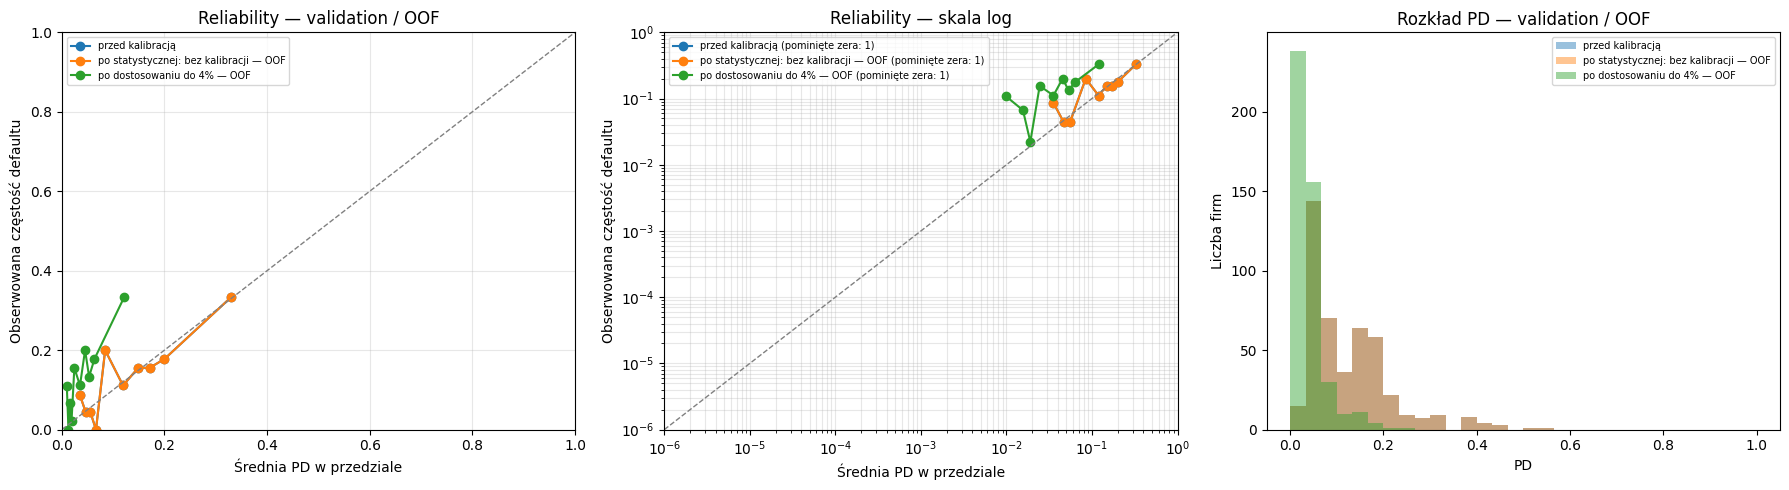

,średnia PD,DR,etap
0,0.0353,0.0870,przed kalibracją
1,0.0465,0.0444,przed kalibracją
2,0.0555,0.0444,przed kalibracją
3,0.0666,0.0000,przed kalibracją
4,0.0845,0.2000,przed kalibracją
5,0.1193,0.1111,przed kalibracją
6,0.1490,0.1556,przed kalibracją
7,0.1712,0.1556,przed kalibracją
8,0.2001,0.1778,przed kalibracją
9,0.3299,0.3333,przed kalibracją


Wybór metody: bez kalibracji
Liczba defaultów na validation: 59 — ostrożnie z elastyczną isotonic.
Po 4%: zmiana Brier względem statystycznej OOF = 0.01047
Końcowa ocena testowa oraz ratingi i ich backtest pozostają do realizacji.


In [42]:
# Sekcja 4, komórka 56 — ten sam kod dla black-box.
def reliability(ax, y_true, p, label, n_bins=10, log_scale=False):
    obs, pred = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
    mask = (obs > 0) & (pred > 0) if log_scale else np.ones(len(obs), dtype=bool)
    suffix = f" (pominięte zera: {int((~mask).sum())})" if log_scale else ""
    ax.plot(pred[mask], obs[mask], marker="o", label=label + suffix)
    return pd.DataFrame({"średnia PD": pred, "DR": obs})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tabele_reliability_BB = []
for lab, p in P_DIAG_BB.items():
    tab = reliability(axes[0], y_cal_BB, p, lab)
    tab["etap"] = lab
    tabele_reliability_BB.append(tab)
    reliability(axes[1], y_cal_BB, p, lab, log_scale=True)
    axes[2].hist(p, bins=np.linspace(0, 1, 31), alpha=0.45, label=lab)
for ax in axes[:2]:
    ax.plot([EPS, 1], [EPS, 1], "--", color="gray", linewidth=1)
    ax.set_xlabel("Średnia PD w przedziale")
    ax.set_ylabel("Obserwowana częstość defaultu")
    ax.grid(alpha=0.3, which="both")
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Reliability — validation / OOF")
axes[1].set(xscale="log", yscale="log", xlim=(EPS, 1), ylim=(EPS, 1), title="Reliability — skala log")
axes[2].set(xlabel="PD", ylabel="Liczba firm", title="Rozkład PD — validation / OOF")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "black_box_calibration_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
tab_reliability_BB = pd.concat(tabele_reliability_BB, ignore_index=True)
display(tab_reliability_BB.round(4))
tab_reliability_BB.to_csv(ARTIFACT_DIR / "black_box_reliability_oof.csv", index=False)

print("Wybór metody:", METODA_KAL_BB)
print("Liczba defaultów na validation:", int(y_cal_BB.sum()), "— ostrożnie z elastyczną isotonic.")
print("Po 4%: zmiana Brier względem statystycznej OOF =", round(
    tabela_pre_post_BB.iloc[2]["Brier"] - tabela_pre_post_BB.iloc[1]["Brier"], 5
))
print("Końcowa ocena testowa oraz ratingi i ich backtest pozostają do realizacji.")

# 7. SHAP — globalnie i lokalnie

Źródła: **Lab 4, komórki 18, 21, 26, 29, 36, 38** i **Lab 6, komórka 12** (indeksy od 0). Wyjaśnienia globalne TreeSHAP dotyczą **surowego boostingu w skali log-szans**, a wzór dla regresji — surowego logitu. Nie podpisujemy tych wartości jako wkładów do PD po kalibracji.

TreeSHAP używa `tree_path_dependent`; regresja ma tło z train. Różnice rankingów mogą wynikać zarówno z modeli, jak i definicji tła i postępowania z zależnościami cech. Korelacje cech ograniczają jednoznaczność przypisywania wkładów. Wyjaśnienia nie dowodzą przyczynowości.

Dla kilku lokalnych przypadków obliczymy dodatkowo dokładne wartości Shapleya całego łańcucha **black-box → kalibracja → przesunięcie do 4%**, aby nie przenosić bez uzasadnienia surowego TreeSHAP przez nieliniową kalibrację.

In [43]:
!pip install lime shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=48e3daef1b8c1409707487591f3151e00c5f5563e282368462e8b402bb30cde4
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


shap: 0.54.1 | lime: 0.2.0.1
TreeSHAP — maksymalny błąd addytywności: 3.1086244689504383e-15


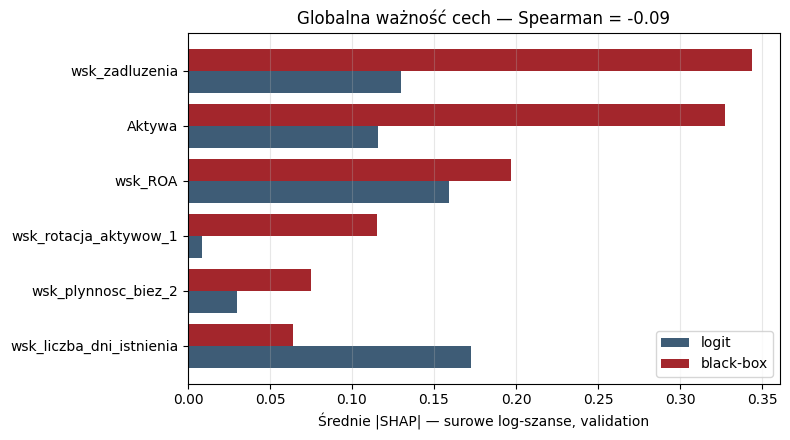

,logit,black-box
wsk_zadluzenia,0.1297,0.3438
Aktywa,0.1162,0.3272
wsk_ROA,0.1592,0.1971
wsk_rotacja_aktywow_1,0.0088,0.1150
wsk_plynnosc_biez_2,0.0300,0.0751
wsk_liczba_dni_istnienia,0.1724,0.0638


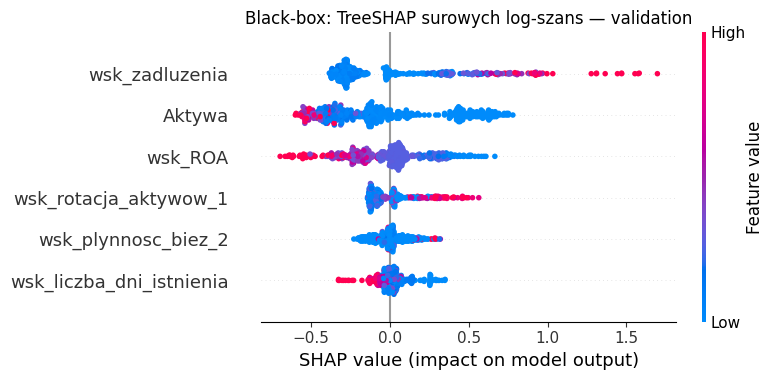

,permutacyjna: logit,permutacyjna: black-box,odch. std. logit,odch. std. black-box,średnie |SHAP| black-box
Aktywa,0.0230,0.0495,0.0148,0.0103,0.3272
wsk_zadluzenia,0.0116,0.0459,0.0130,0.0271,0.3438
wsk_ROA,0.0723,0.0321,0.0294,0.0147,0.1971
wsk_liczba_dni_istnienia,0.0330,0.0066,0.0292,0.0065,0.0638
wsk_plynnosc_biez_2,-0.0071,0.0018,0.0049,0.0071,0.0751
wsk_rotacja_aktywow_1,0.0022,-0.0008,0.0020,0.0072,0.1150


Spearman — permutacyjna vs SHAP: 0.714


In [44]:
import shap
from lime.lime_tabular import LimeTabularExplainer
import importlib.metadata
print("shap:", shap.__version__, "| lime:", importlib.metadata.version("lime"))

# Lab 4, komórka 26. Nasze sześć cech liczbowych nie wymaga grupowania dummy variables.
pre_bb, clf = black_box.named_steps["pre"], black_box.named_steps["clf"]
assert [s.split("__", 1)[1] for s in pre_bb.get_feature_names_out()] == FEATURES
explainer = shap.TreeExplainer(clf)
sv_va = explainer(pre_bb.transform(X_va))
PHI_BB = sv_va.values
BAZA_BB = float(np.ravel(sv_va.base_values)[0])
blad = np.abs(BAZA_BB + PHI_BB.sum(axis=1) - clf.decision_function(pre_bb.transform(X_va))).max()
assert blad < 1e-6
print("TreeSHAP — maksymalny błąd addytywności:", blad)
PHI_LOG = shap_logit(X_va)

# Lab 4, komórka 36: globalny ranking i porównanie z logitem.
waz = pd.DataFrame({"logit": np.abs(PHI_LOG).mean(axis=0),
                    "black-box": np.abs(PHI_BB).mean(axis=0)}, index=FEATURES).sort_values("black-box")
rho_waz = spearmanr(waz["logit"], waz["black-box"])[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(waz))
ax.barh(yy - 0.2, waz["logit"], 0.4, color=KOL["logit"], label="logit")
ax.barh(yy + 0.2, waz["black-box"], 0.4, color=KOL["black-box"], label="black-box")
ax.set_yticks(yy); ax.set_yticklabels(waz.index)
ax.set_xlabel("Średnie |SHAP| — surowe log-szanse, validation")
ax.set_title(f"Globalna ważność cech — Spearman = {rho_waz:.2f}")
ax.legend(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "shap_global_models.png", dpi=150, bbox_inches="tight"); plt.show()
display(waz.sort_values("black-box", ascending=False).round(4))

E_bb = shap.Explanation(values=PHI_BB, base_values=np.full(len(PHI_BB), BAZA_BB),
                        data=X_va.to_numpy(dtype=float), feature_names=FEATURES)
shap.plots.beeswarm(E_bb, max_display=len(FEATURES), show=False)
plt.title("Black-box: TreeSHAP surowych log-szans — validation")
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

# Lab 6, komórka 12: zestawienie z policzoną już ważnością permutacyjną.
SHAP_VA = pd.Series(np.abs(PHI_BB).mean(axis=0), index=FEATURES)
tab_perm["średnie |SHAP| black-box"] = SHAP_VA
display(tab_perm.round(4))
print("Spearman — permutacyjna vs SHAP:", round(spearmanr(perm["black-box"], SHAP_VA)[0], 3))
waz.to_csv(ARTIFACT_DIR / "shap_global_importance.csv")
tab_perm.to_csv(ARTIFACT_DIR / "permutation_shap_comparison.csv")

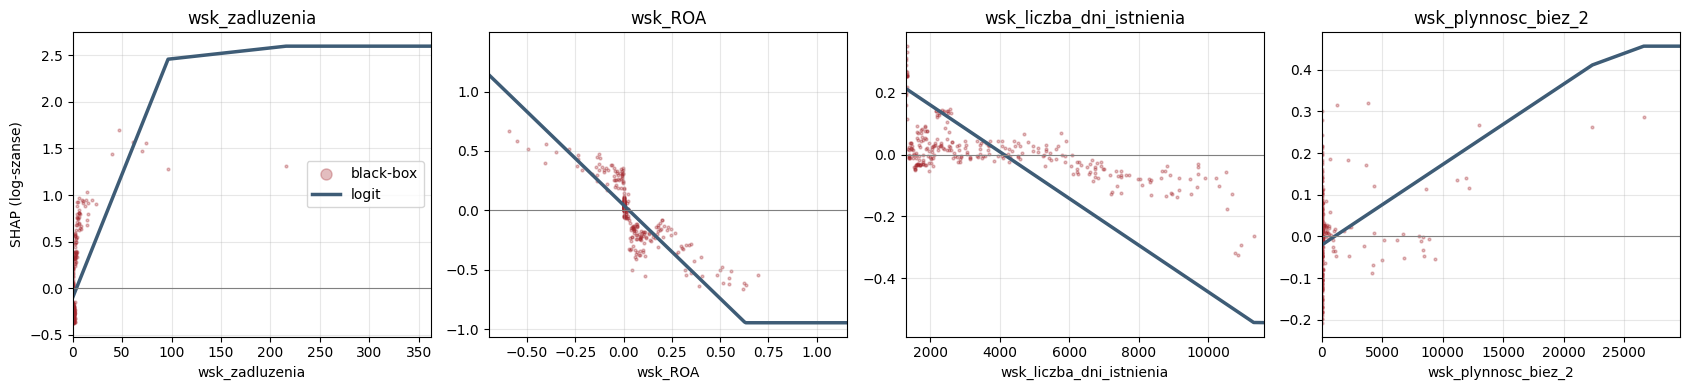

In [45]:
# Lab 4, komórka 38 — dependence, nasze cechy i mniejsza próba validation.
idx_d = np.random.default_rng(RNG_SEED).choice(len(X_va), min(300, len(X_va)), replace=False)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["wsk_zadluzenia", "wsk_ROA", "wsk_liczba_dni_istnienia", "wsk_plynnosc_biez_2"]):
    j, xv = FEATURES.index(c), X_va[c].to_numpy()[idx_d]
    ax.scatter(xv, PHI_BB[idx_d, j], s=4, alpha=0.3, color=KOL["black-box"], label="black-box")
    o = np.argsort(xv)
    ax.plot(xv[o], PHI_LOG[idx_d, j][o], color=KOL["logit"], lw=2.5, label="logit")
    ax.axhline(0, color="gray", lw=0.8); ax.set_xlim(np.nanpercentile(xv, [0.5, 99.5]))
    ax.set_xlabel(c); ax.set_title(c); ax.grid(alpha=0.3)
axes[0].set_ylabel("SHAP (log-szanse)"); axes[0].legend(markerscale=4)
plt.tight_layout(); plt.savefig(ARTIFACT_DIR / "shap_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

## 7.1. Lokalne wyjaśnienia surowego i końcowego modelu

Zachowujemy przykłady z sekcji 5 i dodajemy firmę z PD końcowego black-box najbliższą 4%. Poziom 4% służy tu jedynie do wyboru przykładu; **nie jest progiem decyzji operacyjnej**. Przypadek graniczny względem takiego progu dopiszemy na etapie ratingów.

Waterfall surowego TreeSHAP opisuje model bazowy. Dla końcowych log-szans korzystamy z funkcji `shapley_dokladne` z **Lab 4, komórka 18**, przepisanej bez zmian. Przy sześciu cechach wystarczą 64 koalicje. Tło to próbka 50 firm z train. Addytywność sprawdzamy dla każdego przypadku. Takie marginalne podmienianie cech nie zachowuje wszystkich zależności finansowych.

Obserwacja 1228 default: 0 PD regresji: 0.018 PD black-box surowe: 0.0543 PD black-box po 4%: 0.0154


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
4,wsk_ROA,-1.340000e-02,0.0663,0.3480,0.3854,1228
3,wsk_plynnosc_biez_2,1.815000e-01,-0.0200,-0.0125,-0.0349,1228
0,wsk_liczba_dni_istnienia,1.051500e+04,-0.4839,-0.0569,-0.0789,1228
5,wsk_rotacja_aktywow_1,8.410000e-02,-0.0080,-0.1134,-0.1570,1228
2,wsk_zadluzenia,3.756000e-01,-0.0890,-0.3134,-0.2904,1228
1,Aktywa,9.333481e+07,-1.4325,-0.5649,-0.5263,1228


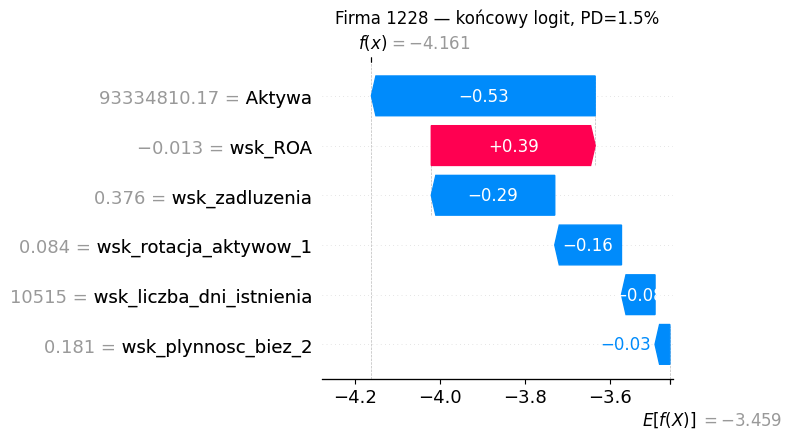

Obserwacja 339 default: 1 PD regresji: 0.8882 PD black-box surowe: 0.5061 PD black-box po 4%: 0.2176


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
2,wsk_zadluzenia,96.4602,2.4591,1.2772,1.1895,339
4,wsk_ROA,-0.8505,1.3818,0.4663,0.6052,339
3,wsk_plynnosc_biez_2,0.3106,-0.0200,0.1836,0.1937,339
0,wsk_liczba_dni_istnienia,1306.0000,0.2127,0.1601,0.1601,339
5,wsk_rotacja_aktywow_1,0.0000,-0.0082,0.0781,0.0684,339
1,Aktywa,217289.5200,0.0764,0.0028,-0.0379,339


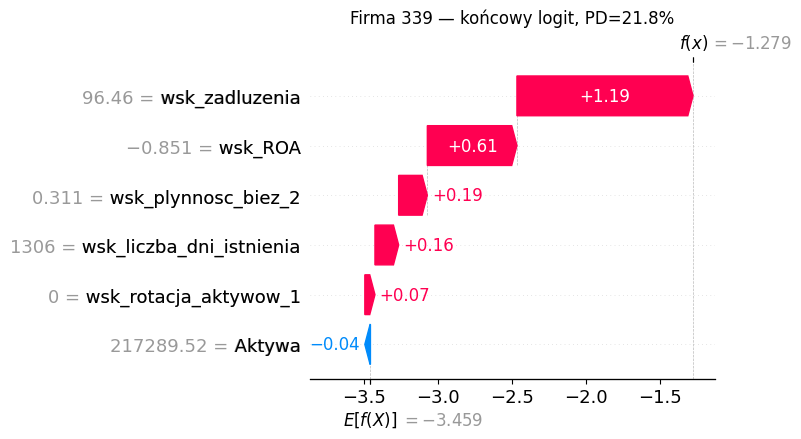

Obserwacja 960 default: 0 PD regresji: 0.1296 PD black-box surowe: 0.1158 PD black-box po 4%: 0.0343


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
2,wsk_zadluzenia,6.219000e+00,0.0660,0.6166,0.5809,960
0,wsk_liczba_dni_istnienia,1.308000e+03,0.2126,0.3499,0.3307,960
5,wsk_rotacja_aktywow_1,2.346700e+00,-0.0039,-0.0604,-0.0722,960
3,wsk_plynnosc_biez_2,4.302000e+00,-0.0199,-0.0903,-0.1122,960
4,wsk_ROA,5.160000e-02,-0.0358,-0.3069,-0.1932,960
1,Aktywa,7.677192e+06,-0.0939,-0.3979,-0.4120,960


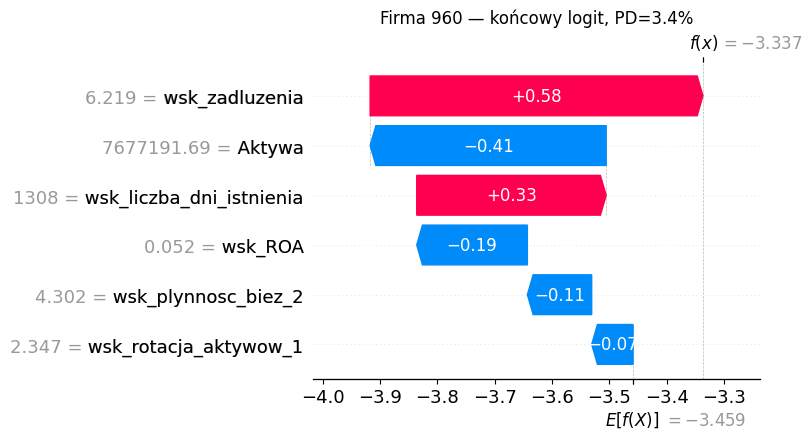

Obserwacja 249 default: 1 PD regresji: 0.0513 PD black-box surowe: 0.0397 PD black-box po 4%: 0.0111


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
5,wsk_rotacja_aktywow_1,4.1845,-0.0006,0.0375,0.0115,249
0,wsk_liczba_dni_istnienia,4587.0000,-0.0355,-0.0152,-0.0216,249
3,wsk_plynnosc_biez_2,4.7375,-0.0199,-0.0494,-0.0524,249
1,Aktywa,207646.0500,0.0766,-0.1242,-0.1380,249
2,wsk_zadluzenia,0.2676,-0.0919,-0.2741,-0.2654,249
4,wsk_ROA,0.5481,-0.8161,-0.6173,-0.5658,249


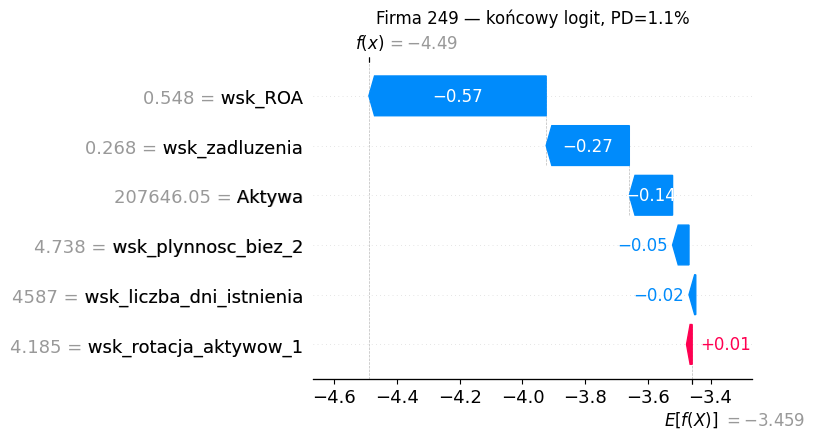

Obserwacja 1940 default: 0 PD regresji: 0.4208 PD black-box surowe: 0.1318 PD black-box po 4%: 0.0396


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
2,wsk_zadluzenia,1.689450e+05,2.5991,1.3094,1.1881,1940
0,wsk_liczba_dni_istnienia,6.587000e+03,-0.1868,-0.0551,-0.0657,1940
3,wsk_plynnosc_biez_2,1.347600e+00,-0.0200,-0.0688,-0.0733,1940
5,wsk_rotacja_aktywow_1,7.166000e-01,-0.0069,-0.0709,-0.0852,1940
4,wsk_ROA,4.480000e-02,-0.0251,-0.5045,-0.3433,1940
1,Aktywa,3.204642e+07,-0.6499,-0.3518,-0.3513,1940


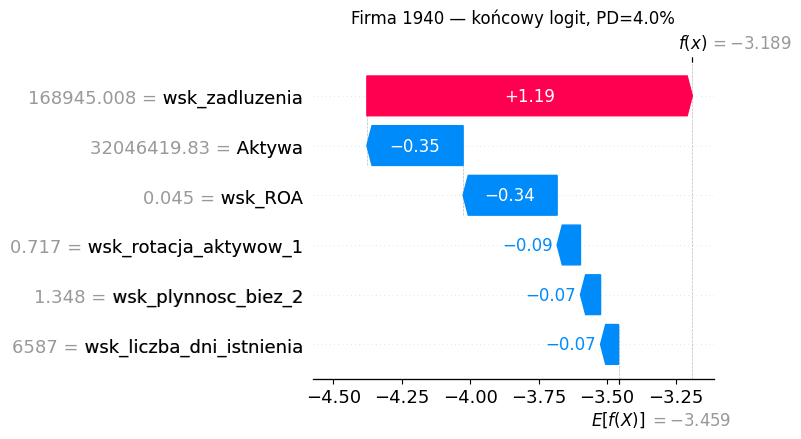

In [46]:
import itertools
from math import factorial

# Cały łańcuch do późniejszych decyzji i LIME; test nie jest tu odczytywany.
def pd_koncowe(X):
    return pd_bb_po_kalibracji(X, do_4proc=True)

pd_va_final = pd_koncowe(X_va)
CASE_XAI_IDS = list(dict.fromkeys(CASE_IDS + [int(np.argmin(np.abs(pd_va_final - TARGET_PD)))]))[:5]
TLO = X_tr.sample(min(50, len(X_tr)), random_state=RNG_SEED).reset_index(drop=True)
def shapley_dokladne(f, x, tlo):
    """Wartości Shapleya z definicji: v(S) = średnia f po tle, gdy cechy z S mają wartości firmy x."""
    M = len(FEATURES)
    koalicje = [S for r in range(M + 1) for S in itertools.combinations(range(M), r)]     # 2^M koalicji
    bloki = []
    for S in koalicje:
        Xb = tlo.copy()
        for j in S:
            Xb[FEATURES[j]] = x[FEATURES[j]]
        bloki.append(Xb)
    wyniki = np.asarray(f(pd.concat(bloki, ignore_index=True))).reshape(len(koalicje), len(tlo)).mean(axis=1)
    v = dict(zip(koalicje, wyniki))
    phi = np.zeros(M)
    for S, vS in v.items():
        for j in range(M):
            if j not in S:
                phi[j] += factorial(len(S)) * factorial(M - len(S) - 1) / factorial(M) * (v[tuple(sorted(S + (j,)))] - vS)
    return pd.Series(phi, index=FEATURES), v[()]

PHI_FINAL_CASES, BAZY_FINAL_CASES = {}, {}
local_rows = []
for i in CASE_XAI_IDS:
    phi, baza = shapley_dokladne(lambda X: _z(pd_koncowe(X)), X_va.iloc[i], TLO)
    assert np.isclose(baza + phi.sum(), _z(pd_va_final[[i]])[0], atol=1e-7)
    PHI_FINAL_CASES[i], BAZY_FINAL_CASES[i] = phi, baza
    t = pd.DataFrame({"cecha": FEATURES, "wartość": X_va.iloc[i].to_numpy(),
                      "wkład logit regresji": PHI_LOG[i], "TreeSHAP surowy black-box": PHI_BB[i],
                      "Shapley końcowy black-box": phi.to_numpy()})
    t["row_index"] = X_va.index[i]
    local_rows.append(t)
    print("Obserwacja", X_va.index[i], "default:", y_va.iloc[i],
          "PD regresji:", round(p_inter_val[i], 4),
          "PD black-box surowe:", round(P_MODELE["black-box"]["valid"][i], 4),
          "PD black-box po 4%:", round(pd_va_final[i], 4))
    display(t.sort_values("Shapley końcowy black-box", ascending=False).round(4))
    E = shap.Explanation(values=phi.to_numpy(), base_values=baza,
                         data=X_va.iloc[i].to_numpy(dtype=float), feature_names=FEATURES)
    shap.plots.waterfall(E, max_display=len(FEATURES), show=False)
    plt.title(f"Firma {X_va.index[i]} — końcowy logit, PD={pd_va_final[i]:.1%}")
    plt.tight_layout()
    plt.savefig(ARTIFACT_DIR / f"shap_final_case_{X_va.index[i]}.png", dpi=150, bbox_inches="tight")
    plt.show()
pd.concat(local_rows).to_csv(ARTIFACT_DIR / "shap_local_cases.csv", index=False)

# 8. LIME — lokalna wierność i stabilność

Źródło: **Lab 6, komórki 40, 42 i 44**. Zmieniamy cechy i usuwamy kodowanie branży — nasze sześć cech jest liczbowych. LIME wyjaśnia ten sam pełny łańcuch co dokładny Shapley w sekcji 7.1, ale w skali **PD**, a nie log-szans. Wielkości wag obu metod nie są więc bezpośrednio porównywalne. Porównujemy ostrożnie kierunki i rankingi bezwzględnych wkładów.

LIME losuje perturbacje niezależnie od pełnych zależności wskaźników. Jego wyjaśnienie może być niestabilne lub dotyczyć kombinacji nieobserwowanych w realnych firmach. `e.score` to ważone R² na sztucznej próbie użytej do dopasowania lokalnego surogatu, nie niezależna ocena.

Dodatkowo sprawdzamy zgodność surogatu z modelem na pozostałych rzeczywistych obserwacjach validation, ważonych według odległości w przestrzeni dyskretyzacji LIME. Te obserwacje nie są dopasowywaną próbką surogatu. To uzupełnienie laboratoryjnego eksperymentu, nie test generalizacji modelu ryzyka.

In [47]:
# Lab 6, komórka 40 — sześć cech liczbowych, więc bez kodowania branży.
def do_lime(X):
    return X[FEATURES].to_numpy(dtype=float)

def pd_dla_lime(A):
    D = pd.DataFrame(A, columns=FEATURES)
    p = pd_koncowe(D)
    return np.column_stack([1 - p, p])

A_tr = do_lime(X_tr)
assert np.isfinite(A_tr).all()
FIRMA = CASE_XAI_IDS[-1]
x_lime = do_lime(X_va.iloc[[FIRMA]])[0]

def lime_wyjasnij(random_state, num_samples=2000, kernel_width=None):
    ex = LimeTabularExplainer(A_tr, feature_names=FEATURES,
                              class_names=["brak defaultu", "default"], mode="classification",
                              kernel_width=kernel_width, random_state=random_state)
    return ex.explain_instance(x_lime, pd_dla_lime, num_features=len(FEATURES), num_samples=num_samples)

from sklearn.metrics import r2_score, mean_absolute_error

def fidelity_na_validation(e, i):
    # Dodatek do Lab 6: niezależne od dopasowania surogatu obserwacje validation.
    schema = LimeTabularExplainer(A_tr, feature_names=FEATURES, mode="classification", random_state=RNG_SEED)
    A = do_lime(X_va.drop(index=X_va.index[i]))
    bins = schema.discretizer.discretize(A)
    bins_x = schema.discretizer.discretize(do_lime(X_va.iloc[[i]])[0])
    Z = (bins == bins_x).astype(float)
    w = np.array([dict(e.as_map()[1]).get(j, 0.0) for j in range(len(FEATURES))])
    surrogate = e.intercept[1] + Z @ w
    pred = pd_dla_lime(A)[:, 1]
    distance = np.linalg.norm(Z - 1.0, axis=1)
    kernel_width = 0.75 * np.sqrt(len(FEATURES))
    weights = np.exp(-(distance ** 2) / (2 * kernel_width ** 2))
    return {"R2 ważone validation": r2_score(pred, surrogate, sample_weight=weights),
            "MAE ważone validation": mean_absolute_error(pred, surrogate, sample_weight=weights)}

lime_cases, fidelity_rows = [], []
LIME_EXPLANATIONS = {}
for i in CASE_XAI_IDS:
    x_lime = do_lime(X_va.iloc[[i]])[0]
    e = lime_wyjasnij(random_state=RNG_SEED)
    LIME_EXPLANATIONS[i] = e
    tab_lime = pd.DataFrame({"reguła LIME": [r for r, _ in e.as_list()],
                             "waga LIME (pp PD)": [100 * w for _, w in e.as_list()]})
    tab_lime["cecha"] = [FEATURES[j] for j, _ in e.as_map()[1]]
    phi_firma = PHI_FINAL_CASES[i]
    tab_lime["Shapley końcowy (log-szanse)"] = tab_lime["cecha"].map(phi_firma).to_numpy()
    tab_lime["ranga |LIME|"] = tab_lime["waga LIME (pp PD)"].abs().rank(ascending=False)
    tab_lime["ranga |Shapley|"] = tab_lime["cecha"].map(phi_firma.abs().rank(ascending=False))
    tab_lime["row_index"] = X_va.index[i]
    lime_cases.append(tab_lime)
    fidelity_rows.append({"row_index": X_va.index[i], "PD modelu": pd_va_final[i],
                          "PD surogatu w punkcie": float(e.local_pred[0]),
                          "błąd w punkcie": abs(float(e.local_pred[0]) - pd_va_final[i]),
                          "R2 próba LIME (fit)": float(e.score), **fidelity_na_validation(e, i)})
    print("LIME — obserwacja", X_va.index[i])
    display(tab_lime.set_index("cecha").round(4))
tabela_fidelity = pd.DataFrame(fidelity_rows).set_index("row_index")
display(tabela_fidelity.round(4))
pd.concat(lime_cases).to_csv(ARTIFACT_DIR / "lime_cases.csv", index=False)
tabela_fidelity.to_csv(ARTIFACT_DIR / "lime_fidelity.csv")
# Stała obserwacja dla powtórzeń seedów.
x_lime = do_lime(X_va.iloc[[FIRMA]])[0]

LIME — obserwacja 1228


,reguła LIME,waga LIME (pp PD),Shapley końcowy (log-szanse),ranga |LIME|,ranga |Shapley|,row_index
cecha,,,,,,
wsk_ROA,wsk_ROA <= 0.00,3.8322,0.3854,1.0,2.0,1228
wsk_zadluzenia,0.07 < wsk_zadluzenia <= 0.45,-3.0601,-0.2904,2.0,3.0,1228
Aktywa,Aktywa > 2585206.86,-1.7663,-0.5263,3.0,1.0,1228
wsk_plynnosc_biez_2,wsk_plynnosc_biez_2 <= 1.49,0.6554,-0.0349,4.0,6.0,1228
wsk_rotacja_aktywow_1,0.01 < wsk_rotacja_aktywow_1 <= 1.13,-0.4400,-0.1570,5.0,4.0,1228
wsk_liczba_dni_istnienia,wsk_liczba_dni_istnienia > 5870.50,0.0230,-0.0789,6.0,5.0,1228


LIME — obserwacja 339


,reguła LIME,waga LIME (pp PD),Shapley końcowy (log-szanse),ranga |LIME|,ranga |Shapley|,row_index
cecha,,,,,,
wsk_zadluzenia,wsk_zadluzenia > 1.82,8.6529,1.1895,1.0,1.0,339
wsk_ROA,wsk_ROA <= 0.00,4.2276,0.6052,2.0,2.0,339
wsk_plynnosc_biez_2,wsk_plynnosc_biez_2 <= 1.49,1.0703,0.1937,3.0,3.0,339
wsk_liczba_dni_istnienia,wsk_liczba_dni_istnienia <= 1793.00,0.3278,0.1601,4.0,4.0,339
Aktywa,87847.45 < Aktywa <= 526404.23,-0.3200,-0.0379,5.0,6.0,339
wsk_rotacja_aktywow_1,wsk_rotacja_aktywow_1 <= 0.01,0.3109,0.0684,6.0,5.0,339


LIME — obserwacja 960


,reguła LIME,waga LIME (pp PD),Shapley końcowy (log-szanse),ranga |LIME|,ranga |Shapley|,row_index
cecha,,,,,,
wsk_zadluzenia,wsk_zadluzenia > 1.82,8.2014,0.5809,1.0,1.0,960
wsk_ROA,0.00 < wsk_ROA <= 0.08,-1.6264,-0.1932,2.0,4.0,960
Aktywa,Aktywa > 2585206.86,-1.5530,-0.4120,3.0,2.0,960
wsk_plynnosc_biez_2,1.49 < wsk_plynnosc_biez_2 <= 4.58,-1.1222,-0.1122,4.0,5.0,960
wsk_rotacja_aktywow_1,1.13 < wsk_rotacja_aktywow_1 <= 3.26,-0.7949,-0.0722,5.0,6.0,960
wsk_liczba_dni_istnienia,wsk_liczba_dni_istnienia <= 1793.00,0.2088,0.3307,6.0,3.0,960


LIME — obserwacja 249


,reguła LIME,waga LIME (pp PD),Shapley końcowy (log-szanse),ranga |LIME|,ranga |Shapley|,row_index
cecha,,,,,,
wsk_ROA,wsk_ROA > 0.08,-4.0523,-0.5658,1.0,1.0,249
wsk_zadluzenia,0.07 < wsk_zadluzenia <= 0.45,-2.9604,-0.2654,2.0,2.0,249
wsk_rotacja_aktywow_1,wsk_rotacja_aktywow_1 > 3.26,0.7499,0.0115,3.0,6.0,249
Aktywa,87847.45 < Aktywa <= 526404.23,-0.3295,-0.1380,4.0,3.0,249
wsk_plynnosc_biez_2,4.58 < wsk_plynnosc_biez_2 <= 119.03,0.1274,-0.0524,5.0,4.0,249
wsk_liczba_dni_istnienia,2877.00 < wsk_liczba_dni_istnienia <= 5870.50,-0.0996,-0.0216,6.0,5.0,249


LIME — obserwacja 1940


,reguła LIME,waga LIME (pp PD),Shapley końcowy (log-szanse),ranga |LIME|,ranga |Shapley|,row_index
cecha,,,,,,
wsk_zadluzenia,wsk_zadluzenia > 1.82,8.2802,1.1881,1.0,1.0,1940
wsk_ROA,0.00 < wsk_ROA <= 0.08,-1.7586,-0.3433,2.0,3.0,1940
Aktywa,Aktywa > 2585206.86,-1.6854,-0.3513,3.0,2.0,1940
wsk_plynnosc_biez_2,wsk_plynnosc_biez_2 <= 1.49,0.9109,-0.0733,4.0,5.0,1940
wsk_rotacja_aktywow_1,0.01 < wsk_rotacja_aktywow_1 <= 1.13,-0.4261,-0.0852,5.0,4.0,1940
wsk_liczba_dni_istnienia,wsk_liczba_dni_istnienia > 5870.50,-0.1942,-0.0657,6.0,6.0,1940


,PD modelu,PD surogatu w punkcie,błąd w punkcie,R2 próba LIME (fit),R2 ważone validation,MAE ważone validation
row_index,,,,,,
1228,0.0154,0.0400,0.0246,0.2630,0.0090,0.0280
339,0.2176,0.1519,0.0657,0.7135,-0.3687,0.0294
960,0.0343,0.0823,0.0480,0.5792,-0.2378,0.0277
249,0.0111,0.0073,0.0037,0.2272,-0.1089,0.0286
1940,0.0396,0.0959,0.0563,0.5754,-0.3307,0.0292


## 8.1. Stabilność LIME przy różnych seedach

Przenosimy `stabilnosc_lime` z **Lab 6, komórka 42** bez zmian. Dla jednej i tej samej firmy wykonujemy po pięć powtórzeń przy 500 i 2000 perturbacji. Dodatkowo wyznaczamy parami Spearmana dla |wag| i Jaccarda dla zbiorów Top-3, zgodnie z wymaganiami projektu. To nie jest zmienność między różnymi firmami: model, firma i preprocessing pozostają stałe.

Jeżeli wyjaśnienia się zmieniają, nie oznacza to automatycznie niestabilności predykcji modelu. Trzeba oddzielić losowość LIME od nieliniowości modelu i jego zachowania na nierealistycznych perturbacjach.

In [48]:
# Lab 6, komórka 42 — funkcja bez zmian.
def stabilnosc_lime(num_samples, ziarna=range(5), kernel_width=None):
    W, top3 = [], []
    for rs in ziarna:
        ex = lime_wyjasnij(rs, num_samples=num_samples, kernel_width=kernel_width)
        w = pd.Series(dict(ex.as_map()[1])).rename(index=lambda j: FEATURES[j])
        W.append(w); top3.append(" | ".join(w.abs().nlargest(3).index))
    W = pd.DataFrame(W).reindex(columns=FEATURES) * 100
    tab = pd.DataFrame({"średnia waga (pp PD)": W.mean(), "odch. std.": W.std(), "min": W.min(), "max": W.max()})
    return tab.reindex(tab["średnia waga (pp PD)"].abs().sort_values(ascending=False).index), pd.Series(top3).value_counts()

stability_rows = []
for num_samples in [500, 2000]:
    tab_stab, top3_stab = stabilnosc_lime(num_samples=num_samples)
    print("Liczba perturbacji:", num_samples)
    display(tab_stab.round(3))
    display(top3_stab.to_frame("liczba powtórzeń"))
    # Dodatek wymaganej miary liczbowej, na tych samych ustawieniach i seedach.
    W = []
    for rs in range(5):
        e = lime_wyjasnij(rs, num_samples=num_samples)
        w = pd.Series(dict(e.as_map()[1])).reindex(range(len(FEATURES)), fill_value=0.0)
        W.append(w.to_numpy())
    W = np.asarray(W)
    for a, b in itertools.combinations(range(5), 2):
        top_a = set(np.argsort(np.abs(W[a]))[-3:])
        top_b = set(np.argsort(np.abs(W[b]))[-3:])
        stability_rows.append({"num_samples": num_samples, "seed_a": a, "seed_b": b,
            "Spearman |wag|": spearmanr(np.abs(W[a]), np.abs(W[b]))[0],
            "Jaccard Top-3": len(top_a & top_b) / len(top_a | top_b)})
    tab_stab.to_csv(ARTIFACT_DIR / f"lime_stability_weights_{num_samples}.csv")
tabela_stabilnosci = pd.DataFrame(stability_rows)
display(tabela_stabilnosci.groupby("num_samples")[["Spearman |wag|", "Jaccard Top-3"]].agg(["mean", "min", "std"]).round(4))
tabela_stabilnosci.to_csv(ARTIFACT_DIR / "lime_stability_pairs.csv", index=False)
print("Wyniki wierności i stabilności trzeba interpretować wraz z ograniczeniami perturbacji.")
print("Ratingi, próg operacyjny, kontrfaktyk i końcowy test pozostają do realizacji.")

Liczba perturbacji: 500


,średnia waga (pp PD),odch. std.,min,max
wsk_zadluzenia,7.935,0.995,6.636,9.420
wsk_ROA,-1.991,0.318,-2.369,-1.510
Aktywa,-1.294,0.227,-1.501,-0.919
wsk_rotacja_aktywow_1,-0.877,0.423,-1.295,-0.179
wsk_plynnosc_biez_2,0.818,0.316,0.451,1.178
wsk_liczba_dni_istnienia,-0.478,0.487,-0.944,0.308


,liczba powtórzeń
wsk_zadluzenia | wsk_ROA | Aktywa,4
wsk_zadluzenia | wsk_ROA | wsk_rotacja_aktywow_1,1


Liczba perturbacji: 2000


,średnia waga (pp PD),odch. std.,min,max
wsk_zadluzenia,8.311,0.127,8.167,8.485
wsk_ROA,-1.660,0.225,-1.910,-1.422
Aktywa,-1.516,0.103,-1.681,-1.422
wsk_plynnosc_biez_2,0.898,0.170,0.737,1.158
wsk_rotacja_aktywow_1,-0.621,0.103,-0.731,-0.480
wsk_liczba_dni_istnienia,-0.439,0.181,-0.613,-0.215


,liczba powtórzeń
wsk_zadluzenia | wsk_ROA | Aktywa,4
wsk_zadluzenia | Aktywa | wsk_ROA,1


Spearman |wag|                 Jaccard Top-3             
                      mean     min     std          mean  min     std
num_samples                                                          
500                 0.8571  0.6571  0.0943           0.8  0.5  0.2582
2000                0.9543  0.8857  0.0361           1.0  1.0  0.0000

Wyniki wierności i stabilności trzeba interpretować wraz z ograniczeniami perturbacji.
Ratingi, próg operacyjny, kontrfaktyk i końcowy test pozostają do realizacji.


## 8.2. Wnioski z wyjaśnień i aktualny stan

- Dla black-box najniższy średni log-loss kalibracji w CV na validation ma wariant **bez kalibracji**. Końcowe przesunięcie do 4% wynosi około **−1,3139**. Wynik nie jest jeszcze niezależną oceną testową.
- Surowy TreeSHAP wskazuje najwyżej zadłużenie i aktywa. Ranking globalny jest słabo zgodny z rankingiem regresji (Spearman około **−0,09**). Nie wynika z tego, że jedna metoda wyjaśnień jest błędna: modele są różne i używają różnych założeń dotyczących tła.
- Dla pięciu obserwacji przedstawiono dokładne wkłady końcowego łańcucha black-box i porównanie z regresją. Sprawdzono addytywność TreeSHAP oraz dokładnego Shapleya z definicji.
- Dopasowanie LIME na jego sztucznej próbie ma R² około **0,21–0,70**, ale na innych rzeczywistych firmach validation ważone R² wynosi około **−0,42 do 0,01**. W czterech przypadkach jest ujemne: surogat jest tam gorszy od ważonej stałej na tym zbiorze oceny. Oznacza to ograniczoną wierność w tak zdefiniowanym otoczeniu; wyników nie należy przedstawiać jako wiarygodnych reguł decyzyjnych bez dodatkowych zastrzeżeń.
- Odległość w tej ocenie jest wyznaczona w binarnej przestrzeni dyskretyzacji LIME. Nie jest to jedyna definicja lokalności ani dowód słabej jakości każdej możliwej wersji LIME. Należy rozróżnić błąd surogatu, skalę wyjścia PD i ograniczenia próby perturbacyjnej.
- Dla stałej firmy średni Spearman |wag| rośnie z **0,760** przy 500 perturbacjach do **0,874** przy 2000. Jaccard Top-3 spada jednak z **0,80** do **0,65**. Więcej próbek nie gwarantuje stabilniejszego Top-k; bliskie wagi mogą zamieniać się miejscami.
- Brakuje nadal ratingów i progu operacyjnego, przypadku granicznego względem tego progu, realistycznego kontrfaktyku, zamknięcia porównania na teście i materiałów do oddania. Wcześniejsze uwagi o brakujących SHAP/LIME odnoszą się do stanu przed sekcjami 7–8.


# 9. Progi decyzji i mapowanie na ratingi

Przechodzimy od ciągłych predykcji PD do dyskretnych reguł decyzyjnych oraz skali ratingowej. Wszystkie progi i granice klas ustalamy wyłącznie na zbiorze walidacyjnym, zachowując zbiór testowy do końcowej weryfikacji.

W bankowości i ocenie ryzyka kredytowego skala ratingowa (AAA–CCC + D) służy do różnicowania ceny kredytu, limitów zaangażowania i raportowania.

Modele zostały skalibrowane do docelowego PD = 4%, więc analizę progów i skali ratingowej prowadzimy na **PD po przesunięciu do 4%**, pamiętając, że w próbie validation empiryczny *default rate* wynosi około 13,1%.

# 9.1. Mapowanie PD, klasy ratingowe

Skala ratingowa oparta na średnim PD 4% oparta na wykładzie 3:
|Klasa|Przedział PD|PD klasy|
|-|-|-|
|AAA|<1%|0,5%|
|AA|1-2%|1,5%|
|A|2-5%|3,5%|
|BBB|5-8%|6,5%|
|BB|8-12%|10%|
|B|12-20%|16%|
|CCC|>20%|30%|
|D| default|100%|

Uwaga:
- Klasy są monotoniczne (wyższa klasa ryzyka = wyższe PD)
- Liczba klas, według Wykładu 3, co najmniej 7 dla klientów bez
defaultu + 1 dla defaultu (CRR art. 170)
- Klasy są coraz szersze
- Brak klasy, w której jest większość portfela
- Granice stałe w czasie, zmienia się tylko przypisanie klientów

Źródła: Lab 3, krok 5.

Analiza skali ratingowej (Regresja, validation):
Największy udział klasy: 75.2% (A) | HHI = 0.588 (równy rozkład na 7 klas: 0.143)


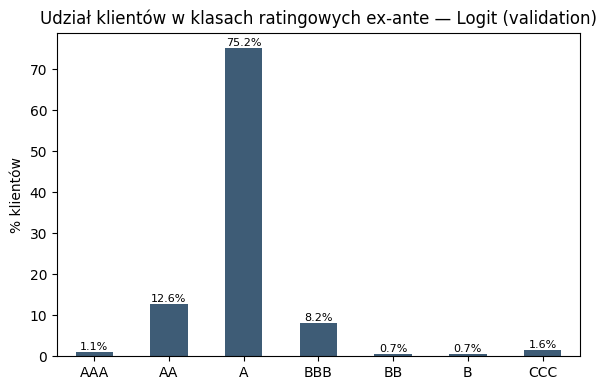

Analiza skali ratingowej (Black-Box, validation):
Największy udział klasy: 33.7% (A) | HHI = 0.266 (równy rozkład na 7 klas: 0.143)


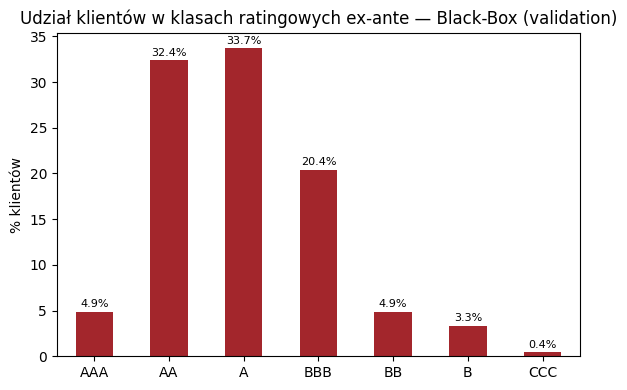

In [49]:
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
PD_REPR = [0.005, 0.015, 0.035, 0.065, 0.1, 0.16, 0.3]

p_va_lg_4 = pd_logit_po_kalibracji(X_va, do_4proc=True)
p_va_bb_4 = pd_bb_po_kalibracji(X_va, do_4proc=True)
y_va_arr = np.asarray(y_va)

PD_REPR_MAP = dict(zip(RATING_LABELS, PD_REPR))
#Inspiracja - Lab 3, krok 5
def przypisz_rating_pd(p):
    kat = pd.cut(np.asarray(p), bins=RATING_BINS, labels=RATING_LABELS, right=False, include_lowest=True)
    klasy = pd.Categorical(kat, categories=RATING_LABELS, ordered=True)
    sztywne_pd = klasy.map(PD_REPR_MAP).astype(float)
    return klasy, sztywne_pd

r_val_bb, pd_repr_val_bb = przypisz_rating_pd(p_va_bb_4)

r_val_lg, pd_repr_val_lg = przypisz_rating_pd(p_va_lg_4)

udzialy_lr = pd.Series(r_val_lg).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
hhi_lr = float((udzialy_lr ** 2).sum())

udzialy = pd.Series(r_val_bb).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
hhi = float((udzialy ** 2).sum())

print(f"Analiza skali ratingowej (Regresja, validation):")
print(f"Największy udział klasy: {udzialy_lr.max():.1%} ({udzialy_lr.idxmax()}) | HHI = {hhi_lr:.3f} (równy rozkład na 7 klas: {1 / 7:.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
(100 * udzialy_lr).plot.bar(color=KOL["logit"], rot=0, ax=ax)
ax.set_ylabel("% klientów")
ax.set_title("Udział klientów w klasach ratingowych ex-ante — Logit (validation)")
for i, v in enumerate(100 * udzialy_lr):
    if v > 0:
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "rating_distribution_validation_logit.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Analiza skali ratingowej (Black-Box, validation):")
print(f"Największy udział klasy: {udzialy.max():.1%} ({udzialy.idxmax()}) | HHI = {hhi:.3f} (równy rozkład na 7 klas: {1 / 7:.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
(100 * udzialy).plot.bar(color=KOL["black-box"], rot=0, ax=ax)
ax.set_ylabel("% klientów")
ax.set_title("Udział klientów w klasach ratingowych ex-ante — Black-Box (validation)")
for i, v in enumerate(100 * udzialy):
    if v > 0:
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "rating_distribution_validation_bb.png", dpi=150, bbox_inches="tight")
plt.show()

Dla modelu Blach-box brak silnej koncentracji, wskaźnik HHI oraz histogram pokazują zróżnicowanie klas.

Model regresji logistycznej występuje wysoka koncentracja w klasie A (aż 75,2% w zbiorze walidacyjnym). Granice skali są wspólne dla banku i stałe w czasie, więc nie przesuwamy ich pod jeden portfel, więc najlepszym rozwiązaniem byłoby rozbicie na podklasy.

Klasa A => Klasa A-, Klasa A, Klasa A+

Regresja po wprowadzeniu podklas A+,A,A- (granice A: 2.96%, 3.93%):
Nowy największy udział klasy: 25.1% (A+) | Nowe HHI = 0.211 (wcześniej 0.588)


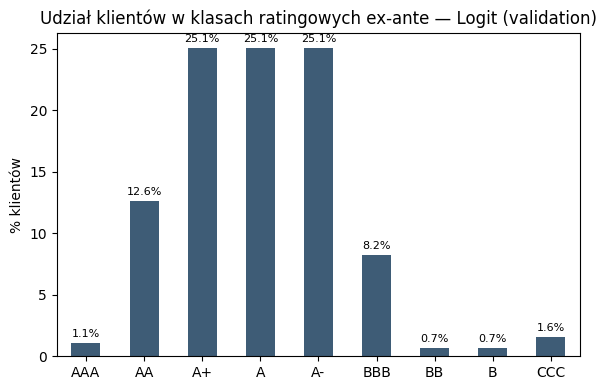

In [50]:
p_klasa_A = p_va_lg_4[(p_va_lg_4 >= 0.02) & (p_va_lg_4 < 0.05)]
q33, q67 = np.quantile(p_klasa_A, [1/3, 2/3])

BINS_LOGIT_SUB = [0.00, 0.01, 0.02, float(q33), float(q67), 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]
LABELS_LOGIT_SUB = ["AAA", "AA", "A+", "A", "A-", "BBB", "BB", "B", "CCC"]

r_val_lg_sub = pd.Categorical(
    pd.cut(p_va_lg_4, bins=BINS_LOGIT_SUB, labels=LABELS_LOGIT_SUB, right=False, include_lowest=True),
    categories=LABELS_LOGIT_SUB, ordered=True
)
udzialy_lr_sub = pd.Series(r_val_lg_sub).value_counts(normalize=True).reindex(LABELS_LOGIT_SUB).fillna(0)
hhi_lr_sub = float((udzialy_lr_sub ** 2).sum())

print(f"Regresja po wprowadzeniu podklas A+,A,A- (granice A: {q33:.2%}, {q67:.2%}):")
print(f"Nowy największy udział klasy: {udzialy_lr_sub.max():.1%} ({udzialy_lr_sub.idxmax()}) | Nowe HHI = {hhi_lr_sub:.3f} (wcześniej {hhi_lr:.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
(100 * udzialy_lr_sub).plot.bar(color=KOL["logit"], rot=0, ax=ax)
ax.set_ylabel("% klientów")
ax.set_title("Udział klientów w klasach ratingowych ex-ante — Logit (validation)")
for i, v in enumerate(100 * udzialy_lr_sub):
    if v > 0:
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "rating_distribution_validation_logit.png", dpi=150, bbox_inches="tight")
plt.show()


# 9.2 . Backtest per klasa

Dla klasy z n klientami, d defaultami i średnim PD:

- test dwumianowy (jednostronny): p = P(X ≥ d), X ~ Bin(n, PD),
- test Jeffreysa (stosowany przez EBC): p = F_Beta(PD; d + ½, n - d + ½).

Mała p-wartość oznacza, że PD klasy jest prawdopodobnie zaniżone. Światła - konwencja przyjęta w tym laboratorium: zielone p ≥ 0,05, żółte 0,01 ≤ p < 0,05, czerwone p < 0,01. Oba testy zakładają niezależność defaultów, a przy wspólnym cyklu są zbyt surowe - jeden rok to sygnał do analizy, nie automatyczna rekalibracja.

Źródło: Lab3, 5.3



Backtest skali ratingowej: Black-box


,n,defaulty,oczekiwane,średnie PD,DR,p dwumianowy,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,22,3,0.11,0.005,0.1364,0.0002,0.0000,czerwone,0.0324,żółte
AA,146,5,2.19,0.015,0.0342,0.0699,0.0413,żółte,0.0518,zielone
A,152,22,5.32,0.035,0.1447,0.0000,0.0000,czerwone,0.1149,zielone
BBB,92,17,5.98,0.065,0.1848,0.0001,0.0000,czerwone,0.1899,zielone
BB,22,6,2.20,0.100,0.2727,0.0182,0.0092,czerwone,0.2867,zielone
B,15,4,2.40,0.160,0.2667,0.2092,0.1315,zielone,0.4048,zielone
CCC,2,2,0.60,0.300,1.0000,0.0900,0.0189,żółte,0.5293,zielone


DR rośnie monotonicznie między klasami: False
Światła po δ (4%): {'czerwone': 4, 'żółte': 2, 'zielone': 1} | przed δ (~13%): {'zielone': 6, 'żółte': 1}

 Backtest skali ratingowej: Regresja logistyczna


,n,defaulty,oczekiwane,średnie PD,DR,p dwumianowy,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,5,0,0.025,0.005,0.0000,1.0000,0.1816,zielone,0.0267,zielone
AA,57,5,0.855,0.015,0.0877,0.0017,0.0006,czerwone,0.0571,zielone
A+,113,7,3.955,0.035,0.0619,0.1023,0.0691,zielone,0.0856,zielone
A,113,13,3.955,0.035,0.1150,0.0002,0.0001,czerwone,0.1159,zielone
A-,113,19,3.955,0.035,0.1681,0.0000,0.0000,czerwone,0.1407,zielone
BBB,37,10,2.405,0.065,0.2703,0.0001,0.0000,czerwone,0.1864,zielone
BB,3,2,0.300,0.100,0.6667,0.0280,0.0062,czerwone,0.2699,zielone
B,3,0,0.480,0.160,0.0000,1.0000,0.7139,zielone,0.3922,zielone
CCC,7,3,2.100,0.300,0.4286,0.3529,0.2221,zielone,0.6548,zielone


DR rośnie monotonicznie między klasami: False
Światła po δ (4%): {'czerwone': 5, 'zielone': 4} | przed δ (~13%): {'zielone': 9}


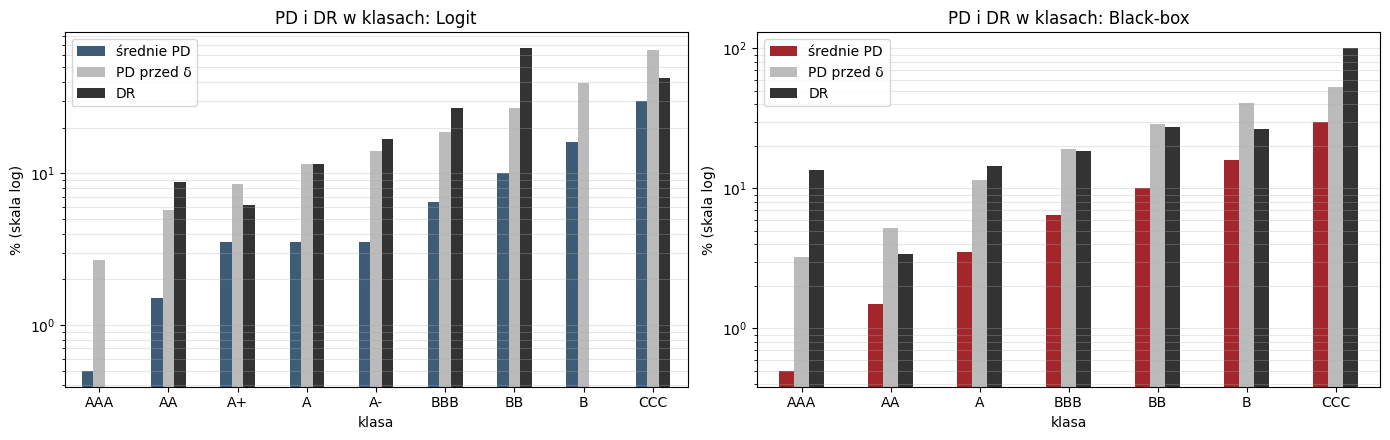

In [51]:
from scipy.stats import beta as beta_dist, binomtest

# Kod z Labu 3: test Jeffreysa oraz jednostronny test dwumianowy przed i po przesunięciu delta
def swiatlo(p):
    return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")

def backtest(y, p, r, p_kszt=None, etykiety=RATING_LABELS):
    y = np.asarray(y)
    p = np.asarray(p)
    rows = []
    for lab in etykiety:
        m = np.asarray(r == lab)
        if not m.any():
            continue
        n_k, d_k, pd_k = int(m.sum()), int(y[m].sum()), float(p[m].mean())
        pj = float(beta_dist.cdf(pd_k, d_k + 0.5, n_k - d_k + 0.5))
        w = {
            "klasa": lab,
            "n": n_k,
            "defaulty": d_k,
            "oczekiwane": n_k * pd_k,
            "średnie PD": pd_k,
            "DR": d_k / n_k,
            "p dwumianowy": binomtest(d_k, n_k, pd_k, alternative="greater").pvalue,
            "p Jeffreysa": pj,
            "światło": swiatlo(pj),
        }
        if p_kszt is not None:  # ten sam test dla PD przed przesunięciem do 4%
            pk = float(np.asarray(p_kszt)[m].mean())
            w.update({
                "PD przed δ": pk,
                "światło przed δ": swiatlo(float(beta_dist.cdf(pk, d_k + 0.5, n_k - d_k + 0.5))),
            })
        rows.append(w)
    return pd.DataFrame(rows).set_index("klasa")

bt_bb = backtest(y_va_arr, pd_repr_val_bb, r_val_bb, p_kszt=p_val_stat_BB)
print("Backtest skali ratingowej: Black-box")
display(bt_bb.round(4))
dr_kl_bb = bt_bb["DR"].to_numpy()
print("DR rośnie monotonicznie między klasami:", bool(np.all(np.diff(dr_kl_bb) >= 0)))
print("Światła po δ (4%):", bt_bb["światło"].value_counts().to_dict(),
      "| przed δ (~13%):", bt_bb["światło przed δ"].value_counts().to_dict())

bt_lg = backtest(y_va_arr, pd_repr_val_lg, r_val_lg_sub, p_kszt=p_val_stat, etykiety=LABELS_LOGIT_SUB)
print("\n Backtest skali ratingowej: Regresja logistyczna")
display(bt_lg.round(4))
dr_kl_lg = bt_lg["DR"].to_numpy()
print("DR rośnie monotonicznie między klasami:", bool(np.all(np.diff(dr_kl_lg) >= 0)))
print("Światła po δ (4%):", bt_lg["światło"].value_counts().to_dict(),
      "| przed δ (~13%):", bt_lg["światło przed δ"].value_counts().to_dict())

bt_bb.to_csv(ARTIFACT_DIR / "backtest_rating_bb_val.csv")
bt_lg.to_csv(ARTIFACT_DIR / "backtest_rating_logit_val.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, bt_df, tytul, kol_modelu in [
    (axes[0], bt_lg, "PD i DR w klasach: Logit", KOL["logit"]),
    (axes[1], bt_bb, "PD i DR w klasach: Black-box", KOL["black-box"]),
]:
    (100 * bt_df[["średnie PD", "PD przed δ", "DR"]]).plot.bar(
        ax=ax, rot=0, color=[kol_modelu, "#BBBBBB", "#333333"]
    )
    ax.set_yscale("log")
    ax.set_ylabel("% (skala log)")
    ax.set_title(tytul)
    ax.grid(axis="y", alpha=0.3, which="both")

plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "backtest_rating_validation.png", dpi=150, bbox_inches="tight")
plt.show()

Brak monotoniczności DR w skrajnych klasach może wynikać z małej próby. Dla modelu regresji w klasie B trafiły np. same firmy bez defaultów.

Światło:
- czerwone po δ, ale zielone przed δ: AA, A, A-, BBB, BB (A-dla regresji).

Faktyczny wskaźnik defaultów w portfelu osiągał poziom ok. 13,1%, co znacznie przewyższa założenie portfelowe ustalone na poziomie PD = 4,0%. Warto wprowadzic marginez konserwatywny.

- czerwone także przed δ: brak

# Margines konserwatyzmu

In [52]:
MARGIN, LGD = 0.1, 0.45 #wstępne wartosci

slownik_modeli_val = {
    "Logit": p_va_lg_4,
    "Black-Box": p_va_bb_4
}

def swiatla_moc(y_true, p_sym):
    r_sym, _ = przypisz_rating_pd(p_sym)
    bt_res = backtest(y_true, p_sym, r_sym, p_kszt=None)
    return bt_res["światło"].value_counts().to_dict()

for nazwa_modelu, p_valid in slownik_modeli_val.items():
  print(f"\nSzukanie δ_MoC dla {nazwa_modelu}")
  d_moc_znalezione = None
  for d_moc in np.arange(0, 2.01, 0.05):
      p_sym = expit(_z(p_valid) + d_moc)
      s = swiatla_moc(y_va_arr, p_sym)
      warunek = (s.get("czerwone", 0) == 0)
      if warunek:
         d_moc_znalezione = float(d_moc)
         break

  if d_moc_znalezione is None:
    print("W zakresie [0, 2] nie udało się usunąć wszystkich czerwonych świateł")
  else:
    p_va_moc = expit(_z(p_valid) + d_moc_znalezione)
    r_va_moc, _ = przypisz_rating_pd(p_va_moc)

    bt_przed_moc = backtest(y_va_arr, p_valid, przypisz_rating_pd(p_valid)[0])
    bt_po_moc = backtest(y_va_arr, p_va_moc, r_va_moc)

    print("Światła przed MoC (kotwica 4%):", bt_przed_moc["światło"].value_counts().to_dict())
    print(f"Światła po MoC (δ_MoC = {d_moc_znalezione:.2f}):", bt_po_moc["światło"].value_counts().to_dict())

    def podsumuj_el_moc(p_vec, ead_vec):
        przyj = p_vec < (MARGIN / (MARGIN + LGD))
        return {
            "średnie PD %": 100 * p_vec.mean(),
            "stopa akceptacji":  przyj.mean(),
            "EL przyjętych (j.p.)": float(np.sum(p_vec[przyj] * LGD * ead_vec[przyj])),
        }

    ead_val = np.ones(len(y_va_arr))
    porownanie_moc = pd.DataFrame({
        "Bez MoC (kotwica 4%)": podsumuj_el_moc(p_valid, ead_val),
        f"Z MoC (δ={d_moc_znalezione:.2f})": podsumuj_el_moc(p_va_moc, ead_val),
    }).T.round(3)
    display(porownanie_moc)



Szukanie δ_MoC dla Logit
Światła przed MoC (kotwica 4%): {'czerwone': 4, 'zielone': 3}
Światła po MoC (δ_MoC = 1.05): {'zielone': 5, 'żółte': 1}


,średnie PD %,stopa akceptacji,EL przyjętych (j.p.)
Bez MoC (kotwica 4%),4.000,0.984,6.945
Z MoC (δ=1.05),10.013,0.967,17.499



Szukanie δ_MoC dla Black-Box
Światła przed MoC (kotwica 4%): {'czerwone': 5, 'żółte': 1, 'zielone': 1}
Światła po MoC (δ_MoC = 0.75): {'żółte': 4, 'zielone': 2}


,średnie PD %,stopa akceptacji,EL przyjętych (j.p.)
Bez MoC (kotwica 4%),4.000,0.993,7.821
Z MoC (δ=0.75),7.876,0.931,12.464


Znaleziony próg dający brak czerwonych świateł dla modelu Black-Box wynosi 0,75. Po zastosowaniu mamy 4 światła żółte i 2 zielone.

Próg dla regresji wyniósł 1,05 i daje 5 zielonych świateł.

## 9.3. Definicja funkcji kosztu/korzyści i dobór progu operacyjnego

Zasada decyzyjna:
- PD < próg (p*) => akceptacja wniosku (y_hat = 0)
- PD > próg (p*) => odrzucenie wniosku (y_hat = 1)

Funkcje kosztu/korzyści definiujemy następującą:
- TP (y=1, y_hat=1): odrzucony zły klient => brak straty
- FP (y=0, y_hat=1): odrzucony dobry klient => brak potencjalnego zysku
- TN (y=0, y_hat=0): zaakceptowany dobry klient => zysk
- FN (y=1, y_hat=0): zaakceptowany zły klient => strata

In [53]:
from sklearn.metrics import confusion_matrix

def macierz_decyzji(y, p, prog):
    decyzja = (np.asarray(p) >= prog).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, decyzja, labels=[0, 1]
    ).ravel()

    return {
        "TN - zaakceptowani dobrzy": tn,
        "FP - odrzuceni dobrzy": fp,
        "FN - zaakceptowani źli": fn,
        "TP - odrzuceni źli": tp,
        "Liczba zaakceptowanych": tn + fn,
        "Liczba odrzuconych": fp + tp,
        "Stopa akceptacji": (tn + fn) / len(y),
        "Udział złych w zaakceptowanych": (
            fn / (tn + fn) if (tn + fn) > 0 else np.nan
        )
    }

# 9.4. Wizualizacja krzywych ROC oraz PR


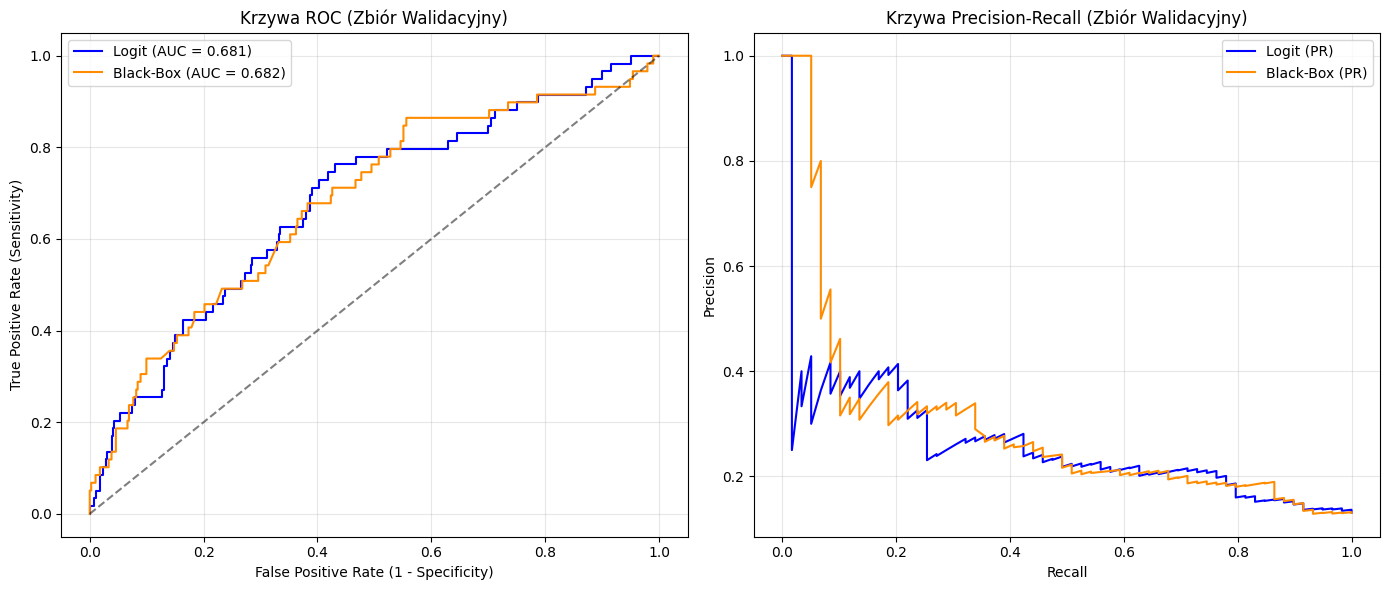

In [54]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
fpr_lg, tpr_lg, _ = roc_curve(y_va_arr, p_va_lg_4)
auc_lg = roc_auc_score(y_va_arr, p_va_lg_4)
plt.plot(fpr_lg, tpr_lg, label=f'Logit (AUC = {auc_lg:.3f})', color='blue')

fpr_bb, tpr_bb, _ = roc_curve(y_va_arr, p_va_bb_4)
auc_bb = roc_auc_score(y_va_arr, p_va_bb_4)
plt.plot(fpr_bb, tpr_bb, label=f'Black-Box (AUC = {auc_bb:.3f})', color='darkorange')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Krzywa ROC (Zbiór Walidacyjny)')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
precision_lg, recall_lg, _ = precision_recall_curve(y_va_arr, p_va_lg_4)
plt.plot(recall_lg, precision_lg, label='Logit (PR)', color='blue')

precision_bb, recall_bb, _ = precision_recall_curve(y_va_arr, p_va_bb_4)
plt.plot(recall_bb, precision_bb, label='Black-Box (PR)', color='darkorange')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Krzywa Precision-Recall (Zbiór Walidacyjny)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Krzywe ROC obu modeli przebiegają wyraźnie powyżej linii losowej ($y = x$), co potwierdza wysoką zdolność dyskryminacyjną w ocenie ryzyka kredytowego. Ciężko stwierdzić, który model sprawdza sie lepiej.

#  Próg decyzyjny z funkcji zysku

Uproszczona ekonomia kredytu o ekspozycji EAD: przyjęty dobry klient daje zysk MARGIN · EAD, przyjęty zły - stratę LGD · EAD, odrzucenie - 0. Opłaca się przyjąć klienta, gdy (1 - PD) · MARGIN > PD · LGD, czyli


$$\text{PD} < p^* = \frac{\text{MARGIN}}{\text{MARGIN} + \text{LGD}}$$

 Próg empiryczny szukamy na valid, test służy tylko do raportu.

Źródło: Lab 3, 5.4

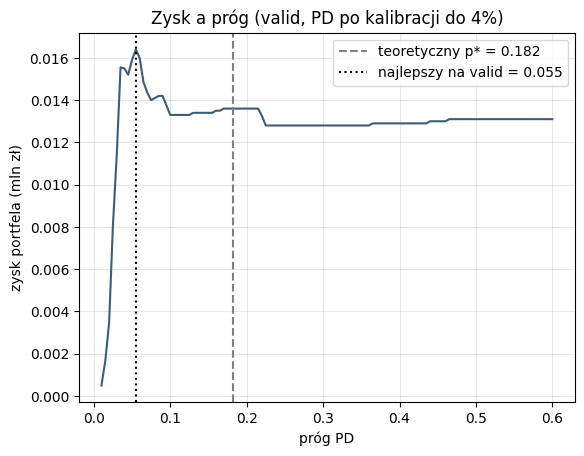

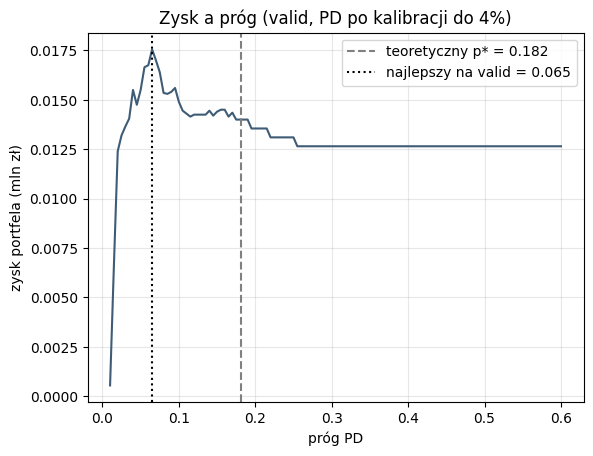

In [55]:
p_star = MARGIN / (MARGIN + LGD)

def ekonomia(y, p, e, prog, margin=None, lgd=None):
    margin = MARGIN if margin is None else margin
    lgd = LGD if lgd is None else lgd
    przyj = np.asarray(p) < prog
    y_arr = np.asarray(y)
    e_arr = np.asarray(e)
    return {
        "próg": prog,
        "stopa akceptacji": float(przyj.mean()),
        "DR wśród przyjętych": float(y_arr[przyj].mean()) if przyj.any() else np.nan,
        "EL przyjętych (oczekiwana)": float(np.sum(p[przyj] * lgd * e_arr[przyj])),
        "strata zrealizowana": float(np.sum(lgd * e_arr[przyj & (y_arr == 1)])),
        "zysk": float(np.sum(margin * e_arr[przyj & (y_arr == 0)]) - np.sum(lgd * e_arr[przyj & (y_arr == 1)]))
    }

progi = np.linspace(0.01, 0.6, 119)

ead_val = np.ones(len(y_va_arr))
optymalne_progi = {}

for nazwa_modelu, p_valid in slownik_modeli_val.items():

  zysk_va = np.array([ekonomia(y_va_arr, p_valid, ead_val, t)["zysk"] for t in progi])
  prog_va = float(progi[int(np.argmax(zysk_va))])
  optymalne_progi[nazwa_modelu] = prog_va
  plt.plot(progi, zysk_va / 1e3, color=KOL["logit"])
  plt.axvline(p_star, ls="--", color="gray", label=f"teoretyczny p* = {p_star:.3f}")
  plt.axvline(prog_va, ls=":", color="black", label=f"najlepszy na valid = {prog_va:.3f}")
  plt.xlabel("próg PD"); plt.ylabel("zysk portfela"); plt.title("Zysk a próg (valid, PD po kalibracji do 4%)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

prog_va_logit = optymalne_progi.get("Logit")
prog_va_bb = optymalne_progi.get("Black-Box")

Progi z valid wychodzą wyraźnie niższy od p*, co wskazuje, że PD po δ jest niższe od DR w okresie walidacji: najlepszy próg empiryczny „kompensuje” zaniżone PD. Sprawdzenie progów na zbiorze testowym w podsumowaniu i wynikach.

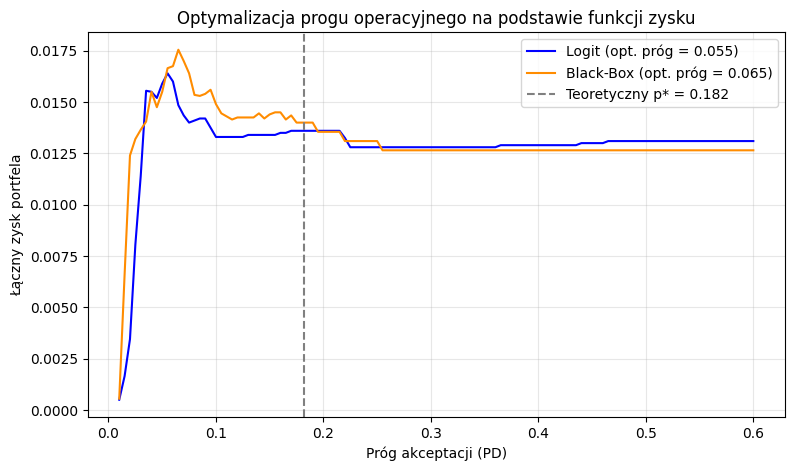

Optymalny próg empiryczny dla Logitu: 0.055
Optymalny próg empiryczny dla Black-Boxa: 0.065


In [56]:
zysk_va_lg = np.array([ekonomia(y_va_arr, p_va_lg_4, ead_val, t)["zysk"] for t in progi])
zysk_va_bb = np.array([ekonomia(y_va_arr, p_va_bb_4, ead_val, t)["zysk"] for t in progi])
plt.figure(figsize=(9, 5))
plt.plot(progi, zysk_va_lg / 1e3, label=f'Logit (opt. próg = {prog_va_logit:.3f})', color='blue')
plt.plot(progi, zysk_va_bb / 1e3, label=f'Black-Box (opt. próg = {prog_va_bb:.3f})', color='darkorange')
plt.axvline(p_star, ls="--", color="gray", label=f"Teoretyczny p* = {p_star:.3f}")

plt.xlabel("Próg akceptacji (PD)")
plt.ylabel("Łączny zysk portfela")
plt.title("Optymalizacja progu operacyjnego na podstawie funkcji zysku")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Optymalny próg empiryczny dla Logitu: {prog_va_logit:.3f}")
print(f"Optymalny próg empiryczny dla Black-Boxa: {prog_va_bb:.3f}")

In [57]:
end_matrix = []

models = {
    "Logit": p_va_lg_4,
    "Black-Box": p_va_bb_4
}

threshold_va = {
    "Teoretyczny": p_star,
    "Optymalny Logit": prog_va_logit,
    "Optymalny Black-Box": prog_va_bb
}

for model_name, p in models.items():
    for threshold, prog in threshold_va.items():

        final = macierz_decyzji(
            y_va_arr, p, prog
        )

        end_matrix.append({
            "Model": model_name,
            "Rodzaj progu": threshold,
            "Próg": prog,
            **final
        })

table = pd.DataFrame(end_matrix)

display(
    table.round(4)
)

,Model,Rodzaj progu,Próg,TN - zaakceptowani dobrzy,FP - odrzuceni dobrzy,FN - zaakceptowani źli,TP - odrzuceni źli,Liczba zaakceptowanych,Liczba odrzuconych,Stopa akceptacji,Udział złych w zaakceptowanych
0,Logit,Teoretyczny,0.1818,388,4,56,3,444,7,0.9845,0.1261
1,Logit,Optymalny Logit,0.0550,371,21,46,13,417,34,0.9246,0.1103
2,Logit,Optymalny Black-Box,0.0650,378,14,51,8,429,22,0.9512,0.1189
3,Black-Box,Teoretyczny,0.1818,392,0,56,3,448,3,0.9933,0.1250
4,Black-Box,Optymalny Logit,0.0550,315,77,33,26,348,103,0.7716,0.0948
5,Black-Box,Optymalny Black-Box,0.0650,351,41,39,20,390,61,0.8647,0.1000


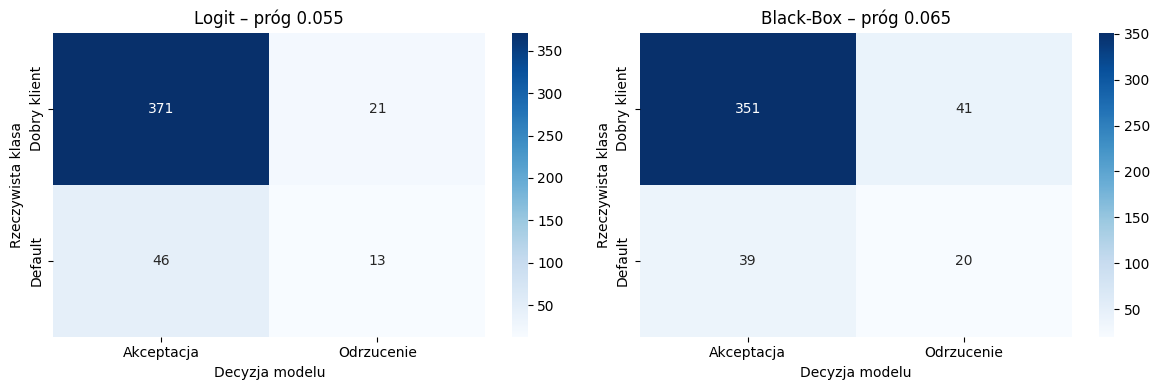

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (nazwa, p, prog) in zip(
    axes,
    [
        ("Logit", p_va_lg_4, prog_va_logit),
        ("Black-Box", p_va_bb_4, prog_va_bb)
    ]
):
    decyzja = (p >= prog).astype(int)

    cm = confusion_matrix(
        y_va_arr, decyzja, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Akceptacja", "Odrzucenie"],
        yticklabels=["Dobry klient", "Default"]
        , ax=ax
    )

    ax.set_title(f"{nazwa} – próg {prog:.3f}")
    ax.set_xlabel("Decyzja modelu")
    ax.set_ylabel("Rzeczywista klasa")

plt.tight_layout()
plt.show()

In [59]:
scenarios = {
    "Bardzo restrykcyjny": 0.02,
    "Restrykcyjny": 0.05,
    "Umiarkowany": 0.10,
    "Teoretyczny": p_star,
    "Liberalny": 0.25
}

wynik_scen = []

for model_name, p in models.items():

    for name_scen, prog in scenarios.items():

        wynik = ekonomia(
            y=y_va_arr,
            p=p,
            e=ead_val,
            prog=prog
        )

        wynik_scen.append({
            "Model": model_name,
            "Scenariusz": name_scen,
            "Próg PD": prog,
            "Stopa akceptacji": wynik["stopa akceptacji"],
            "DR przyjętych": wynik["DR wśród przyjętych"],
            "Oczekiwana strata": wynik["EL przyjętych (oczekiwana)"],
            "Zrealizowana strata": wynik["strata zrealizowana"],
            "Zysk": wynik["zysk"]
        })

tabela_biznesowa = pd.DataFrame(wynik_scen)

display(
    tabela_biznesowa.round(4)
)


,Model,Scenariusz,Próg PD,Stopa akceptacji,DR przyjętych,Oczekiwana strata,Zrealizowana strata,Zysk
0,Logit,Bardzo restrykcyjny,0.0200,0.1375,0.0806,0.4341,2.25,3.45
1,Logit,Restrykcyjny,0.0500,0.8891,0.1097,5.6364,19.80,15.90
2,Logit,Umiarkowany,0.1000,0.9778,0.1270,6.7426,25.20,13.30
3,Logit,Teoretyczny,0.1818,0.9845,0.1261,6.9455,25.20,13.60
4,Logit,Liberalny,0.2500,0.9911,0.1298,7.2403,26.10,12.80
5,Black-Box,Bardzo restrykcyjny,0.0200,0.3725,0.0476,1.0505,3.60,12.40
6,Black-Box,Restrykcyjny,0.0500,0.7095,0.0938,3.3935,13.50,15.50
7,Black-Box,Umiarkowany,0.1000,0.9401,0.1179,6.3577,22.50,14.90
8,Black-Box,Teoretyczny,0.1818,0.9933,0.1250,7.8211,25.20,14.00
9,Black-Box,Liberalny,0.2500,0.9978,0.1289,8.0051,26.10,13.10


## 9.6. Wnioski

- Podczas podziału na klasy ratingowe dla regresji zaobserwowano silną koncentrację w klasie A (ok. 75%). W takiej sytuacji bank miałby ograniczone możliwości różnicowania dużej ilości klientów, co uzasadniało podział na dodatkowe podklasy.

- Backtesting i jego wyniki wskazują na potrzebę kontroli klas, w których występują niezgodności pomiędzy średnim PD a rzeczywistym DR. Należy również uwzględniać liczebność poszczególnych klas, ponieważ niewielka liczba obserwacji i defaultów może prowadzić do niestabilnych wyników statystycznych.

- Zastosowanie marginesu konserwatyzmu pozwala ograniczyć ryzyko wynikające z niepewności oszacowań modelowych oraz potencjalnego niedoszacowania. Może to prowadzić do ograniczenia liczby udzielanych kredytów, ale także pomóc w bardziej ostrożnym podejmowaniu decyzji.

- Analiza macierzy pomyłek pozwala ocenić praktyczne konsekwencje zastosowania obu modeli przy podejmowaniu decyzji kredytowych.
Porównanie wyników wskazuje, że zmiana progu decyzyjnego wpływa bezpośrednio na liczbę zaakceptowanych wniosków oraz poziom ryzyka portfela. Niższy próg oznacza bardziej restrykcyjną politykę kredytową, ograniczającą liczbę zaakceptowanych klientów z defaultem, ale jednocześnie zmniejszającą liczbę klientów generujących potencjalny zysk.

# 10. Analiza kontrfaktyczna

Dla wybranej obserwacji z klasy B przeprowadzono analize kontrafaktyczną.

Według wykonanej wyżej analizy SHAP, najważniejszymi cechcami okazały się
- wskaźnik zadłużenia
- Aktywa
- Wskaźnik ROA
- Wskaźnik dni istnienia
Mają one istotny wpływ na predykcje i 3 z nich da się poprawić (oprócz dni istnienia).

Wybór obserwacji (liczności według modelu black-box)- chcemy przeanalizować klienta z PD jak najniższym, znajdującego się najbliżej granicy między ratingami B i BB. Dzięki temu możliwe jest zbadanie, czy niewielkie, ekonomicznie uzasadnione zmiany mogłyby doprowadzić do poprawy oceny kredytowej.

In [60]:
liczba_bb_bb = (pd.Series(r_val_bb) == "B").sum()

print(f"Liczba klientów w klasie B: {liczba_bb_bb}")

df_bb_analiza = pd.DataFrame({
    "PD_kalibrowane": p_va_bb_4,
    "Rating": r_val_bb
})

if isinstance(X_va, pd.DataFrame):
    df_bb_analiza = pd.concat([X_va.reset_index(drop=True), df_bb_analiza], axis=1)

top5_bb = df_bb_analiza[df_bb_analiza["Rating"] == "B"].sort_values(by="PD_kalibrowane", ascending=True).head(5)

print("\n5 klientów z najniższym szacowanym PD z klasy B (Black-box)")
display(top5_bb)

Liczba klientów w klasie B: 15

5 klientów z najniższym szacowanym PD z klasy B (Black-box)


,wsk_liczba_dni_istnienia,Aktywa,wsk_zadluzenia,wsk_plynnosc_biez_2,wsk_ROA,wsk_rotacja_aktywow_1,PD_kalibrowane,Rating
93,3420,307065.18,3.056711,1.327149,-0.227735,29.439718,0.136658,B
322,2806,1202841.76,505.993366,1.001976,0.000000,0.000000,0.138524,B
402,2022,202442.71,39.345879,22.308692,-0.140645,0.914068,0.142301,B
133,5290,1186878.92,74.094204,0.142074,-0.126311,1.020927,0.143386,B
236,2342,357510.37,70.502074,3512.603700,0.000000,0.173067,0.144135,B


Wybór to klient z numerem porządkowym 93 (pierwszy w tabeli), ponieważ jego PD (0.136658) jest najbliższe granicy następnej klasy (0.12).

In [61]:
chosen_one = top5_bb.iloc[0]
chosen_one_idx = top5_bb.index[0]
chosen_one_pd = chosen_one["PD_kalibrowane"]

print(f"Wybrana obserwacja: {chosen_one_idx}")
print(f"Wartość PD przed zmianą: {chosen_one_pd}")
print(f"Cechy:\n{chosen_one}")
goal_pd = 0.12

Wybrana obserwacja: 93
Wartość PD przed zmianą: 0.13665843376398618
Cechy:
wsk_liczba_dni_istnienia         3420
Aktywa                      307065.18
wsk_zadluzenia               3.056711
wsk_plynnosc_biez_2          1.327149
wsk_ROA                     -0.227735
wsk_rotacja_aktywow_1       29.439718
PD_kalibrowane               0.136658
Rating                              B
Name: 93, dtype: object


Chcemy, żeby nasza obserwacja wpadła do klasy BB => jej PD musi spaść poniżej 12%. Adaptujemy funkcję what-if z Labów 6.

Uwzględniamy trzy według SHAP cechy- wskaźnik roa, wskaźnik zadłużenia oraz aktywa.

In [62]:
# Adaptacja kodu z Lab 6, 6. What-if
KIERUNKI = {
    "wsk_zadluzenia": ("w dół", -0.005, 0.10),
    "wsk_ROA": ("w górę", 0.001, 0.20),
    "Aktywa": ("w górę", 5000.0, 1000000.0)
    }

def what_if(i, target = goal_pd, kierunki=KIERUNKI):
    x = X_va.iloc[[i]]
    wiersze = []
    for c, (kier, krok, granica) in kierunki.items():
        siatka = np.arange(x[c].iloc[0], granica + krok / 2, krok)

        B = pd.concat([x] * len(siatka), ignore_index=True)
        B[c] = siatka

        p = pd_bb_po_kalibracji(B, do_4proc=True)
        ok = np.flatnonzero(p < target)
        wiersze.append({"cecha": c,
                        "zmiana": kier,
                        "obecnie": x[c].iloc[0],
                        "najmniejsza wartość zmieniająca decyzję": siatka[ok[0]] if len(ok) else np.nan,
                        "PD po zmianie": p[ok[0]] if len(ok) else np.nan, "najniższe PD na siatce": p.min()})
    return pd.DataFrame(wiersze).set_index("cecha")

df_wyniki_awansu = what_if(chosen_one_idx)
display(df_wyniki_awansu.round(4))

,zmiana,obecnie,najmniejsza wartość zmieniająca decyzję,PD po zmianie,najniższe PD na siatce
cecha,,,,,
wsk_zadluzenia,w dół,3.0567,2.0817,0.0608,0.0594
wsk_ROA,w górę,-0.2277,0.0003,0.0950,0.0453
Aktywa,w górę,307065.1800,817065.1800,0.1167,0.1026


Dla wybranej firmy wyraźnie widać, że wszystkie czynniki, mogą realnie zaważyć na zmianie klasy na lepszą, więc da się ustalić zrównoważony plan działania dla firmy.

# Plan naprawczy

Na podstawie powyższej analizy ręcznie dobrane zostały zmiany wskaźników, prowadzące do poprawy. Jest to scenariusz modelowy, w praktyce ważne byłoby uwzględnienie zależności między cechami.

Plan {'wsk_zadluzenia': 2.3, 'Aktywa': 607065.18, 'wsk_ROA': 0.03}: PD 13.67% → 5.89%, klasa docelowa: ['BBB']
Categories (7, object): ['AAA' < 'AA' < 'A' < 'BBB' < 'BB' < 'B' < 'CCC'], decyzja: awans do BBB


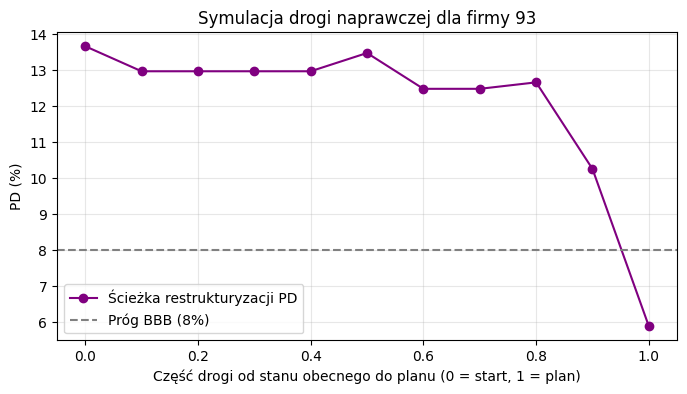

In [63]:
#Adaptacja z Lab 6
plan_zmiany = {
    "wsk_zadluzenia": 2.3,
    "Aktywa": 607065.1800,
    "wsk_ROA": 0.03
}

x4 = X_va.iloc[[chosen_one_idx]]
droga = pd.concat([x4] * 11, ignore_index=True)

for c, nowa in plan_zmiany.items():
    if c in X_va.columns:
        droga[c] = np.linspace(float(x4[c].iloc[0]), nowa, 11)
        if pd.api.types.is_integer_dtype(X_va[c]):
            droga[c] = droga[c].round()

pd_droga = pd_bb_po_kalibracji(droga, do_4proc=True)

ocena_koncowa = przypisz_rating_pd([pd_droga[-1]])[0]
print(f"Plan {plan_zmiany}: PD {pd_droga[0]:.2%} → {pd_droga[-1]:.2%}, klasa docelowa: {ocena_koncowa}, decyzja: {'awans do BBB' if pd_droga[-1] < 0.08 else 'nadal BB'}")

plt.figure(figsize=(8, 4))
plt.plot(np.linspace(0, 1, 11), 100 * pd_droga, "o-", color="purple", label="Ścieżka restrukturyzacji PD")
plt.axhline(100 * 0.08, ls="--", color="gray", label=f"Próg BBB (8%)")
plt.xlabel("Część drogi od stanu obecnego do planu (0 = start, 1 = plan)");
plt.ylabel("PD (%)")
plt.title(f"Symulacja drogi naprawczej dla firmy {chosen_one_idx}")
plt.legend();
plt.grid(alpha=0.3)
plt.show()

Przeprowadzona analiza prowadzi do wniosków, że firma powinna zająć się trzema obszarami w celu awansu:

- Redukcja zadłużenia: dzięki redukcji zadłużenia można zdecydowanie poprawić PD. Jest jednak ryzyko, że tak drastyczna poprawa może być spowodowana sztucznym progiem, nie należy więc skupiać się wyłącznie na tym aspekcie.

- Podniesienie ROA: na ten moment firma charakteryzuje się bardzo silnie ujemną rentownościa, więc podniesienie jej do zera, lub na bardzo niewielkie dodatnie wartości może dać ogromne rezultaty.

- Zwiększenie Aktywów: razem z pozostałymi zaleceniami wzmocnienie aktywów może zapewnić firmie awans.

# Porównanie z SHAP

Obserwacja 1445 default: 0 PD regresji: 0.1836 PD black-box surowe: 0.3684 PD black-box po 4%: 0.1367


,cecha,wartość,wkład logit regresji,TreeSHAP surowy black-box,Shapley końcowy black-box,row_index
4,wsk_ROA,-0.2277,0.4031,0.5045,0.5969,1445
2,wsk_zadluzenia,3.0567,-0.0179,0.5229,0.5471,1445
5,wsk_rotacja_aktywow_1,29.4397,0.0451,0.2843,0.2660,1445
1,Aktywa,307065.1800,0.0743,0.2494,0.1467,1445
3,wsk_plynnosc_biez_2,1.3271,-0.0200,0.0617,0.0807,1445
0,wsk_liczba_dni_istnienia,3420.0000,0.0528,-0.0186,-0.0223,1445


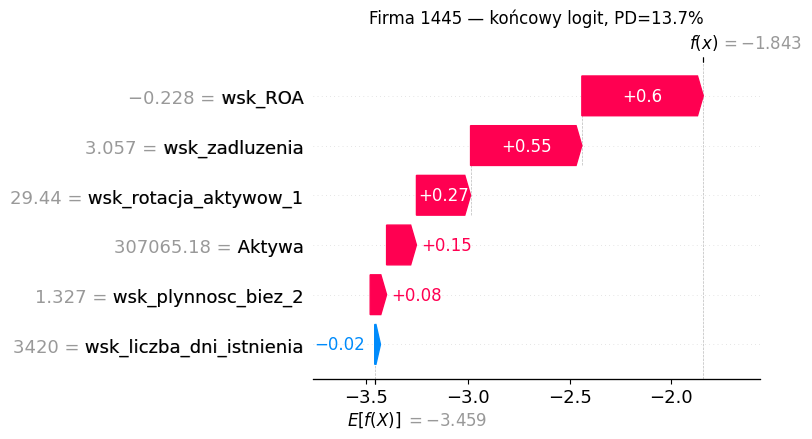

In [64]:
i = chosen_one_idx
phi, baza = shapley_dokladne(lambda X: _z(pd_koncowe(X)), X_va.iloc[i], TLO)
assert np.isclose(baza + phi.sum(), _z(pd_va_final[[i]])[0], atol=1e-7)
PHI_FINAL_CASES[i], BAZY_FINAL_CASES[i] = phi, baza
t = pd.DataFrame({"cecha": FEATURES, "wartość": X_va.iloc[i].to_numpy(),
                      "wkład logit regresji": PHI_LOG[i], "TreeSHAP surowy black-box": PHI_BB[i],
                      "Shapley końcowy black-box": phi.to_numpy()})
t["row_index"] = X_va.index[i]
local_rows.append(t)
print("Obserwacja", X_va.index[i], "default:", y_va.iloc[i],
          "PD regresji:", round(p_inter_val[i], 4),
          "PD black-box surowe:", round(P_MODELE["black-box"]["valid"][i], 4),
          "PD black-box po 4%:", round(pd_va_final[i], 4))
display(t.sort_values("Shapley końcowy black-box", ascending=False).round(4))
E = shap.Explanation(values=phi.to_numpy(), base_values=baza,
                         data=X_va.iloc[i].to_numpy(dtype=float), feature_names=FEATURES)
shap.plots.waterfall(E, max_display=len(FEATURES), show=False)
plt.title(f"Firma {X_va.index[i]} — końcowy logit, PD={pd_va_final[i]:.1%}")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / f"shap_final_case_{X_va.index[i]}.png", dpi=150, bbox_inches="tight")
plt.show()

Najważniejszy wniosek: oba warianty Black-Box wskazują bardzo podobne najważniejsze cechy i kierunki ich wkładu, natomiast regresja logistyczna inaczej ocenia część zmiennych.
Wyniki SHAP wskazały, że największy dodatni wkład do prognozowanego ryzyka miały wskaźnik rentowności aktywów ROA (+0,5969) oraz wskaźnik zadłużenia (+0,5471).

Wybór cech w analizie jest częściowo zgodny z lokalnymi wyjaśnieniami SHAP, które wskazały wybrane zmienne jako istotne dla tej firmy. W szczególności niska, ujemna wartość ROA oraz wysoki wkład wskaźnika zadłużenia wskazują na obszary, których poprawa może być istotna z punktu widzenia oceny ryzyka.

Kierunek i skuteczność proponowanych zmian zweryfikowano dodatkowo poprzez symulacje kontrfaktyczne z wykorzystaniem modelu. SHAP służył głównie do identyfikacji istotnych czynników ryzyka, natomiast analiza kontrfaktyczna pozwoliła sprawdzić, jakie zmiany wartości wybranych cech poprawią ocenę ratingową.

# Ograniczenia analizy kontrfaktycznej

Analiza kontrfaktyczna daje nam możliwość określić pożądane zmiany wartości wskaźników finansowych i cech firmy. Jest ona jednak oparta na modelu i nie daje gwarancji efektów, do których dąży firma.

Model nie identyfikuje związków przyczynowo-skutkowych i może być zawodny. Wskaźniki finansowe są ze sobą powiązane co może prowadzić do błędnych scenariuszy.

# 12. Równość i stabilność

W celu weryfikacji stabilności predykcyjnej oraz braku uprzedzeń modeli dokonano podziału zbioru walidacyjnego na trzy grupy według kwantyli dla kolejno wieku przedsiębiorstwa oraz aktywów.

In [70]:
audyt = X_va[["Aktywa"]].copy()
audyt["y"] = y_va.to_numpy()
audyt["pd_logit"] = p_inter_val
audyt["pd_bb"] = pd_koncowe(X_va)

# Podział na trzy grupy według kwantyli
audyt["grupa"] = pd.qcut(
    audyt["Aktywa"],
    q=3,
    labels=["Małe aktywa", "Średnie aktywa", "Duże aktywa"],
    duplicates="drop"
)

wyniki = []

for grupa, d in audyt.groupby("grupa", observed=True):
    y = d["y"]

    wiersz = {
        "grupa": str(grupa),
        "n": len(d),
        "defaulty": int(y.sum()),
        "DR": y.mean(),
        "PD Logit": d["pd_logit"].mean(),
        "Brier Logit": brier_score_loss(y, d["pd_logit"]),
        "PD BB": d["pd_bb"].mean(),
        "Brier BB": brier_score_loss(y, d["pd_bb"]),
        "AUC Logit": (
            roc_auc_score(y, d["pd_logit"])
            if y.nunique() == 2 else np.nan
        ),
        "AUC BB": (
            roc_auc_score(y, d["pd_bb"])
            if y.nunique() == 2 else np.nan
        )
    }

    wyniki.append(wiersz)

tabela_audytu = pd.DataFrame(wyniki)
display(tabela_audytu.round(4))

,grupa,n,defaulty,DR,PD Logit,Brier Logit,PD BB,Brier BB,AUC Logit,AUC BB
0,Małe aktywa,151,29,0.1921,0.1302,0.1531,0.0566,0.1680,0.6232,0.6375
1,Średnie aktywa,149,17,0.1141,0.1431,0.0991,0.0408,0.1010,0.7478,0.7201
2,Duże aktywa,151,13,0.0861,0.0963,0.0789,0.0226,0.0826,0.5909,0.5619


Modele wykazują najwyższą skuteczność w ocenie średnich, co do posiadanych aktywów przedsiębiorstw (AUC ok. 0,72). W grupie największych podmiotów AUC spada, co wynika z niskiej częstości zdarzeń i większej jednorodności. Nie jest dla nich widoczny błąd kalibracji (wskaźnik Brier osiąga tu najniższe, najkorzystniejsze wartości).

In [73]:
audyt_2 = X_va[["wsk_liczba_dni_istnienia"]].copy()
audyt_2["y"] = y_va.to_numpy()
audyt_2["pd_logit"] = p_inter_val
audyt_2["pd_bb"] = pd_koncowe(X_va)

audyt_2["grupa"] = pd.qcut(
    audyt_2["wsk_liczba_dni_istnienia"],
    q=3,
    labels=["Krótki staż", "Średni staż", "Długi staż"],
    duplicates="drop"
)

wyniki_2 = []

for grupa, d in audyt.groupby("grupa", observed=True):
    y = d["y"]

    wiersz = {
        "grupa": str(grupa),
        "n": len(d),
        "defaulty": int(y.sum()),
        "DR": y.mean(),
        "PD Logit": d["pd_logit"].mean(),
        "Brier Logit": brier_score_loss(y, d["pd_logit"]),
        "PD BB": d["pd_bb"].mean(),
        "Brier BB": brier_score_loss(y, d["pd_bb"]),
        "AUC Logit": (
            roc_auc_score(y, d["pd_logit"])
            if y.nunique() == 2 else np.nan
        ),
        "AUC BB": (
            roc_auc_score(y, d["pd_bb"])
            if y.nunique() == 2 else np.nan
        )
    }

    wyniki_2.append(wiersz)

tabela_audytu_2 = pd.DataFrame(wyniki_2)
display(tabela_audytu_2.round(4))

,grupa,n,defaulty,DR,PD Logit,Brier Logit,PD BB,Brier BB,AUC Logit,AUC BB
0,Krótki staż,150,26,0.1733,0.1557,0.1406,0.0537,0.1518,0.6669,0.6438
1,Średni staż,151,20,0.1325,0.1233,0.1108,0.0399,0.1196,0.6897,0.6588
2,Długi staż,150,13,0.0867,0.0903,0.0799,0.0264,0.0804,0.5592,0.6244


Dla firm o krótkim i średnim stażu oba modele osiągają zbliżone AUC (0,64–0,69). W grupie przedsiębiorstw o długim stażu model Black-Box wykazuje wyraźną przewagę nad regresją logistyczną (AUC 0,6244 wobec 0,5592), co dowodzi, że niewypłacalność dojrzałych podmiotów wynika ze złożonych, nieliniowych zależności, których model liniowy nie jest w stanie wychwycić.

# 11. Ocena na zbiorze testowym

Zbiór testowy nie był wykorzystywany aż do momentu oceny modeli i podjęcia decyzji. Obejmuje on 450 obserwacji, wśród których rzeczywisty udział przedsiębiorstw z defaultem wyniósł 12,89%.

In [66]:
assert X_test.index.equals(y_test.index)
assert set(CECHY_LOGIT).issubset(X_test.columns)
assert set(FEATURES).issubset(X_test.columns)

pd_test_logit = model_inter.predict_proba(
    X_test[CECHY_LOGIT]
)[:, 1]

pd_test_bb = pd_koncowe(X_test[FEATURES])
pd_test_bb_bez4 = pd_bb_po_kalibracji(
    X_test,
    do_4proc=False
)

assert np.isfinite(pd_test_logit).all()
assert np.isfinite(pd_test_bb).all()
assert ((pd_test_logit >= 0) & (pd_test_logit <= 1)).all()
assert ((pd_test_bb >= 0) & (pd_test_bb <= 1)).all()

print("Liczba obserwacji testowych:", len(y_test))
print("Rzeczywisty DR test:", round(y_test.mean(), 4))
print("Średnia PD Logit:", round(pd_test_logit.mean(), 4))
print("Średnia PD Black-Box:", round(pd_test_bb_bez4.mean(), 4))
print("Średnia PD Black-Box (PD 4%):", round(pd_test_bb.mean(), 4))

Liczba obserwacji testowych: 450
Rzeczywisty DR test: 0.1289
Średnia PD Logit: 0.1386
Średnia PD Black-Box: 0.1365
Średnia PD Black-Box (PD 4%): 0.0446


In [67]:
wyniki_test = pd.DataFrame({
    "Logit": ocena(y_test, pd_test_logit),
    "Black-Box": ocena(y_test, pd_test_bb_bez4),
    "Black-Box (PD 4%)": ocena(y_test, pd_test_bb)
}).T

display(wyniki_test.round(4))
wyniki_test.to_csv(
    ARTIFACT_DIR / "wyniki_test_porownanie.csv"
)

,AUC,Gini,KS,PR-AUC (AP),log-loss,Brier,średnia PD,default rate
Logit,0.6404,0.2809,0.2397,0.2301,0.3745,0.1110,0.1386,0.1289
Black-Box,0.7180,0.4360,0.3626,0.2644,0.3502,0.1051,0.1365,0.1289
Black-Box (PD 4%),0.7180,0.4360,0.3626,0.2644,0.4097,0.1142,0.0446,0.1289


Wyniki wskazują na przewagę modelu Black-Box pod względem zdolności do różnicowania przedsiębiorstw według poziomu ryzyka. Model osiągnął AUC na poziomie 0,7180, Gini równy 0,4360 oraz KS równy 0,3626 (zarówno z jak i bez kalibracji do 4% PD), a dla regresji logistycznej wartości te wyniosły odpowiednio 0,6404, 0,2809 i 0,2397. Przewaga Black-Box wystąpiła również w zakresie Average Precision.

In [68]:
PROG_LOGIT = prog_va_logit
PROG_BB = prog_va_bb

assert 0 < PROG_LOGIT < 1
assert 0 < PROG_BB < 1

from sklearn.metrics import confusion_matrix

def raport_decyzji(y_true, pd_pred, prog, nazwa):
    decyzja = (pd_pred >= prog).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, decyzja, labels=[0, 1]
    ).ravel()

    return {
        "model": nazwa,
        "próg": prog,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "liczba_obserwacji": len(y_true),
        "defaulty wykryte": tp,
        "defaulty niewykryte": fn,
        "fałszywe alarmy": fp,
        "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
    }

decyzje_test = pd.DataFrame([
    raport_decyzji(
        y_test, pd_test_logit, PROG_LOGIT, "Logit"
    ),
    raport_decyzji(
        y_test, pd_test_bb_bez4, PROG_BB, "Black-Box"
    ),
    raport_decyzji(
        y_test, pd_test_bb, PROG_BB, "Black-Box (PD 4%)"
    )
]).set_index("model")

display(decyzje_test.round(4))
decyzje_test.to_csv(
    ARTIFACT_DIR / "decyzje_test_macierze.csv"
)

,próg,TN,FP,FN,TP,liczba_obserwacji,defaulty wykryte,defaulty niewykryte,fałszywe alarmy,sensitivity,specificity
model,,,,,,,,,,,
Logit,0.055,25,367,0,58,450,58,0,367,1.0000,0.0638
Black-Box,0.065,131,261,2,56,450,56,2,261,0.9655,0.3342
Black-Box (PD 4%),0.065,334,58,39,19,450,19,39,58,0.3276,0.8520


Porównanie decyzji przy ustalonych progach pokazało duże różnice w operowaniu modeli. Regresja wykryła wszystkie wystąpienia defaultu, ale błędnie oceniła ponad 350 firm. Mimo ogromnej sensivity, widać bardzo niską specificity.

Modele Black-box mimo, że nie wykryły wszystkich defaultów dają dobre wyniki. W zależności od kosztów i celów przedsiębiorstwa można zastanawiać sie czy lepsze jest bardziej konserwatywne podejście bez ustalonego PD 4%, czy jednak lepiej nie odrzucać tak wielu firm i ten próg ustalić. Jasno widać jednak, że mimo trudniejszej wyjaśnialności model Black-boxowy w tym przypadku sprawdza sie lepiej.